# Imports

## Import the folder for compatibility (if running local)

In [2]:
import os
import sys

project_root = "Incremental-Learning-MycroftMinds"
cwd = os.path.abspath(os.getcwd())
while True:
    if os.path.basename(cwd) == project_root:
        if cwd not in sys.path:
            sys.path.insert(0, cwd)
        break
    parent = os.path.dirname(cwd)
    if parent == cwd:
        raise FileNotFoundError(f"Project root '{project_root}' not found in any parent directory.")
    cwd = parent

## Import external libs and internal models

In [3]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm

from src.data.io import load_dataset
from src.utils.memory import calculate_memory_usage
from src.utils.utils import get_device_data
from src.evaluation.metrics import calculate_metrics, all_time_aggregation_metrics
from src.evaluation.visualization import plot_part_predictions, plot_hourly_predictions
from src.evaluation.training import all_valid_splits_seq_fit_predict, test_set_seq_fit_predict

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from river.forest import ARFRegressor
from river.tree import HoeffdingTreeRegressor
from src.evaluation.baseline import PreviousValueRegressor, SeasonalMeanRegressor
from src.trees import fastodt
from src.trees import xfastodt
from src.bagging import ARFRegressorFODT
from src.boosting import IncubationBoost
from src.ensemble_methods.IncubationBoostWeightedRatio import IncubationBoostWeightedRatio
from src.ensemble_methods.IncubationBoostElastic import IncubationBoostElastic

import ipywidgets as widgets
widgets.IntSlider()

# Download the splitted data

In [4]:
# check you data dir and file prefixes
data_dir = '../../data/second_batch/industrial'

## Evaluation Settings

In [4]:
DATA_FREQUENCY = 'H'  # 1-Hour frequency
USE_RESIDUAL = True  # If True, model the residuals (1-step differencing) instead of the original target.
FORECAST_HORIZON = '1h'  # 1-Hour forecast horizon
SPIKE_PROMINENCE = 3.5  # For industrial data

In [6]:
# Measure loading time
start_time = time.time()

# Load data
train, valid, test = load_dataset(data_dir=data_dir, prefix='sb_ind_hour_wfv', use_numpy=True)
ALL_FEATURES = ['time', 'device_id', 'hour', 'weekday', 'month', 
           'consumption_lag_1h', 'consumption_lag_2h', 'consumption_lag_24h', 'consumption_lag_25h']

loading_time = time.time() - start_time
print(f"Data loaded in {loading_time/60:.2f} minutes")

## Data structure information

The data structure is as follows:
- For walk-forward validation:
  - `train` is a list of tuples, where each tuple is (X, y) for one split
  - `valid` is a list of tuples, where each tuple is (X, y) for one split
  - `test` is a tuple of (X, y)
- Each X array contains:
  - Column 0: `time` (`pandas.Timedelta`)
  - Column 1: `device_id` (`str`)
  - Other columns: time-related features and lag features

The memory usage of the loaded data is printed below:

In [ ]:
# Print data structure and memory usage information
if isinstance(train, list):
    print(f"Training data: {len(train)} splits")
    print(f"Validation data: {len(valid)} splits")
    
    # Show first split shape
    print(f"First train split shape: X={train[0][0].shape}, y={train[0][1].shape}")
    print(f"First valid split shape: X={valid[0][0].shape}, y={valid[0][1].shape}")
    
    # Memory usage
    train_mem = sum(calculate_memory_usage(ts) for ts in train)
    valid_mem = sum(calculate_memory_usage(vs) for vs in valid)
    test_mem = calculate_memory_usage(test)
    
    print(f"\nMemory usage:")
    print(f"Train: {train_mem:.2f} MB")
    print(f"Valid: {valid_mem:.2f} MB")
    print(f"Test: {test_mem:.2f} MB")
    print(f"Total: {train_mem + valid_mem + test_mem:.2f} MB")
else:
    # For non-list structure
    print(f"Training data shape: X={train[0].shape}, y={train[1].shape}")
    print(f"Validation data shape: X={valid[0].shape}, y={valid[1].shape}")
    print(f"Test data shape: X={test[0].shape}, y={test[1].shape}")

# WFV Models Evaluation
(train+valid WFV)
- (1) `train[0]` vs `valid[0]`
- (2) `train[1]` vs `valid[1]`
- ...
- (n) `train[n]` vs `valid[n]`

, where: 
$$ train[1] = train[0]+valid[0] $$
$$...$$
$$ train[n] = train[0]+valid[0]+valid[1]+...+valid[n-1] $$

## Hourly granularity

### Baseline model (seasonal averages)

In [7]:
update_freq = "14D"
bl_mean = SeasonalMeanRegressor
bl_mean_params = {}

In [8]:
bl_mean_train_period_predictions, bl_mean_valid_period_predictions,\
bl_mean_train_period_metrics, bl_mean_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=bl_mean,
    model_params=bl_mean_params,
    train=train,
    valid=valid,
    use_residuals=USE_RESIDUAL,
    incremental=False,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    verbose=True
)

#### Results

In [ ]:
print("\n\nValid period metrics:")
bl_mean_all_time_valid_metrics = all_time_aggregation_metrics(bl_mean_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Valid period metrics:


Aggregated Metrics Across Periods
Device ID: site1
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0568 ± 0.0092
	MAE: 0.0379 ± 0.0066
	MAPE: 14.9814% ± 2.9905%

	Directional Metrics:
		Directional Accuracy: 56.9355% ± 3.5743%
		First-Diff Correlation: 0.3865 ± 0.0908

	Immediate Detection (delta=0):
		Spike Precision: 0.2407 ± 0.1164
		Spike Recall: 0.2703 ± 0.1303
		Spike F1: 0.2524 ± 0.1200
		Drop Precision: 0.1231 ± 0.0917
		Drop Recall: 0.1370 ± 0.1010
		Drop F1: 0.1280 ± 0.0930

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.6399 ± 0.1532
		Spike Recall: 0.7126 ± 0.1476
		Spike F1: 0.6675 ± 0.1350
		Drop Precision: 0.4631 ± 0.1696
		Drop Recall: 0.4964 ± 0.1327
		Drop F1: 0.4736 ± 0.1414
Daily Metrics:
	RMSE: 0.0753 ± 0.0503
	MAE: 0.0550 ± 0.0392
	MAPE: 0.9071% ± 0.3297%

	Directional Metrics:
		Directional Accuracy: 97.4612% ± 3.4233%
		First-Diff Correlation: 0.9979 ± 0.0019

	Immediate Detection (delta=0):
		Spik

#### Validation plots

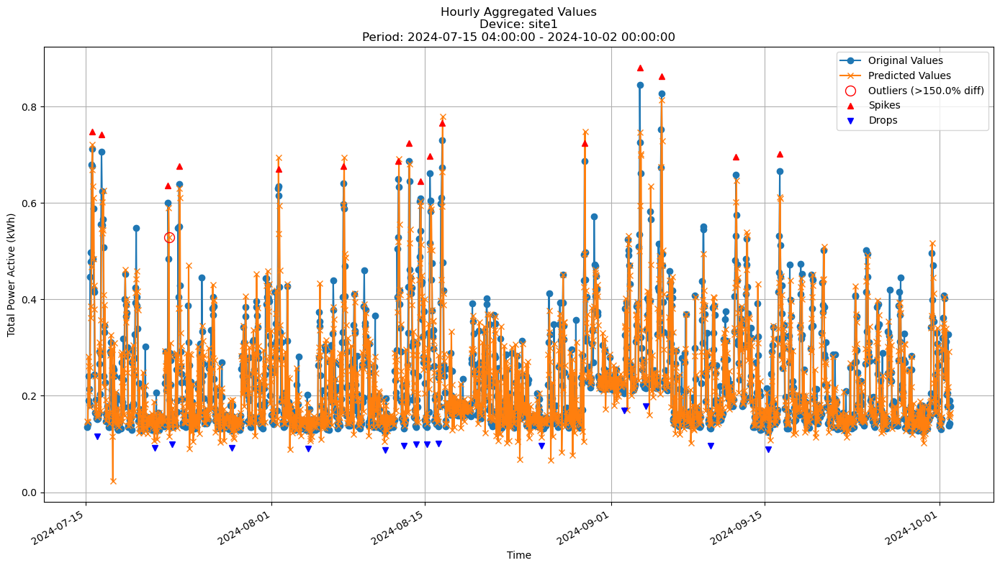


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0625
MAE: 0.0395
MAPE: 16.1876%

Directional Metrics:
Directional Accuracy: 51.1099%
First-Diff Correlation: 0.2893

Immediate Detection (delta=0):
Spikes:
  Precision: 0.2353
  Recall: 0.2500
  F1 Score: 0.2424
Drops:
  Precision: 0.0625
  Recall: 0.0667
  F1 Score: 0.0645

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8235
  Recall: 0.8750
  F1 Score: 0.8485
Drops:
  Precision: 0.2500
  Recall: 0.2667
  F1 Score: 0.2581


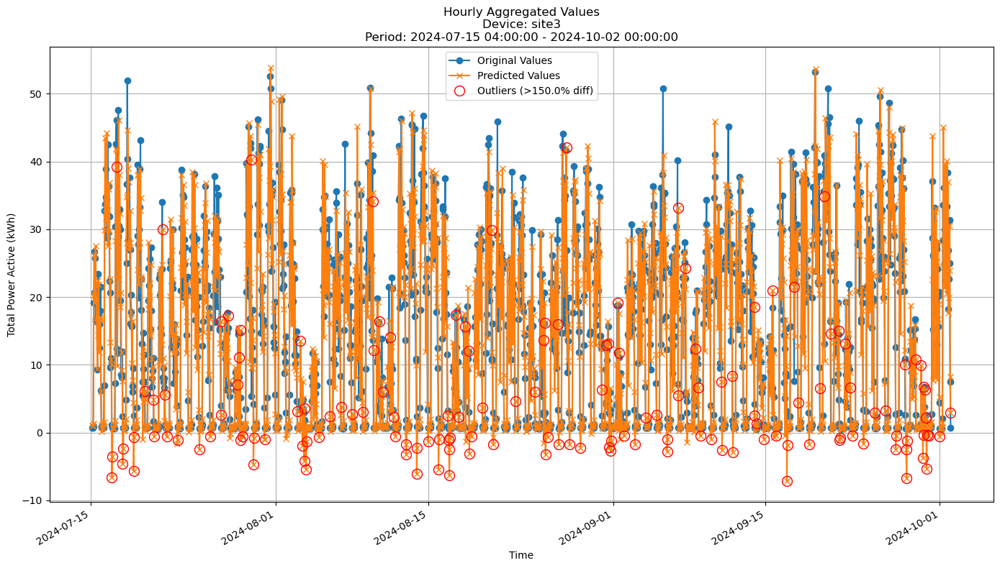


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 6.4630
MAE: 4.2877
MAPE: 56.6631%

Directional Metrics:
Directional Accuracy: 46.6173%
First-Diff Correlation: 0.2615

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


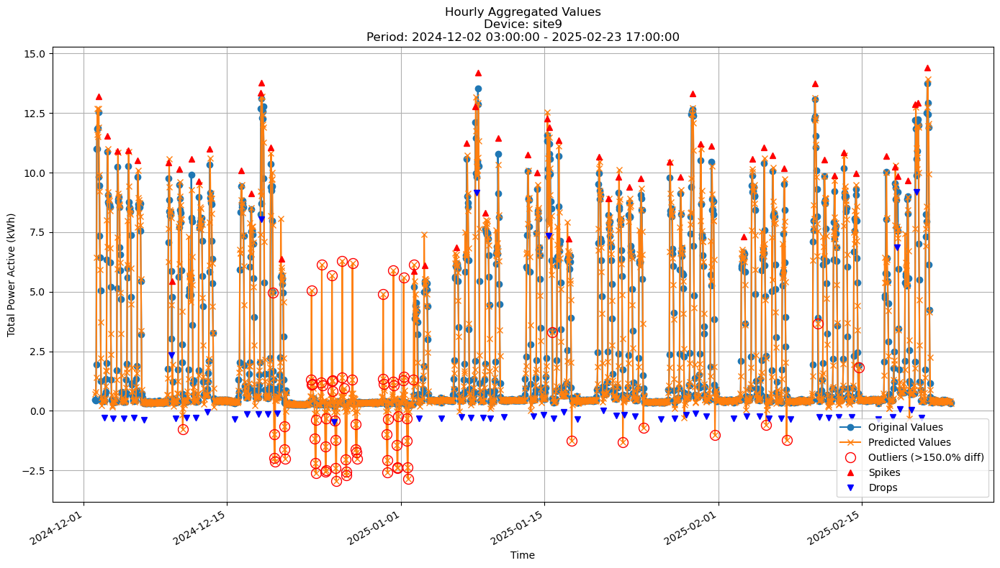


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.9071
MAE: 0.4202
MAPE: 39.1434%

Directional Metrics:
Directional Accuracy: 51.1466%
First-Diff Correlation: 0.5689

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0556
  Recall: 0.0690
  F1 Score: 0.0615
Drops:
  Precision: 0.0704
  Recall: 0.0877
  F1 Score: 0.0781

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7083
  Recall: 0.8793
  F1 Score: 0.7846
Drops:
  Precision: 0.3662
  Recall: 0.4561
  F1 Score: 0.4062


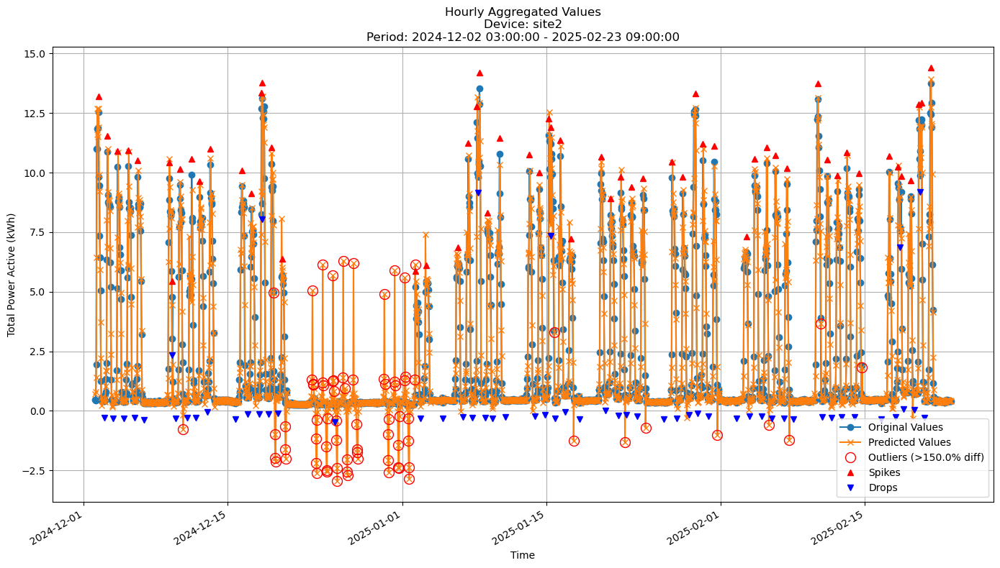


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.9089
MAE: 0.4217
MAPE: 39.2591%

Directional Metrics:
Directional Accuracy: 51.2012%
First-Diff Correlation: 0.5689

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0556
  Recall: 0.0690
  F1 Score: 0.0615
Drops:
  Precision: 0.0704
  Recall: 0.0877
  F1 Score: 0.0781

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7083
  Recall: 0.8793
  F1 Score: 0.7846
Drops:
  Precision: 0.3662
  Recall: 0.4561
  F1 Score: 0.4062


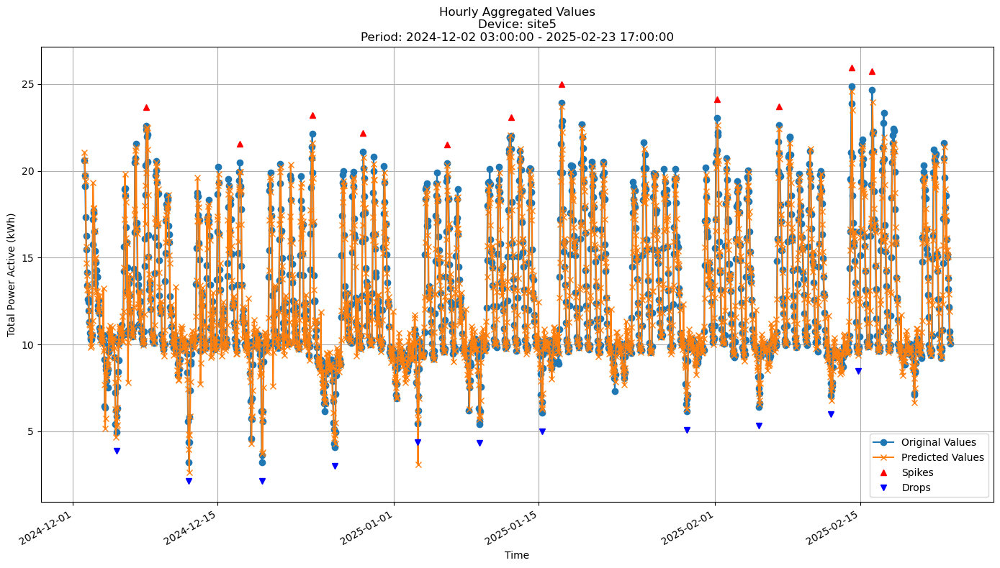


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.1285
MAE: 0.8208
MAPE: 6.4781%

Directional Metrics:
Directional Accuracy: 61.9143%
First-Diff Correlation: 0.3968

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 0.0909
  F1 Score: 0.1667
Drops:
  Precision: 1.0000
  Recall: 0.1818
  F1 Score: 0.3077


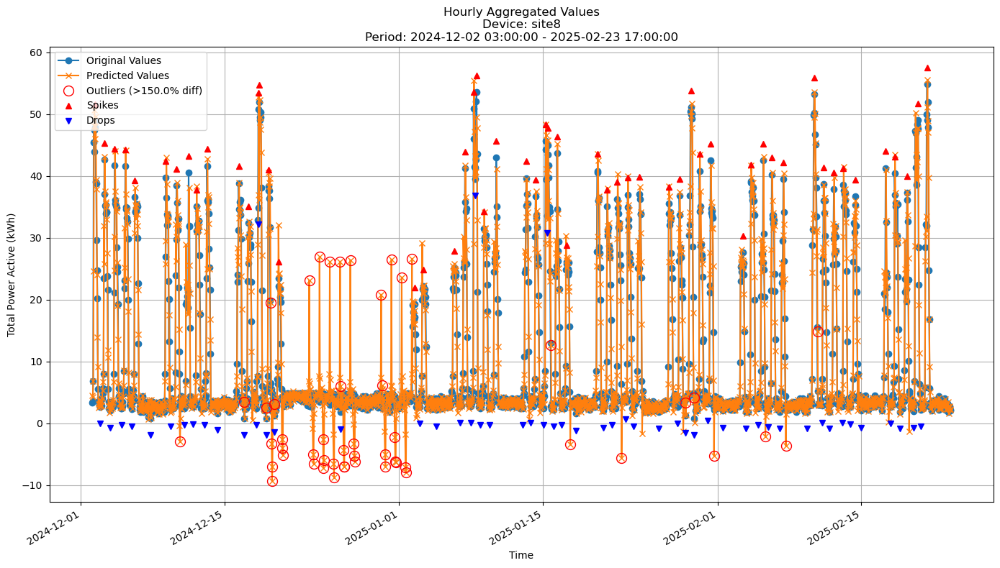


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 3.7315
MAE: 1.9679
MAPE: 30.0459%

Directional Metrics:
Directional Accuracy: 47.0588%
First-Diff Correlation: 0.5349

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0794
  Recall: 0.0909
  F1 Score: 0.0847
Drops:
  Precision: 0.0161
  Recall: 0.0185
  F1 Score: 0.0172

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7619
  Recall: 0.8727
  F1 Score: 0.8136
Drops:
  Precision: 0.3065
  Recall: 0.3519
  F1 Score: 0.3276


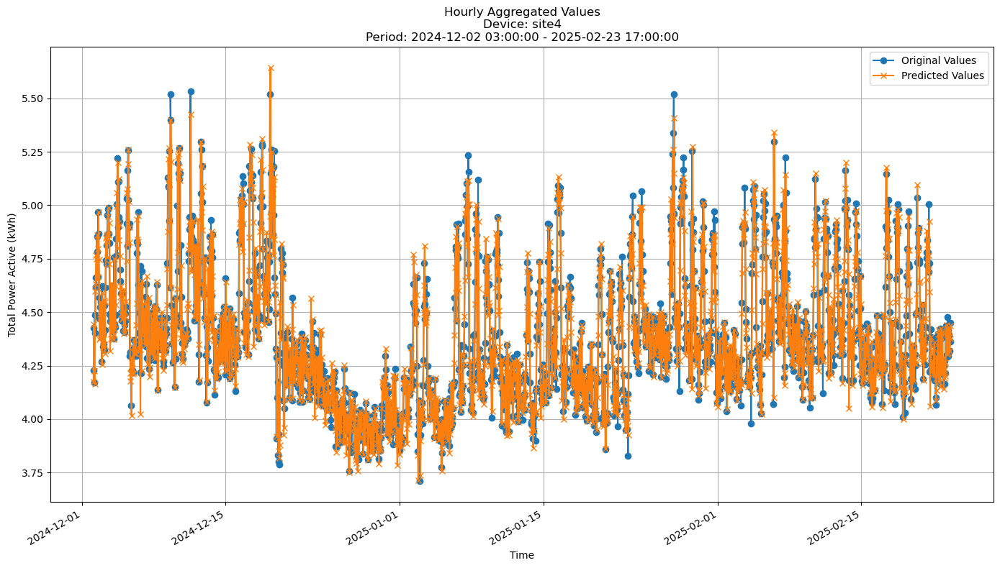


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1754
MAE: 0.1294
MAPE: 2.9219%

Directional Metrics:
Directional Accuracy: 36.2413%
First-Diff Correlation: -0.2633

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [ ]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in bl_mean_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, bl_mean_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, bl_mean_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5,
                            )

### Baseline model (predict previous value)

In [11]:
update_freq = "1H"
bl_prev = PreviousValueRegressor
bl_prev_params = {'is_residual': True}

In [12]:
bl_prev_train_period_predictions, bl_prev_valid_period_predictions,\
bl_prev_train_period_metrics, bl_prev_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=bl_prev,
    model_params=bl_prev_params,
    train=train,
    valid=valid,
    use_residuals=USE_RESIDUAL,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    verbose=True
)

Processing splits:   0%|          | 0/25 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/2 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 04:00:00+01:00 to 2023-03-27 03:00:00+02:00
Model's memory usage: 0.000488 MB
Metrics for Device: site1 | Period: 2023-03-27 04:00:00+02:00 - 2023-04-24 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0783
	MAE: 0.0527
	MAPE: 19.0481%

Directional Metrics:
	Directional Accuracy: 49.7765%
	First-Diff Correlation: -0.0117

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.9583
		Recall: 1.0000
		F1: 0.9787
	Drops:
		Precision: 0.9565
		Recall: 1.0000
		F1: 0.9778
--------------------------------------------------
Da

Processing devices in split 1:   0%|          | 0/2 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 04:00:00+01:00 to 2023-04-24 03:00:00+02:00
Model's memory usage: 0.000473 MB
Metrics for Device: site1 | Period: 2023-04-24 04:00:00+02:00 - 2023-05-22 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0604
	MAE: 0.0385
	MAPE: 18.1361%

Directional Metrics:
	Directional Accuracy: 41.7288%
	First-Diff Correlation: -0.2240

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Da

Processing devices in split 2:   0%|          | 0/2 [00:00<?, ?it/s]

... (41 outputs left out)

Processing devices in split 23:   0%|          | 0/7 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 13:00:00+02:00 to 2024-12-30 02:00:00+01:00
Model's memory usage: 0.000290 MB
Metrics for Device: site9 | Period: 2024-12-30 03:00:00+01:00 - 2025-01-27 02:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.2118
	MAE: 0.4857
	MAPE: 22.5320%

Directional Metrics:
	Directional Accuracy: 51.1177%
	First-Diff Correlation: 0.2656

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Dai

Processing devices in split 24:   0%|          | 0/7 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 13:00:00+02:00 to 2025-01-27 02:00:00+01:00
Model's memory usage: 0.000290 MB
Metrics for Device: site9 | Period: 2025-01-27 03:00:00+01:00 - 2025-02-23 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.4321
	MAE: 0.6436
	MAPE: 25.8170%

Directional Metrics:
	Directional Accuracy: 52.5680%
	First-Diff Correlation: 0.2853

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Dai

#### Results

In [ ]:
print("\n\nValid period metrics:")
bl_prev_all_time_valid_metrics = all_time_aggregation_metrics(bl_prev_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Valid period metrics:


Aggregated Metrics Across Periods
Device ID: site1
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0721 ± 0.0085
	MAE: 0.0470 ± 0.0072
	MAPE: 17.6682% ± 2.2495%

	Directional Metrics:
		Directional Accuracy: 44.6712% ± 3.5092%
		First-Diff Correlation: -0.0971 ± 0.0960

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.9829 ± 0.0479
		Spike Recall: 0.9972 ± 0.0093
		Spike F1: 0.9893 ± 0.0262
		Drop Precision: 0.9978 ± 0.0095
		Drop Recall: 0.9971 ± 0.0096
		Drop F1: 0.9974 ± 0.0066
Daily Metrics:
	RMSE: 0.0722 ± 0.0497
	MAE: 0.0505 ± 0.0388
	MAPE: 0.7561% ± 0.2958%

	Directional Metrics:
		Directional Accuracy: 98.0357% ± 3.2878%
		First-Diff Correlation: 0.9981 ± 0.0017

	Immediate Detection (delta=0):
		Spi

#### Validation plots

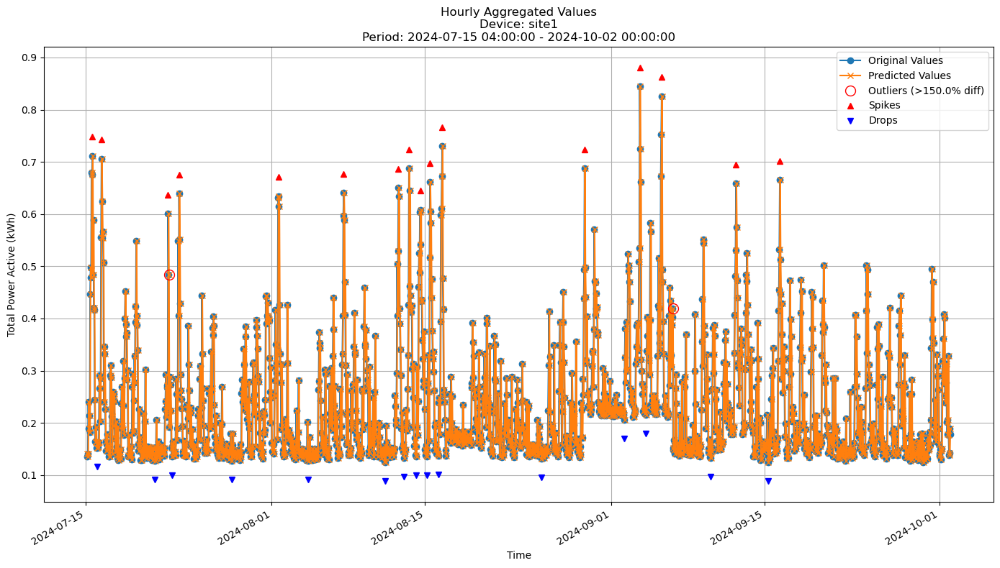


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0706
MAE: 0.0462
MAPE: 19.0152%

Directional Metrics:
Directional Accuracy: 42.0719%
First-Diff Correlation: -0.0916

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000


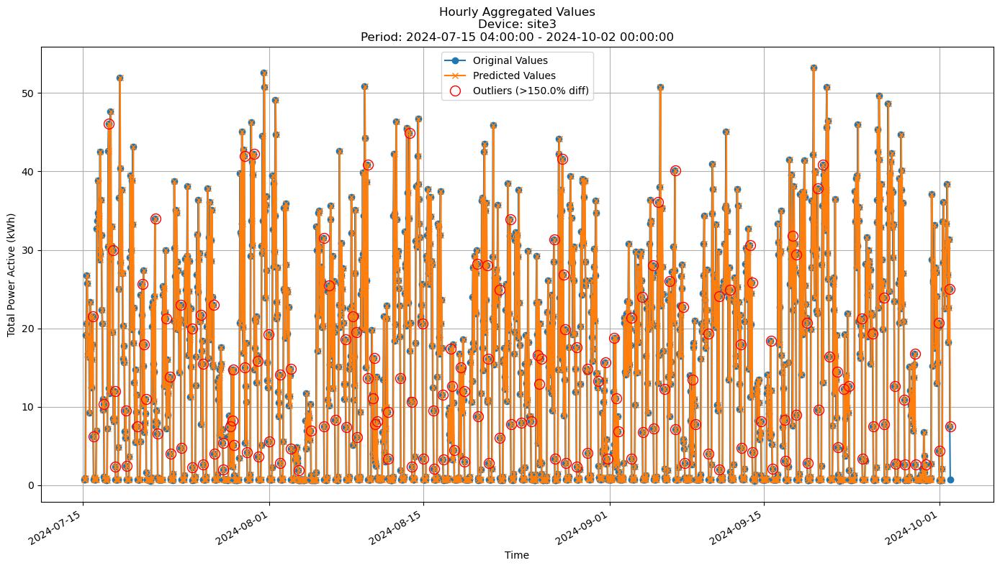


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 8.5881
MAE: 5.4868
MAPE: 64.5183%

Directional Metrics:
Directional Accuracy: 45.8245%
First-Diff Correlation: -0.0977

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


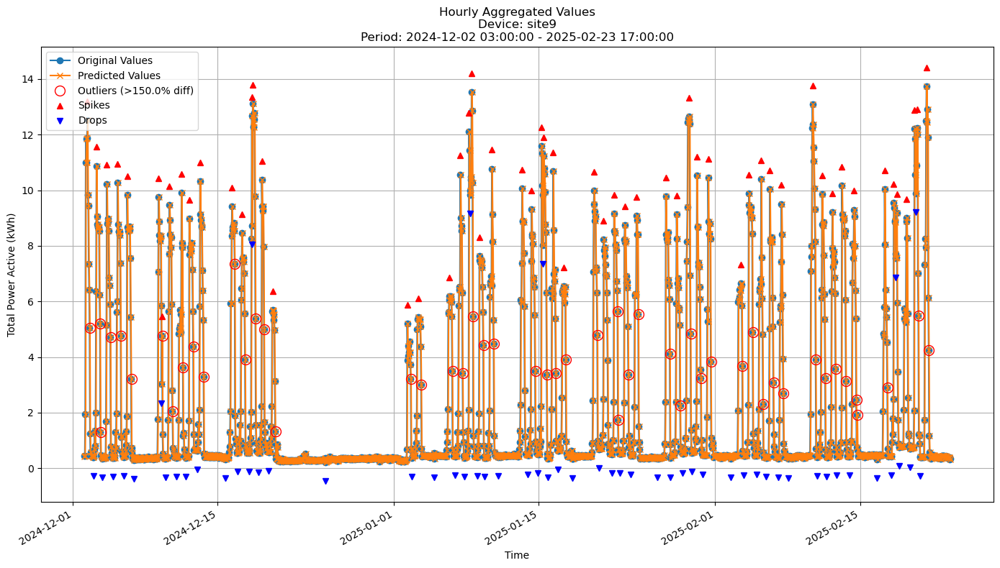


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.2977
MAE: 0.5397
MAPE: 24.0322%

Directional Metrics:
Directional Accuracy: 47.6072%
First-Diff Correlation: 0.2728

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000


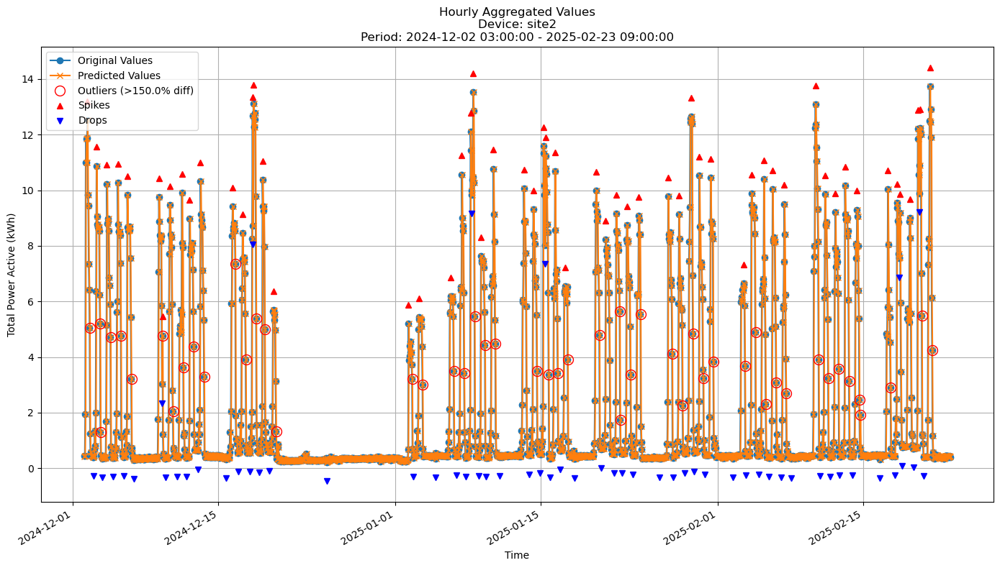


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.3003
MAE: 0.5418
MAPE: 24.0907%

Directional Metrics:
Directional Accuracy: 47.6476%
First-Diff Correlation: 0.2728

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000


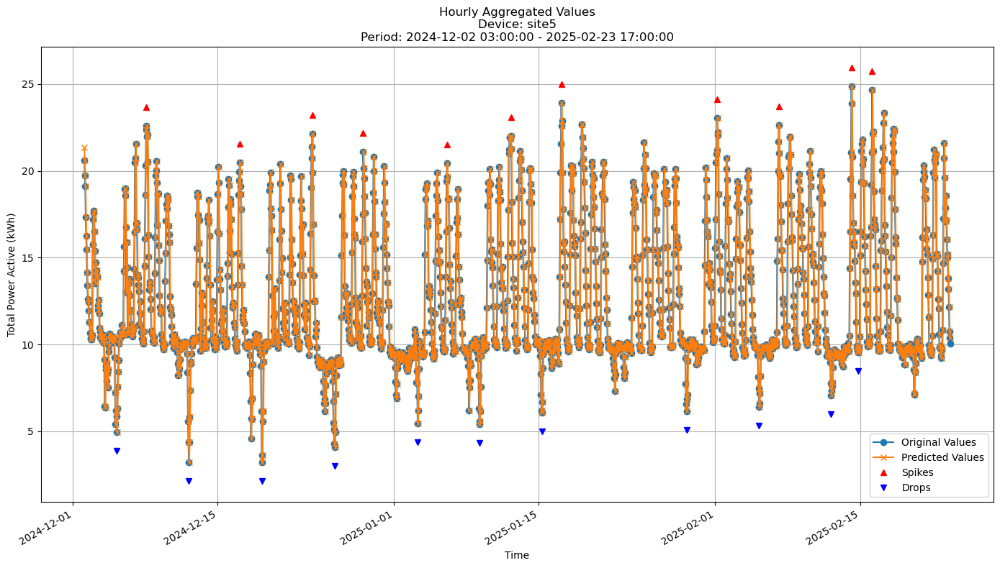


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.2851
MAE: 0.8559
MAPE: 6.5353%

Directional Metrics:
Directional Accuracy: 61.3161%
First-Diff Correlation: 0.4708

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000


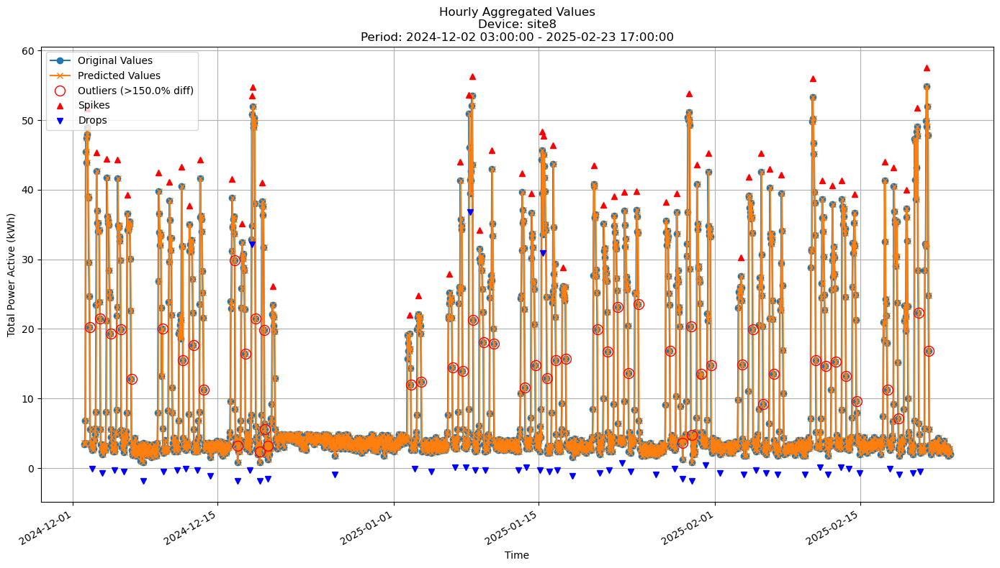


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 5.2299
MAE: 2.4375
MAPE: 29.7593%

Directional Metrics:
Directional Accuracy: 43.9182%
First-Diff Correlation: 0.2371

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000


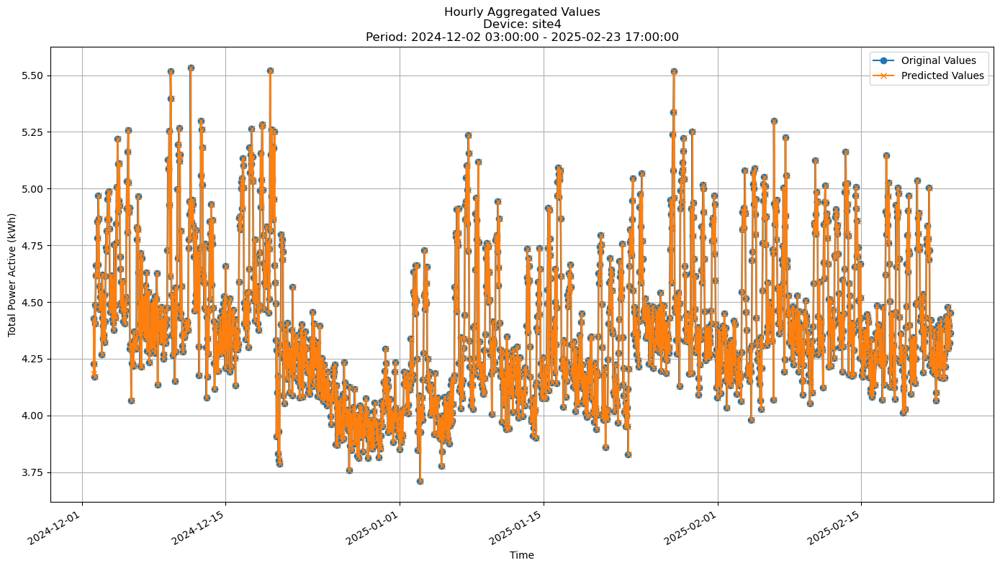


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1841
MAE: 0.1346
MAPE: 3.0333%

Directional Metrics:
Directional Accuracy: 35.3440%
First-Diff Correlation: -0.2873

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [ ]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in bl_prev_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, bl_prev_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, bl_prev_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5,
                            )

### GBDT

In [15]:
update_freq = "14D"  # Update the model every 14 days
gbdt = GradientBoostingRegressor
gbdt_params = {
    'n_estimators': 150, 
     'learning_rate': 0.05, 
     'max_depth': 7, 
     'subsample': 0.8, 
     'random_state': 42
}

In [16]:
gbdt_train_period_predictions, gbdt_valid_period_predictions, \
gbdt_train_period_metrics, gbdt_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=gbdt,
    model_params=gbdt_params,
    train=train, 
    valid=valid, 
    use_residuals=USE_RESIDUAL,
    incremental=False,
    data_freq=DATA_FREQUENCY, 
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/25 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/2 [00:00<?, ?it/s]


Retraining model on data from 2023-02-27 04:00:00+01:00 to 2023-03-27 03:00:00+02:00

Time: 0.29 seconds
Predicting for chunk from 2023-03-27 04:00:00+02:00 to 2023-04-10 04:00:00+02:00

-------------------------

Retraining model on data from 2023-02-27 04:00:00+01:00 to 2023-04-10 04:00:00+02:00

Time: 0.41 seconds
Predicting for chunk from 2023-04-10 05:00:00+02:00 to 2023-04-24 03:00:00+02:00

-------------------------
Model's memory usage: 0.011864 MB
Metrics for Device: site1 | Period: 2023-03-27 04:00:00+02:00 - 2023-04-24 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0545
	MAE: 0.0394
	MAPE: 16.0283%

Directional Metrics:
	Directional Accuracy: 64.2325%
	First-Diff Correlation: 0.4784

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.4286
		Recall: 0.3913
		F1: 0.4091
	Drops:
		Precision: 0.1000
		Recall: 0.0909
		F1: 0.0952

Delayed Detection (delta=

Processing devices in split 1:   0%|          | 0/2 [00:00<?, ?it/s]


Retraining model on data from 2023-02-27 04:00:00+01:00 to 2023-04-24 03:00:00+02:00

Time: 0.50 seconds
Predicting for chunk from 2023-04-24 04:00:00+02:00 to 2023-05-08 04:00:00+02:00

-------------------------

Retraining model on data from 2023-02-27 04:00:00+01:00 to 2023-05-08 04:00:00+02:00

Time: 0.59 seconds
Predicting for chunk from 2023-05-08 05:00:00+02:00 to 2023-05-22 03:00:00+02:00

-------------------------
Model's memory usage: 0.011711 MB
Metrics for Device: site1 | Period: 2023-04-24 04:00:00+02:00 - 2023-05-22 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0389
	MAE: 0.0264
	MAPE: 13.3849%

Directional Metrics:
	Directional Accuracy: 56.9300%
	First-Diff Correlation: 0.4919

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.2000
		Recall: 0.2326
		F1: 0.2151
	Drops:
		Precision: 0.2041
		Recall: 0.2174
		F1: 0.2105

Delayed Detection (delta=

Processing devices in split 2:   0%|          | 0/2 [00:00<?, ?it/s]

... (41 outputs left out)

Processing devices in split 23:   0%|          | 0/7 [00:00<?, ?it/s]


Retraining model on data from 2024-06-29 13:00:00+02:00 to 2024-12-30 02:00:00+01:00

Time: 2.14 seconds
Predicting for chunk from 2024-12-30 03:00:00+01:00 to 2025-01-13 03:00:00+01:00

-------------------------

Retraining model on data from 2024-06-29 13:00:00+02:00 to 2025-01-13 03:00:00+01:00

Time: 2.07 seconds
Predicting for chunk from 2025-01-13 04:00:00+01:00 to 2025-01-27 02:00:00+01:00

-------------------------
Model's memory usage: 0.011101 MB
Metrics for Device: site9 | Period: 2024-12-30 03:00:00+01:00 - 2025-01-27 02:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.7450
	MAE: 0.3517
	MAPE: 25.7034%

Directional Metrics:
	Directional Accuracy: 53.5022%
	First-Diff Correlation: 0.6490

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0541
		Recall: 0.0667
		F1: 0.0597
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=

Processing devices in split 24:   0%|          | 0/7 [00:00<?, ?it/s]


Retraining model on data from 2024-06-29 13:00:00+02:00 to 2025-01-27 02:00:00+01:00

Time: 2.43 seconds
Predicting for chunk from 2025-01-27 03:00:00+01:00 to 2025-02-10 03:00:00+01:00

-------------------------

Retraining model on data from 2024-06-29 13:00:00+02:00 to 2025-02-10 03:00:00+01:00

Time: 2.64 seconds
Predicting for chunk from 2025-02-10 04:00:00+01:00 to 2025-02-23 17:00:00+01:00

-------------------------
Model's memory usage: 0.011101 MB
Metrics for Device: site9 | Period: 2025-01-27 03:00:00+01:00 - 2025-02-23 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.8017
	MAE: 0.3780
	MAPE: 17.1259%

Directional Metrics:
	Directional Accuracy: 57.8550%
	First-Diff Correlation: 0.6305

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1351
		Recall: 0.1786
		F1: 0.1538
	Drops:
		Precision: 0.1389
		Recall: 0.1852
		F1: 0.1587

Delayed Detection (delta=

#### Results

In [ ]:
print("\n\nTrain period metrics:")
gbdt_all_time_train_metrics = all_time_aggregation_metrics(gbdt_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
gbdt_all_time_valid_metrics = all_time_aggregation_metrics(gbdt_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: site1
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0304 ± 0.0086
	MAE: 0.0213 ± 0.0056
	MAPE: 8.5856% ± 1.9731%

	Directional Metrics:
		Directional Accuracy: 68.4916% ± 7.5593%
		First-Diff Correlation: 0.7416 ± 0.1262

	Immediate Detection (delta=0):
		Spike Precision: 0.5358 ± 0.1263
		Spike Recall: 0.4735 ± 0.1231
		Spike F1: 0.5019 ± 0.1227
		Drop Precision: 0.2613 ± 0.1305
		Drop Recall: 0.2235 ± 0.1192
		Drop F1: 0.2406 ± 0.1245

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.8575 ± 0.0515
		Spike Recall: 0.7576 ± 0.0737
		Spike F1: 0.8032 ± 0.0571
		Drop Precision: 0.5761 ± 0.0936
		Drop Recall: 0.4919 ± 0.0991
		Drop F1: 0.5299 ± 0.0959
Daily Metrics:
	RMSE: 0.0975 ± 0.0240
	MAE: 0.0733 ± 0.0180
	MAPE: 1.1308% ± 0.2640%

	Directional Metrics:
		Directional Accuracy: 97.5709% ± 1.0490%
		First-Diff Correlation: 0.9978 ± 0.0008

	Immediate Detection (delta=0):
		Spike

#### Training plots

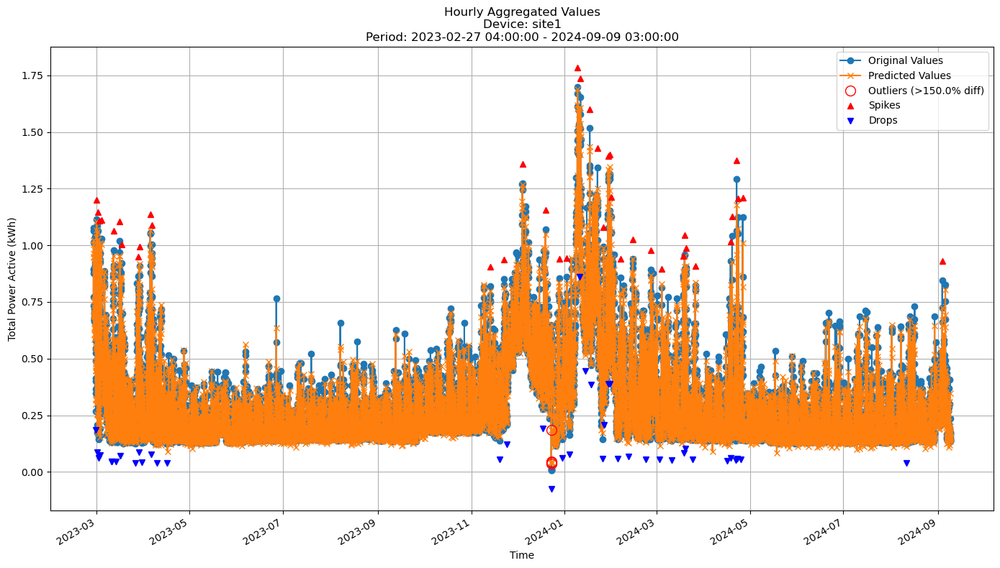


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0411
MAE: 0.0279
MAPE: 10.9215%

Directional Metrics:
Directional Accuracy: 59.9940%
First-Diff Correlation: 0.5685

Immediate Detection (delta=0):
Spikes:
  Precision: 0.4062
  Recall: 0.3333
  F1 Score: 0.3662
Drops:
  Precision: 0.2188
  Recall: 0.1707
  F1 Score: 0.1918

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8125
  Recall: 0.6667
  F1 Score: 0.7324
Drops:
  Precision: 0.6562
  Recall: 0.5122
  F1 Score: 0.5753


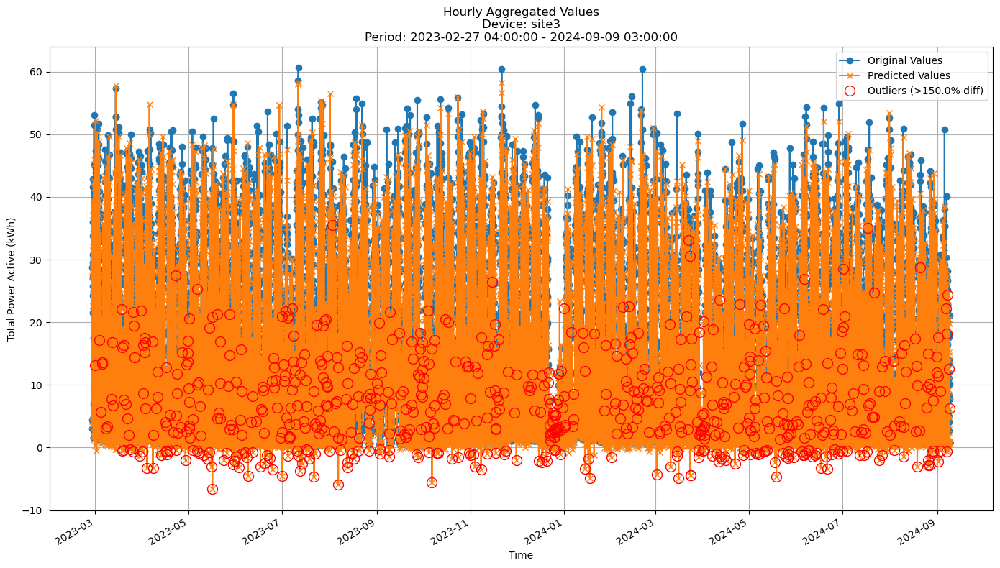


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 5.4257
MAE: 3.5677
MAPE: 46.7815%

Directional Metrics:
Directional Accuracy: 51.9795%
First-Diff Correlation: 0.4381

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


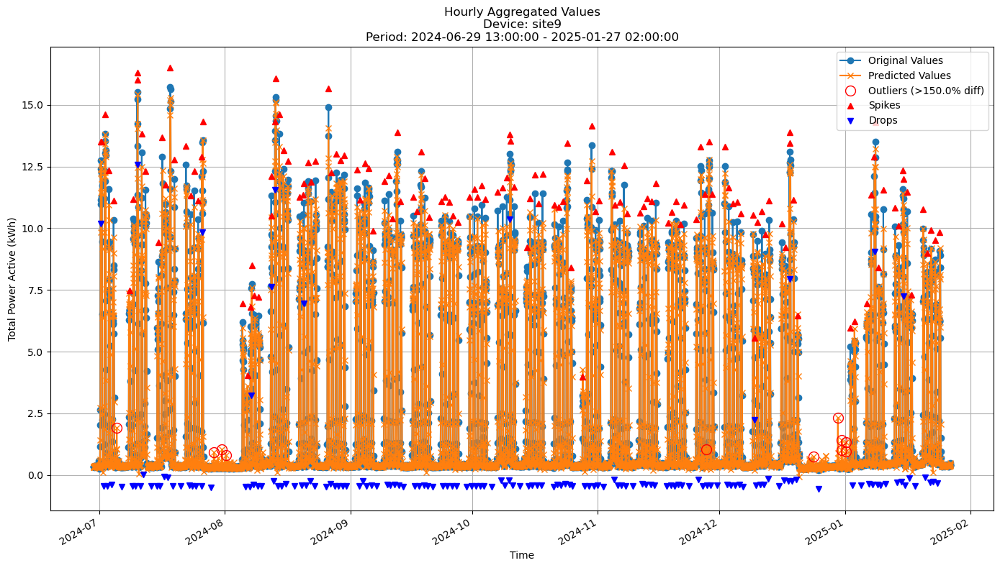


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.3222
MAE: 0.1729
MAPE: 12.8215%

Directional Metrics:
Directional Accuracy: 55.3958%
First-Diff Correlation: 0.9352

Immediate Detection (delta=0):
Spikes:
  Precision: 0.3121
  Recall: 0.2973
  F1 Score: 0.3045
Drops:
  Precision: 0.0429
  Recall: 0.0405
  F1 Score: 0.0417

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8936
  Recall: 0.8514
  F1 Score: 0.8720
Drops:
  Precision: 0.3357
  Recall: 0.3176
  F1 Score: 0.3264


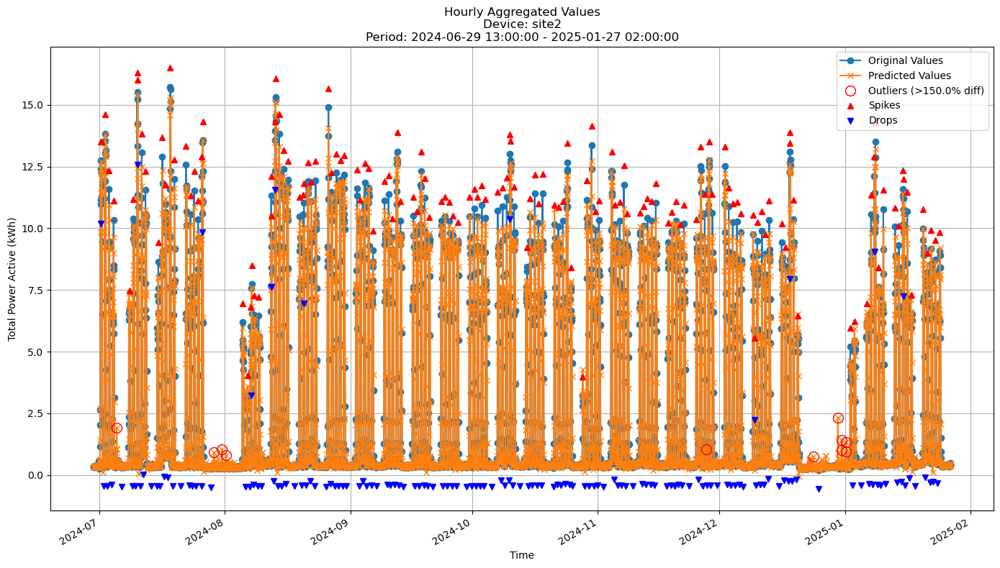


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.3222
MAE: 0.1729
MAPE: 12.8215%

Directional Metrics:
Directional Accuracy: 55.3958%
First-Diff Correlation: 0.9352

Immediate Detection (delta=0):
Spikes:
  Precision: 0.3121
  Recall: 0.2973
  F1 Score: 0.3045
Drops:
  Precision: 0.0429
  Recall: 0.0405
  F1 Score: 0.0417

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8936
  Recall: 0.8514
  F1 Score: 0.8720
Drops:
  Precision: 0.3357
  Recall: 0.3176
  F1 Score: 0.3264


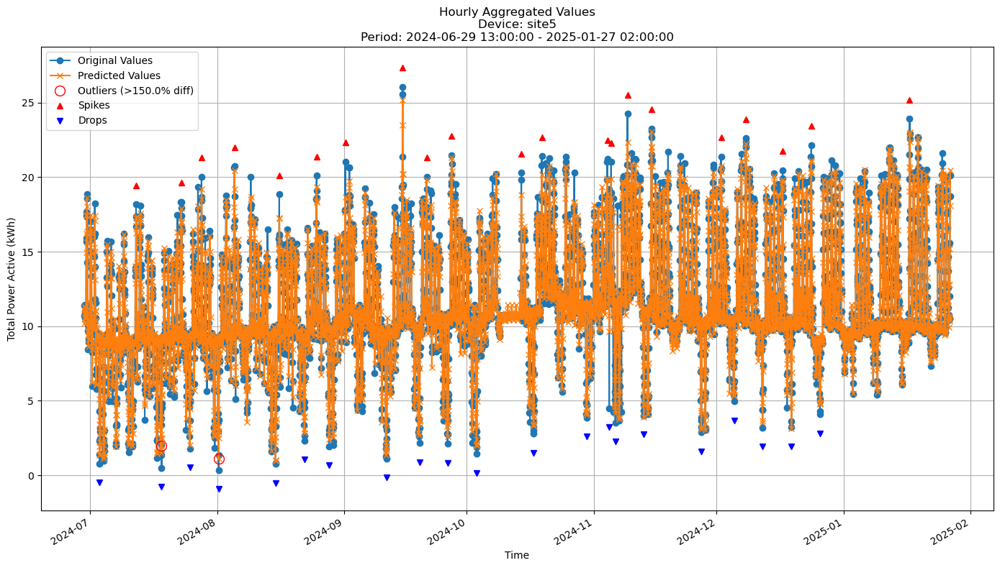


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.6659
MAE: 0.4554
MAPE: 4.8216%

Directional Metrics:
Directional Accuracy: 65.2619%
First-Diff Correlation: 0.7363

Immediate Detection (delta=0):
Spikes:
  Precision: 0.4000
  Recall: 0.2857
  F1 Score: 0.3333
Drops:
  Precision: 0.1875
  Recall: 0.1429
  F1 Score: 0.1622

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.6667
  Recall: 0.4762
  F1 Score: 0.5556
Drops:
  Precision: 0.5625
  Recall: 0.4286
  F1 Score: 0.4865


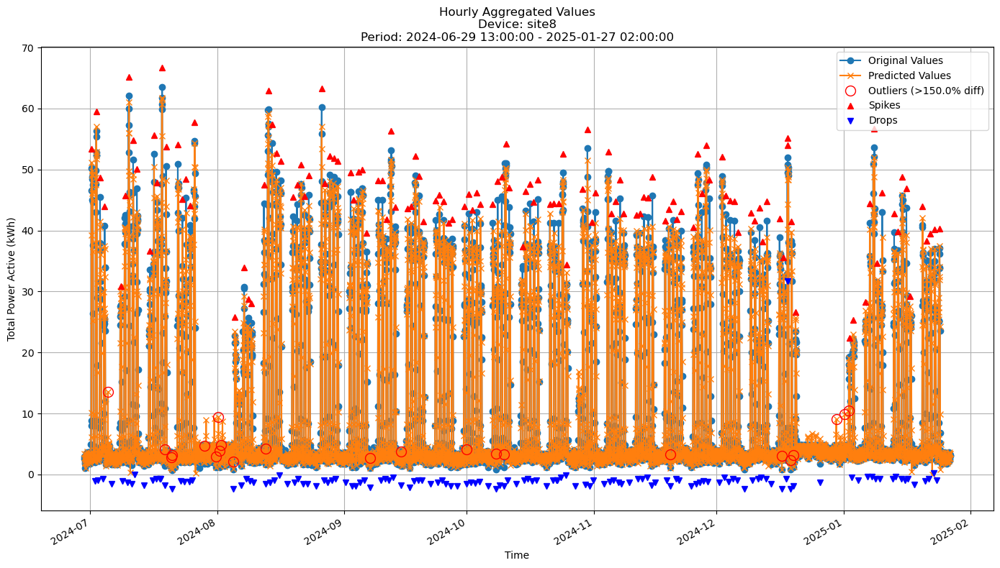


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.5526
MAE: 1.0366
MAPE: 19.3773%

Directional Metrics:
Directional Accuracy: 53.1705%
First-Diff Correlation: 0.9002

Immediate Detection (delta=0):
Spikes:
  Precision: 0.2847
  Recall: 0.2889
  F1 Score: 0.2868
Drops:
  Precision: 0.0221
  Recall: 0.0221
  F1 Score: 0.0221

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8832
  Recall: 0.8963
  F1 Score: 0.8897
Drops:
  Precision: 0.7132
  Recall: 0.7132
  F1 Score: 0.7132


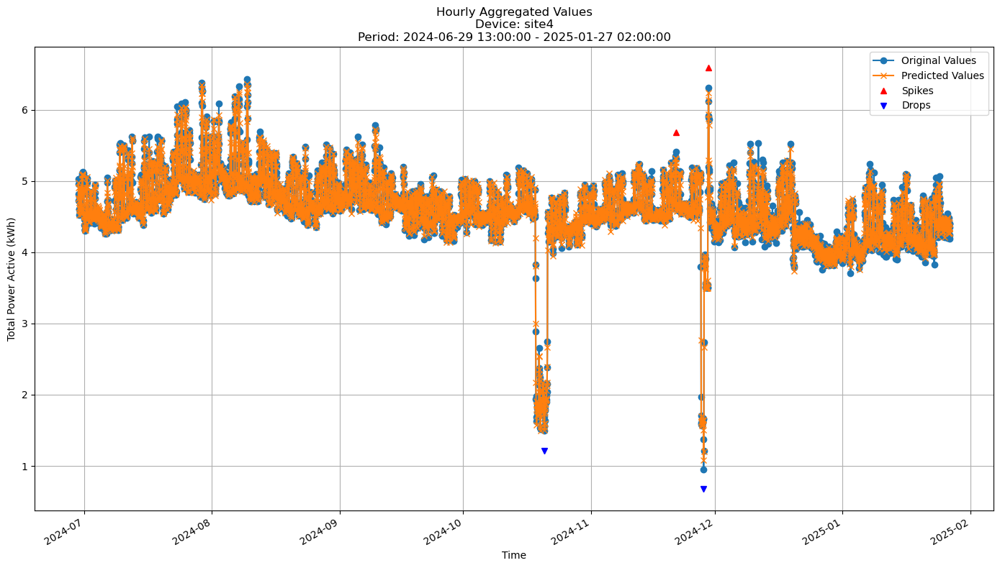


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0840
MAE: 0.0608
MAPE: 1.3457%

Directional Metrics:
Directional Accuracy: 54.6278%
First-Diff Correlation: 0.5275

Immediate Detection (delta=0):
Spikes:
  Precision: 0.5000
  Recall: 0.5000
  F1 Score: 0.5000
Drops:
  Precision: 0.5000
  Recall: 0.5000
  F1 Score: 0.5000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.5000
  Recall: 0.5000
  F1 Score: 0.5000
Drops:
  Precision: 0.5000
  Recall: 0.5000
  F1 Score: 0.5000


In [ ]:
for device_id in gbdt_train_period_predictions.keys():
    y_train = gbdt_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = gbdt_train_period_predictions[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last few periods of predictions

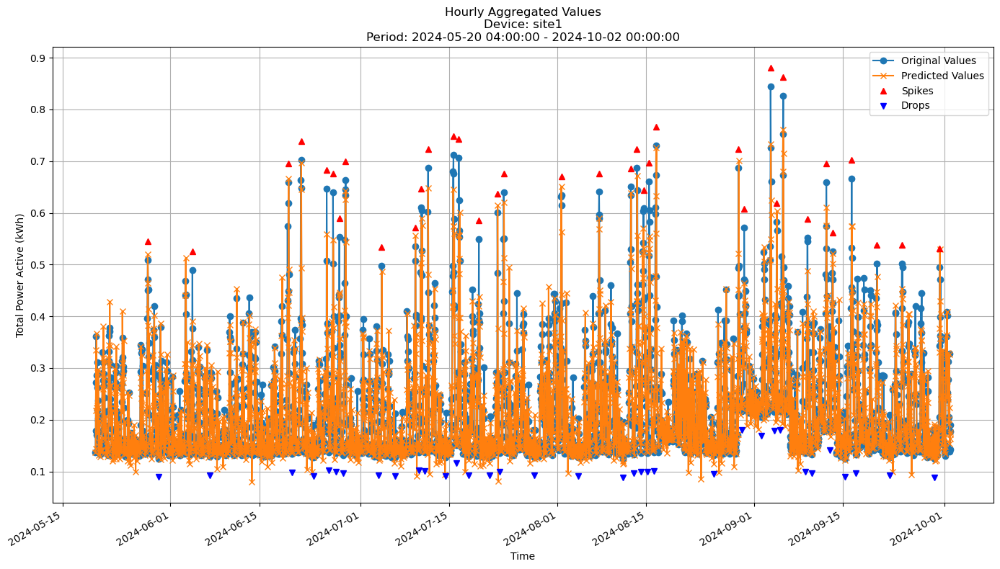


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0552
MAE: 0.0343
MAPE: 14.6041%

Directional Metrics:
Directional Accuracy: 50.8035%
First-Diff Correlation: 0.2702

Immediate Detection (delta=0):
Spikes:
  Precision: 0.3214
  Recall: 0.2500
  F1 Score: 0.2813
Drops:
  Precision: 0.0370
  Recall: 0.0286
  F1 Score: 0.0323

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8929
  Recall: 0.6944
  F1 Score: 0.7812
Drops:
  Precision: 0.2222
  Recall: 0.1714
  F1 Score: 0.1935


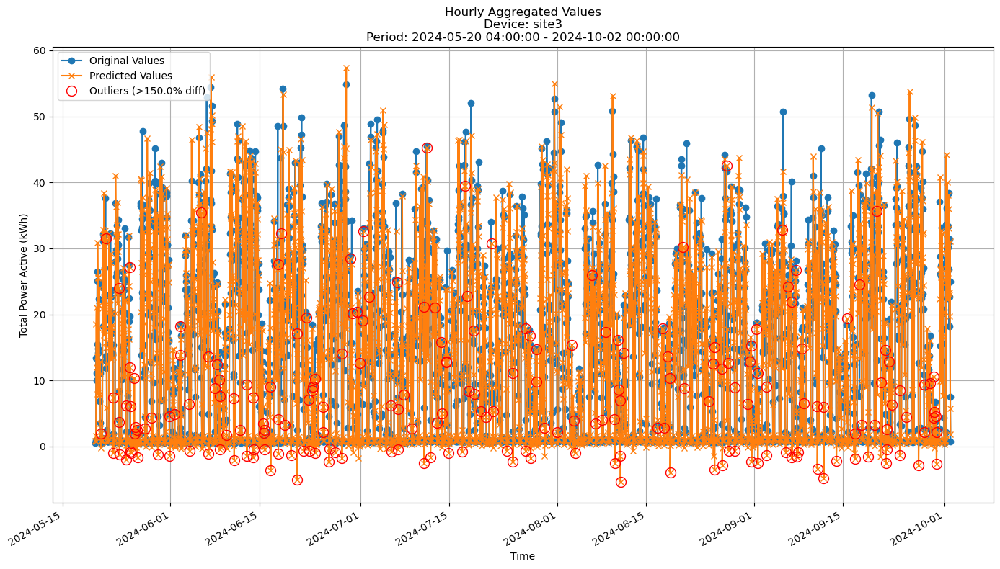


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 6.9251
MAE: 4.5485
MAPE: 55.7148%

Directional Metrics:
Directional Accuracy: 47.4660%
First-Diff Correlation: 0.1795

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


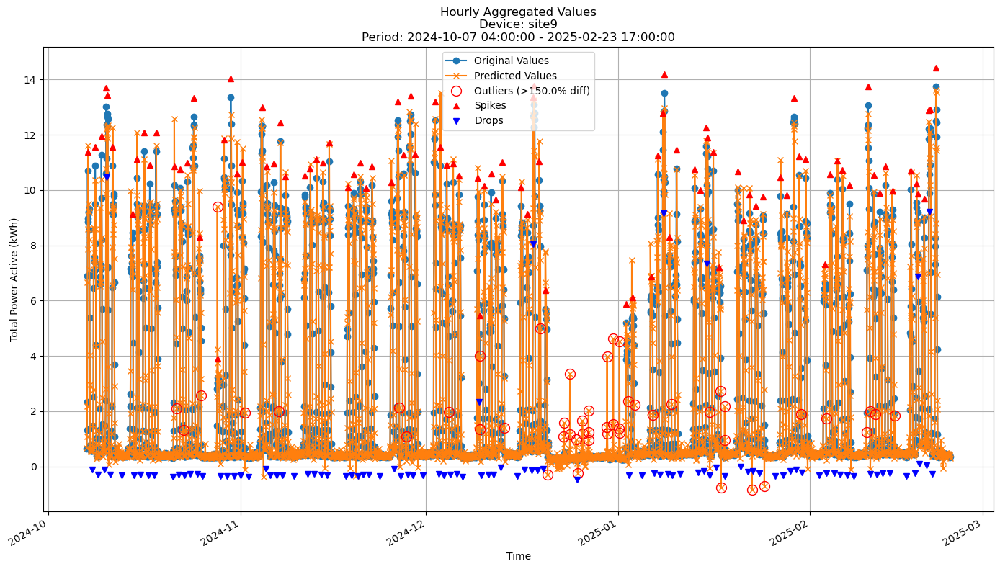


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.7876
MAE: 0.3748
MAPE: 22.0622%

Directional Metrics:
Directional Accuracy: 51.6418%
First-Diff Correlation: 0.6258

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0948
  Recall: 0.1111
  F1 Score: 0.1023
Drops:
  Precision: 0.0435
  Recall: 0.0510
  F1 Score: 0.0469

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7500
  Recall: 0.8788
  F1 Score: 0.8093
Drops:
  Precision: 0.2522
  Recall: 0.2959
  F1 Score: 0.2723


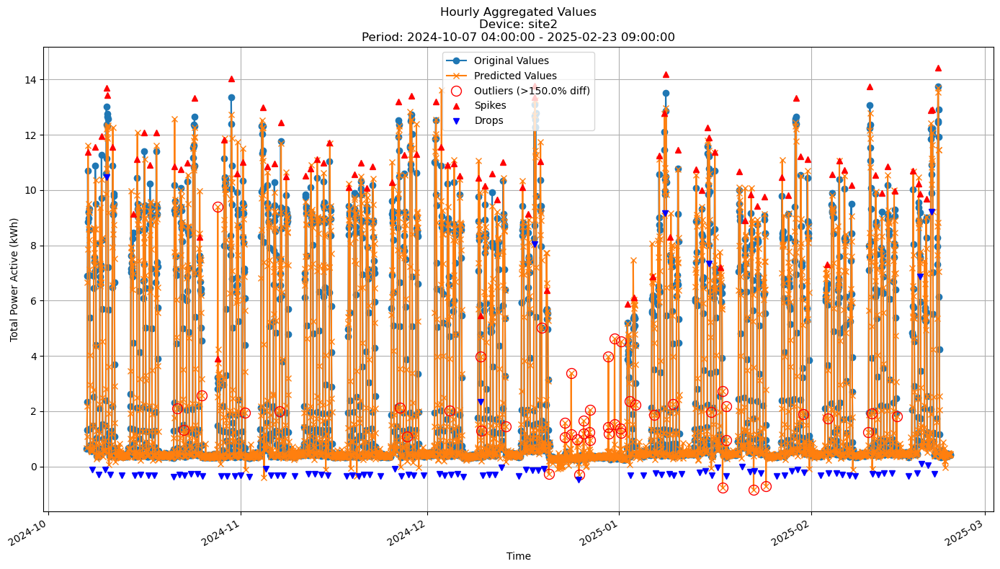


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.7884
MAE: 0.3753
MAPE: 22.0367%

Directional Metrics:
Directional Accuracy: 51.5859%
First-Diff Correlation: 0.6257

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0957
  Recall: 0.1111
  F1 Score: 0.1028
Drops:
  Precision: 0.0351
  Recall: 0.0408
  F1 Score: 0.0377

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7565
  Recall: 0.8788
  F1 Score: 0.8131
Drops:
  Precision: 0.2632
  Recall: 0.3061
  F1 Score: 0.2830


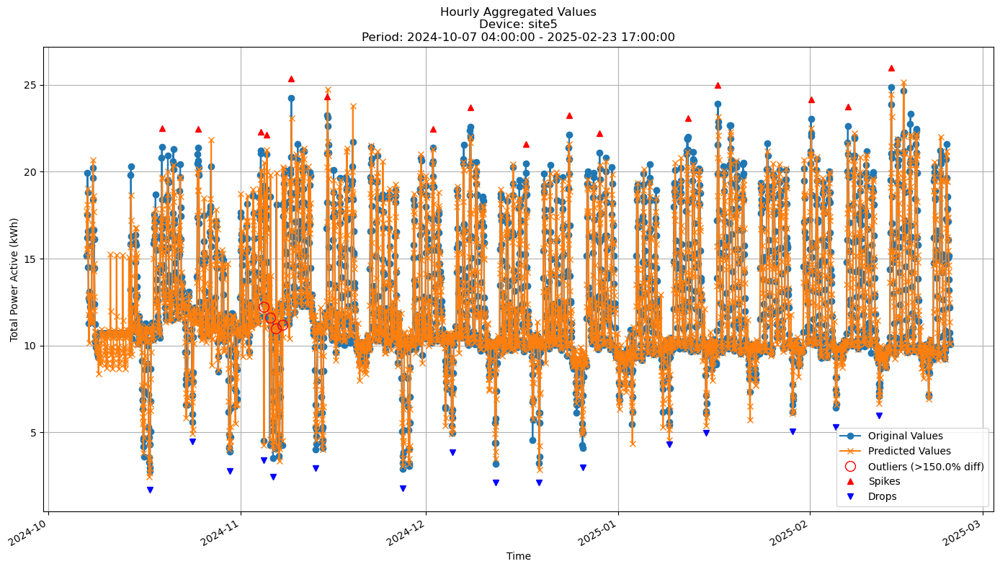


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.2286
MAE: 0.7398
MAPE: 6.0217%

Directional Metrics:
Directional Accuracy: 59.6119%
First-Diff Correlation: 0.2720

Immediate Detection (delta=0):
Spikes:
  Precision: 0.2000
  Recall: 0.1250
  F1 Score: 0.1538
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7000
  Recall: 0.4375
  F1 Score: 0.5385
Drops:
  Precision: 0.4000
  Recall: 0.2500
  F1 Score: 0.3077


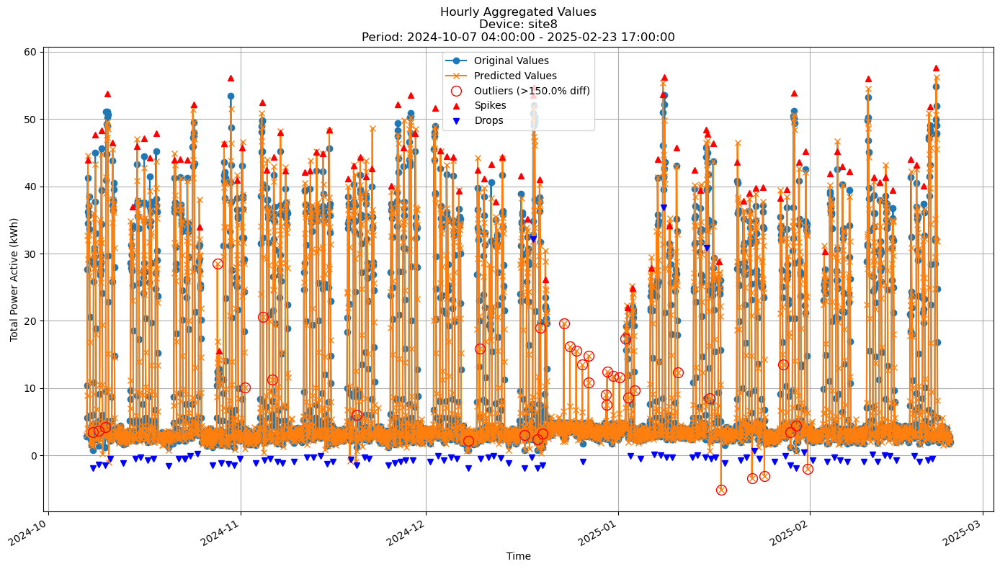


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 3.3167
MAE: 1.8337
MAPE: 25.2952%

Directional Metrics:
Directional Accuracy: 48.5672%
First-Diff Correlation: 0.5861

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0900
  Recall: 0.0947
  F1 Score: 0.0923
Drops:
  Precision: 0.0303
  Recall: 0.0316
  F1 Score: 0.0309

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8300
  Recall: 0.8737
  F1 Score: 0.8513
Drops:
  Precision: 0.4646
  Recall: 0.4842
  F1 Score: 0.4742


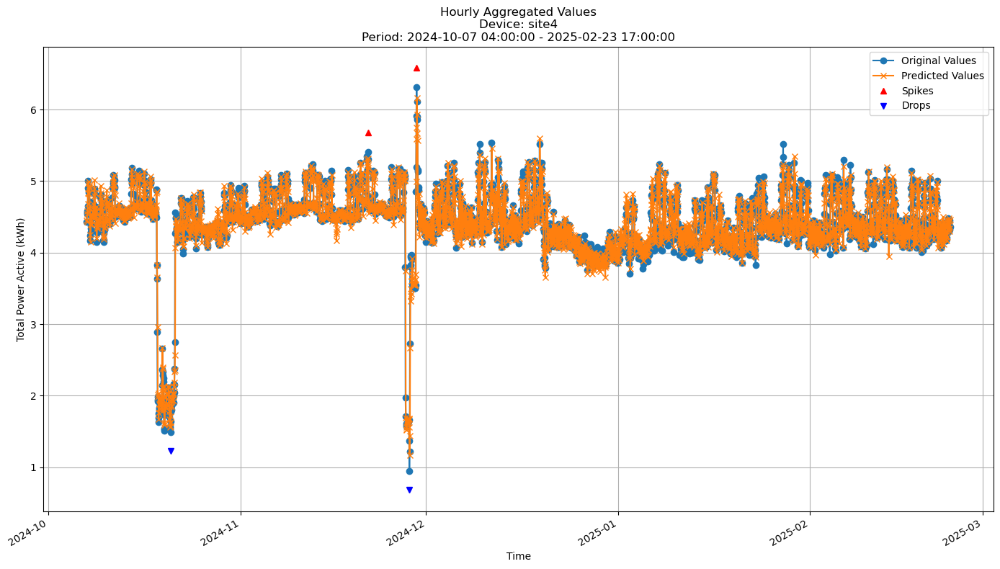


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1685
MAE: 0.1116
MAPE: 2.6208%

Directional Metrics:
Directional Accuracy: 40.9552%
First-Diff Correlation: -0.0833

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 0.5000
  Recall: 0.5000
  F1 Score: 0.5000


In [ ]:
join_periods = [-5, -4, -3, -2, -1]
# Device iteration
for device_id in gbdt_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, gbdt_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, gbdt_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

### Random Forest model

In [20]:
update_freq = "14D"  # Update the model every 14 days
rf = RandomForestRegressor
rf_params = {
    'n_estimators': 300, 
     'max_depth': 20, 
     'max_features': 0.7, 
     'random_state': 42, 
     'n_jobs': -1
}

In [21]:
rf_train_period_predictions, rf_valid_period_predictions, \
rf_train_period_metrics, rf_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model_class=rf, 
    model_params=rf_params,
    train=train, 
    valid=valid, 
    incremental=False,
    use_residuals=USE_RESIDUAL,
    data_freq=DATA_FREQUENCY, 
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/25 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/2 [00:00<?, ?it/s]


Retraining model on data from 2023-02-27 04:00:00+01:00 to 2023-03-27 03:00:00+02:00

Time: 0.29 seconds
Predicting for chunk from 2023-03-27 04:00:00+02:00 to 2023-04-10 04:00:00+02:00

-------------------------

Retraining model on data from 2023-02-27 04:00:00+01:00 to 2023-04-10 04:00:00+02:00

Time: 0.35 seconds
Predicting for chunk from 2023-04-10 05:00:00+02:00 to 2023-04-24 03:00:00+02:00

-------------------------
Model's memory usage: 0.117401 MB
Metrics for Device: site1 | Period: 2023-03-27 04:00:00+02:00 - 2023-04-24 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0555
	MAE: 0.0397
	MAPE: 15.8883%

Directional Metrics:
	Directional Accuracy: 62.1461%
	First-Diff Correlation: 0.3950

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.3810
		Recall: 0.3478
		F1: 0.3636
	Drops:
		Precision: 0.1000
		Recall: 0.0909
		F1: 0.0952

Delayed Detection (delta=

Processing devices in split 1:   0%|          | 0/2 [00:00<?, ?it/s]


Retraining model on data from 2023-02-27 04:00:00+01:00 to 2023-04-24 03:00:00+02:00

Time: 0.36 seconds
Predicting for chunk from 2023-04-24 04:00:00+02:00 to 2023-05-08 04:00:00+02:00

-------------------------

Retraining model on data from 2023-02-27 04:00:00+01:00 to 2023-05-08 04:00:00+02:00

Time: 0.38 seconds
Predicting for chunk from 2023-05-08 05:00:00+02:00 to 2023-05-22 03:00:00+02:00

-------------------------
Model's memory usage: 0.117393 MB
Metrics for Device: site1 | Period: 2023-04-24 04:00:00+02:00 - 2023-05-22 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0396
	MAE: 0.0267
	MAPE: 13.4083%

Directional Metrics:
	Directional Accuracy: 56.0358%
	First-Diff Correlation: 0.4263

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1489
		Recall: 0.1628
		F1: 0.1556
	Drops:
		Precision: 0.1522
		Recall: 0.1522
		F1: 0.1522

Delayed Detection (delta=

Processing devices in split 2:   0%|          | 0/2 [00:00<?, ?it/s]

... (41 outputs left out)

Processing devices in split 23:   0%|          | 0/7 [00:00<?, ?it/s]


Retraining model on data from 2024-06-29 13:00:00+02:00 to 2024-12-30 02:00:00+01:00

Time: 0.83 seconds
Predicting for chunk from 2024-12-30 03:00:00+01:00 to 2025-01-13 03:00:00+01:00

-------------------------

Retraining model on data from 2024-06-29 13:00:00+02:00 to 2025-01-13 03:00:00+01:00

Time: 0.81 seconds
Predicting for chunk from 2025-01-13 04:00:00+01:00 to 2025-01-27 02:00:00+01:00

-------------------------
Model's memory usage: 0.117393 MB
Metrics for Device: site9 | Period: 2024-12-30 03:00:00+01:00 - 2025-01-27 02:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.7294
	MAE: 0.3412
	MAPE: 23.8606%

Directional Metrics:
	Directional Accuracy: 53.2042%
	First-Diff Correlation: 0.6629

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1053
		Recall: 0.1333
		F1: 0.1176
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=

Processing devices in split 24:   0%|          | 0/7 [00:00<?, ?it/s]


Retraining model on data from 2024-06-29 13:00:00+02:00 to 2025-01-27 02:00:00+01:00

Time: 0.85 seconds
Predicting for chunk from 2025-01-27 03:00:00+01:00 to 2025-02-10 03:00:00+01:00

-------------------------

Retraining model on data from 2024-06-29 13:00:00+02:00 to 2025-02-10 03:00:00+01:00

Time: 0.90 seconds
Predicting for chunk from 2025-02-10 04:00:00+01:00 to 2025-02-23 17:00:00+01:00

-------------------------
Model's memory usage: 0.117393 MB
Metrics for Device: site9 | Period: 2025-01-27 03:00:00+01:00 - 2025-02-23 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.8094
	MAE: 0.3787
	MAPE: 16.0338%

Directional Metrics:
	Directional Accuracy: 57.0997%
	First-Diff Correlation: 0.6187

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0811
		Recall: 0.1071
		F1: 0.0923
	Drops:
		Precision: 0.1667
		Recall: 0.2222
		F1: 0.1905

Delayed Detection (delta=

#### Results

In [ ]:
print("\n\nTrain period metrics:")
rf_all_time_train_metrics = all_time_aggregation_metrics(rf_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
rf_all_time_valid_metrics = all_time_aggregation_metrics(rf_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: site1
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0196 ± 0.0017
	MAE: 0.0134 ± 0.0013
	MAPE: 5.2919% ± 0.2769%

	Directional Metrics:
		Directional Accuracy: 80.6108% ± 2.6010%
		First-Diff Correlation: 0.9090 ± 0.0147

	Immediate Detection (delta=0):
		Spike Precision: 0.7018 ± 0.0337
		Spike Recall: 0.6179 ± 0.0403
		Spike F1: 0.6565 ± 0.0306
		Drop Precision: 0.4261 ± 0.0727
		Drop Recall: 0.3638 ± 0.0776
		Drop F1: 0.3921 ± 0.0754

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.9019 ± 0.0339
		Spike Recall: 0.7947 ± 0.0555
		Spike F1: 0.8440 ± 0.0386
		Drop Precision: 0.6606 ± 0.0777
		Drop Recall: 0.5631 ± 0.0901
		Drop F1: 0.6074 ± 0.0843
Daily Metrics:
	RMSE: 0.0638 ± 0.0081
	MAE: 0.0490 ± 0.0088
	MAPE: 0.7398% ± 0.0844%

	Directional Metrics:
		Directional Accuracy: 98.2265% ± 0.8167%
		First-Diff Correlation: 0.9991 ± 0.0002

	Immediate Detection (delta=0):
		Spike

#### Training plots
Plot only the last period of predictions

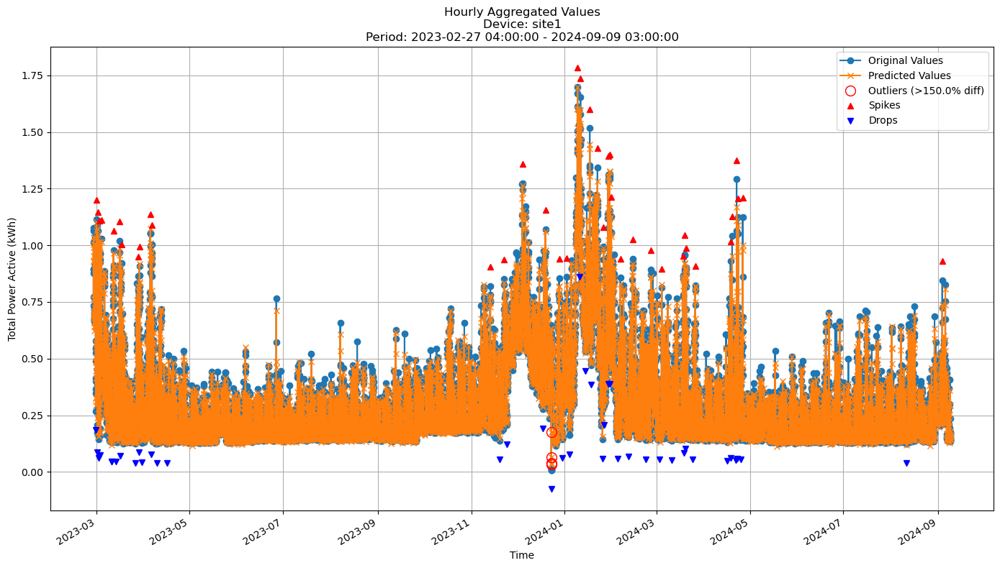


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0217
MAE: 0.0148
MAPE: 5.8741%

Directional Metrics:
Directional Accuracy: 76.6260%
First-Diff Correlation: 0.8844

Immediate Detection (delta=0):
Spikes:
  Precision: 0.5556
  Recall: 0.5128
  F1 Score: 0.5333
Drops:
  Precision: 0.4722
  Recall: 0.4146
  F1 Score: 0.4416

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8333
  Recall: 0.7692
  F1 Score: 0.8000
Drops:
  Precision: 0.6111
  Recall: 0.5366
  F1 Score: 0.5714


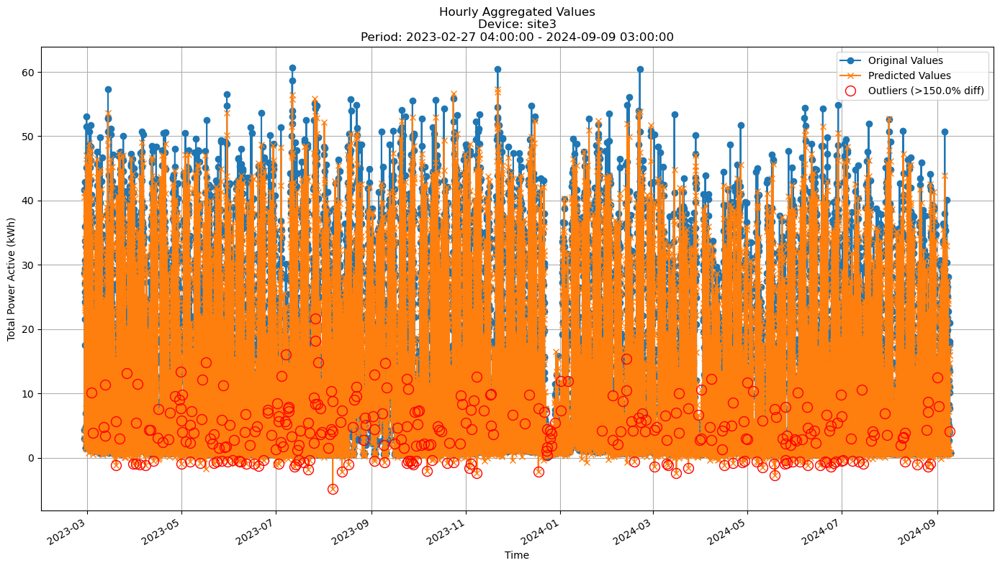


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 2.9657
MAE: 1.9470
MAPE: 23.7895%

Directional Metrics:
Directional Accuracy: 68.2244%
First-Diff Correlation: 0.8390

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


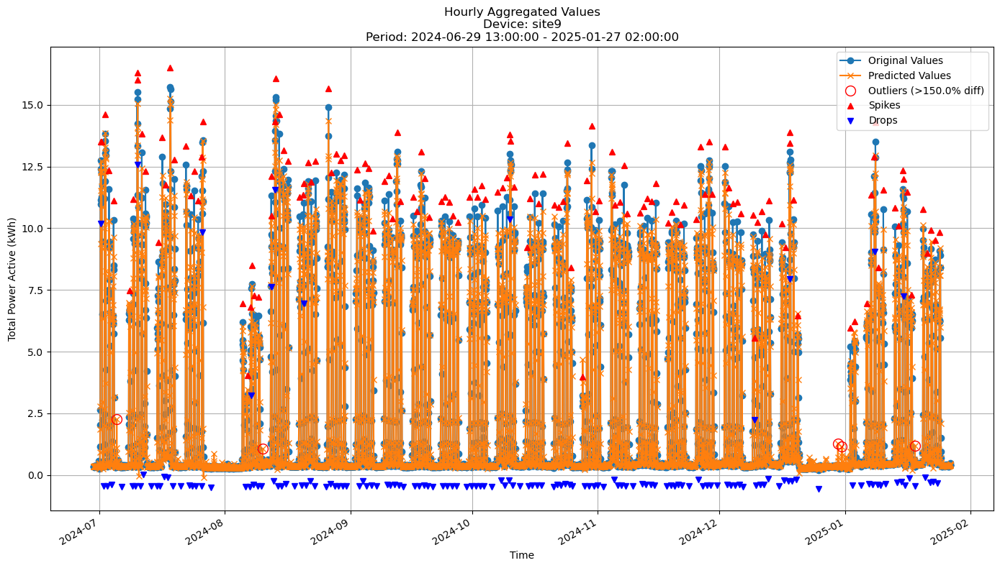


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2864
MAE: 0.1305
MAPE: 7.1573%

Directional Metrics:
Directional Accuracy: 74.1237%
First-Diff Correlation: 0.9476

Immediate Detection (delta=0):
Spikes:
  Precision: 0.3427
  Recall: 0.3311
  F1 Score: 0.3368
Drops:
  Precision: 0.2113
  Recall: 0.2027
  F1 Score: 0.2069

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.9231
  Recall: 0.8919
  F1 Score: 0.9072
Drops:
  Precision: 0.3732
  Recall: 0.3581
  F1 Score: 0.3655


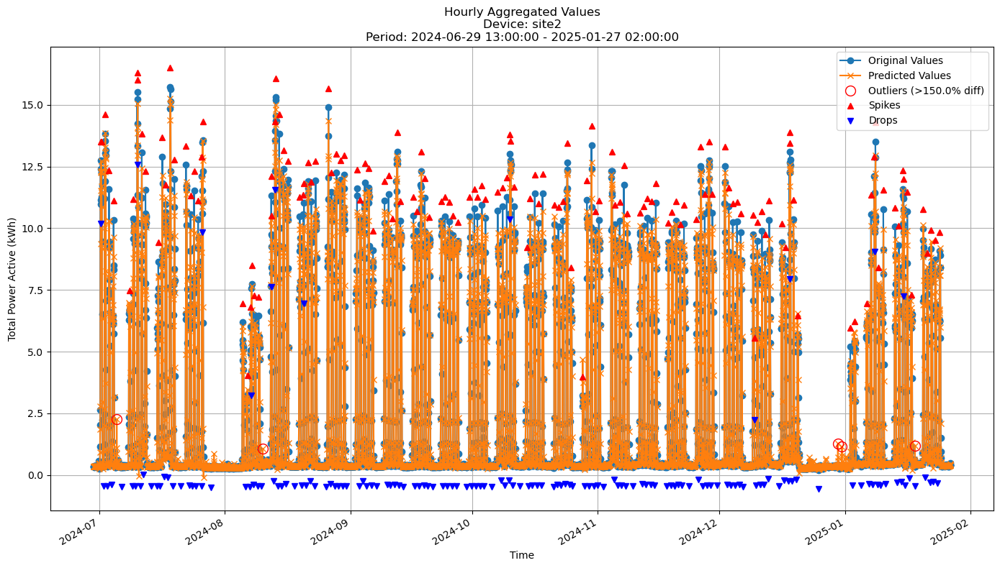


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2864
MAE: 0.1305
MAPE: 7.1574%

Directional Metrics:
Directional Accuracy: 74.1237%
First-Diff Correlation: 0.9476

Immediate Detection (delta=0):
Spikes:
  Precision: 0.3427
  Recall: 0.3311
  F1 Score: 0.3368
Drops:
  Precision: 0.2113
  Recall: 0.2027
  F1 Score: 0.2069

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.9231
  Recall: 0.8919
  F1 Score: 0.9072
Drops:
  Precision: 0.3732
  Recall: 0.3581
  F1 Score: 0.3655


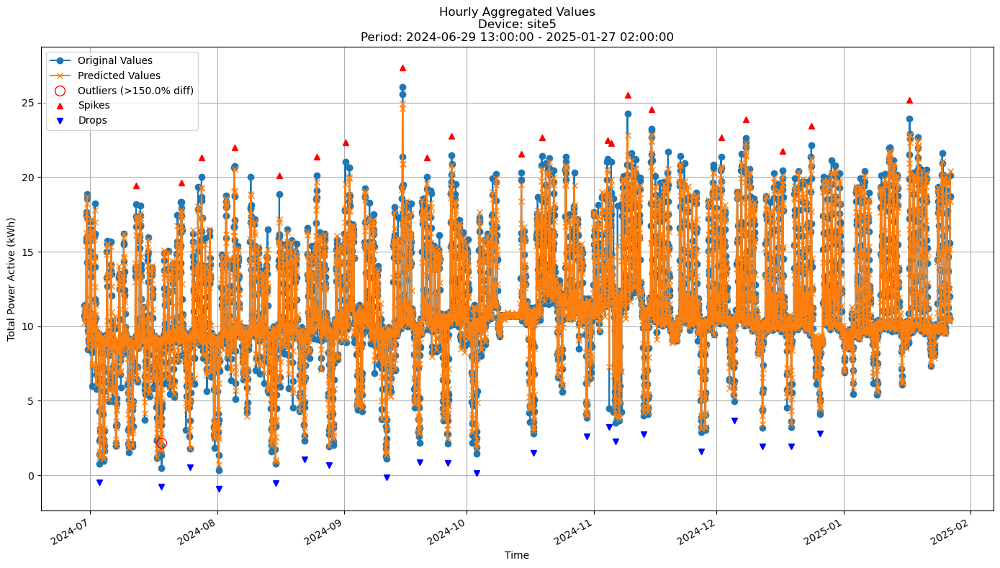


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.4342
MAE: 0.2898
MAPE: 3.0369%

Directional Metrics:
Directional Accuracy: 74.4978%
First-Diff Correlation: 0.8896

Immediate Detection (delta=0):
Spikes:
  Precision: 0.4118
  Recall: 0.3333
  F1 Score: 0.3684
Drops:
  Precision: 0.4444
  Recall: 0.3810
  F1 Score: 0.4103

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7059
  Recall: 0.5714
  F1 Score: 0.6316
Drops:
  Precision: 0.7222
  Recall: 0.6190
  F1 Score: 0.6667


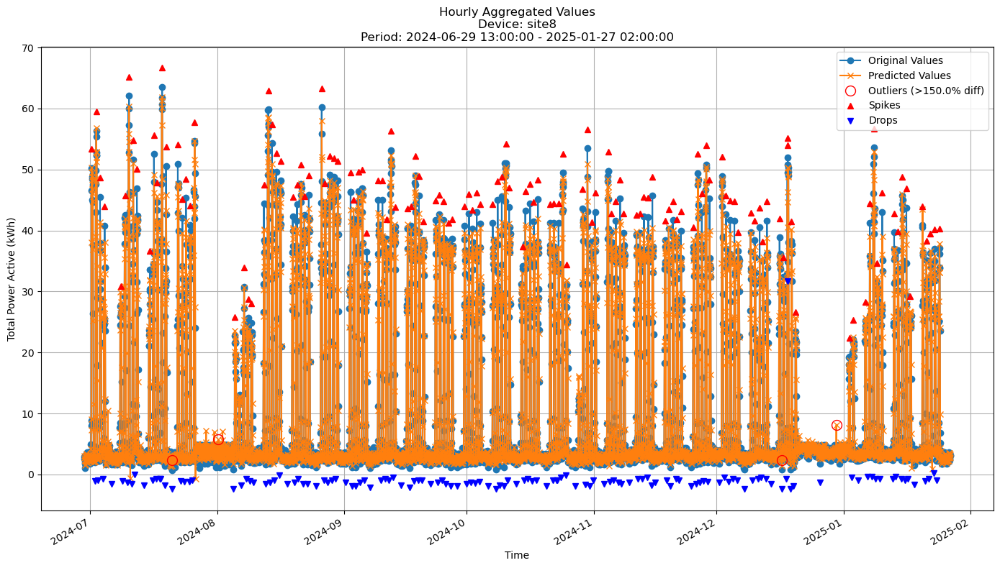


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.2304
MAE: 0.7333
MAPE: 12.3530%

Directional Metrics:
Directional Accuracy: 68.3734%
First-Diff Correlation: 0.9385

Immediate Detection (delta=0):
Spikes:
  Precision: 0.3382
  Recall: 0.3407
  F1 Score: 0.3395
Drops:
  Precision: 0.2444
  Recall: 0.2426
  F1 Score: 0.2435

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.9191
  Recall: 0.9259
  F1 Score: 0.9225
Drops:
  Precision: 0.6296
  Recall: 0.6250
  F1 Score: 0.6273


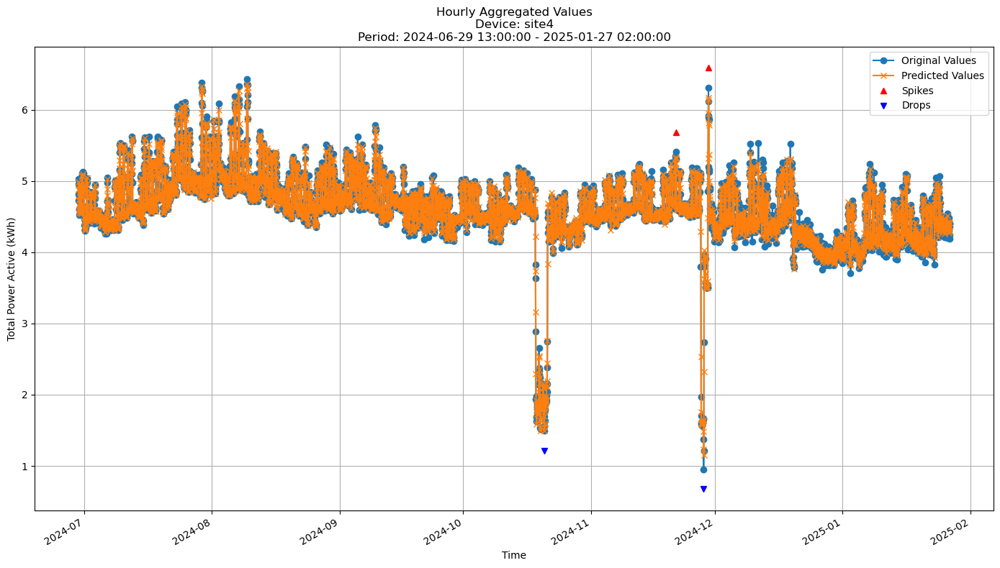


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0550
MAE: 0.0384
MAPE: 0.8586%

Directional Metrics:
Directional Accuracy: 69.3186%
First-Diff Correlation: 0.8084

Immediate Detection (delta=0):
Spikes:
  Precision: 0.5000
  Recall: 0.5000
  F1 Score: 0.5000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 0.5000
  Recall: 0.5000
  F1 Score: 0.5000


In [ ]:
for device_id in rf_train_period_predictions.keys():
    y_train = rf_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = rf_train_period_predictions[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last periods of predictions

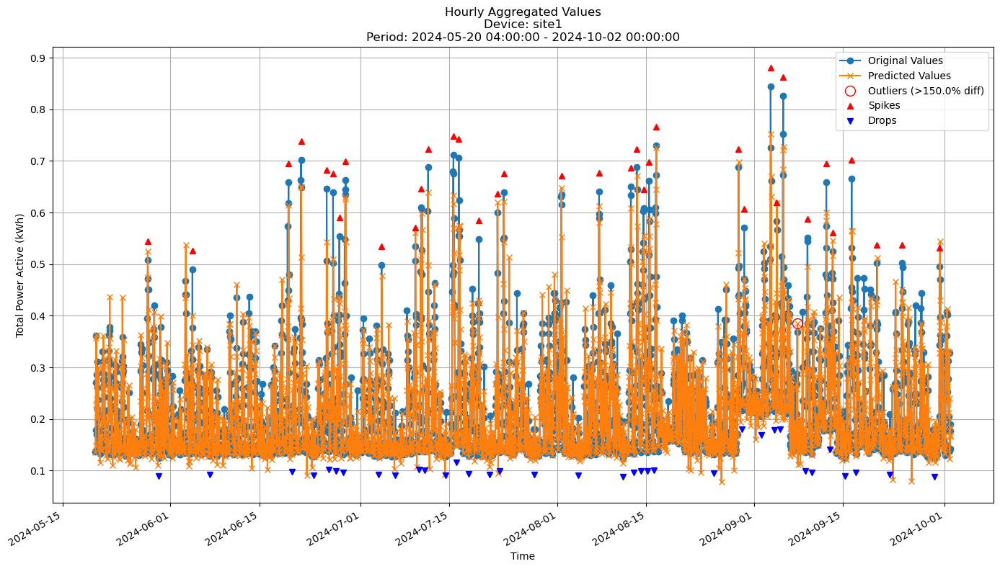


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0556
MAE: 0.0348
MAPE: 14.9023%

Directional Metrics:
Directional Accuracy: 50.4017%
First-Diff Correlation: 0.2733

Immediate Detection (delta=0):
Spikes:
  Precision: 0.3226
  Recall: 0.2778
  F1 Score: 0.2985
Drops:
  Precision: 0.0667
  Recall: 0.0571
  F1 Score: 0.0615

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8710
  Recall: 0.7500
  F1 Score: 0.8060
Drops:
  Precision: 0.3000
  Recall: 0.2571
  F1 Score: 0.2769


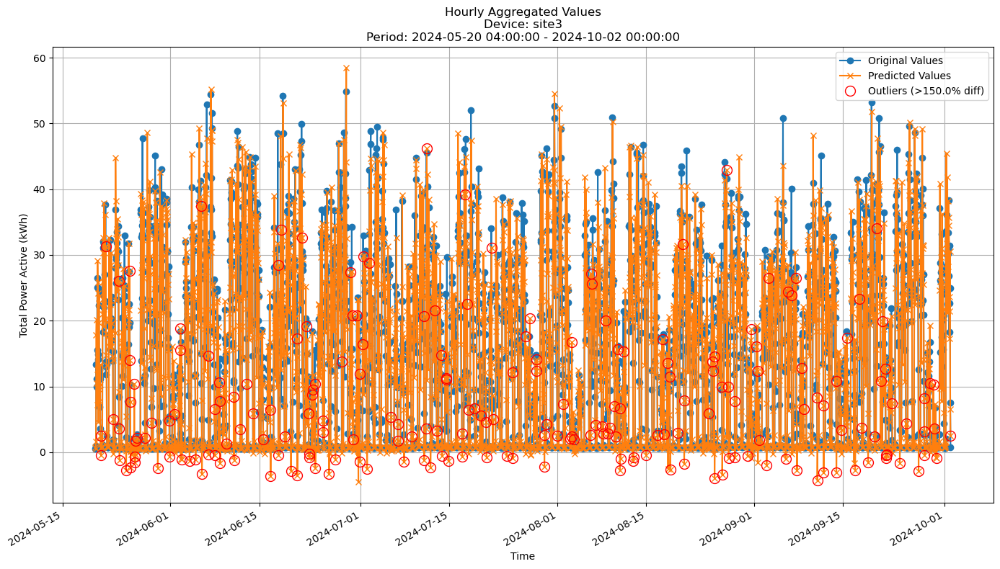


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 7.0039
MAE: 4.5629
MAPE: 51.7142%

Directional Metrics:
Directional Accuracy: 45.6428%
First-Diff Correlation: 0.1766

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


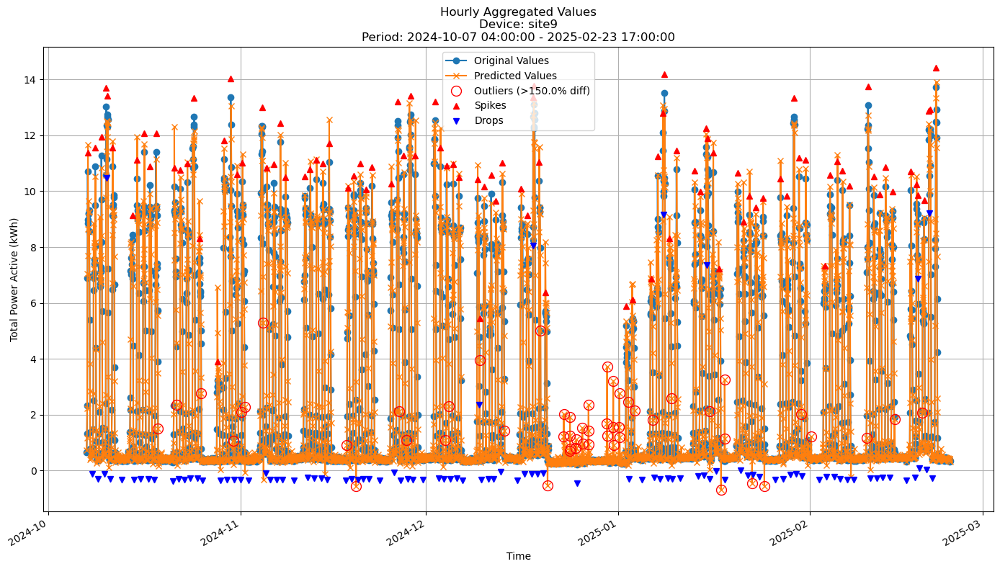


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.7738
MAE: 0.3657
MAPE: 20.9116%

Directional Metrics:
Directional Accuracy: 52.0896%
First-Diff Correlation: 0.6271

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0870
  Recall: 0.1010
  F1 Score: 0.0935
Drops:
  Precision: 0.0614
  Recall: 0.0714
  F1 Score: 0.0660

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7739
  Recall: 0.8990
  F1 Score: 0.8318
Drops:
  Precision: 0.3421
  Recall: 0.3980
  F1 Score: 0.3679


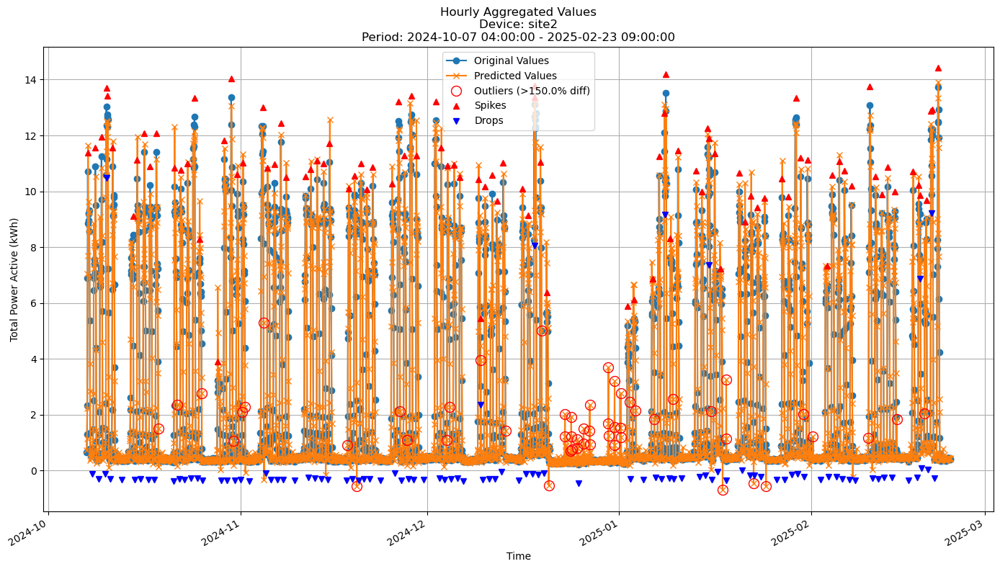


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.7747
MAE: 0.3665
MAPE: 20.9367%

Directional Metrics:
Directional Accuracy: 52.1544%
First-Diff Correlation: 0.6271

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0783
  Recall: 0.0909
  F1 Score: 0.0841
Drops:
  Precision: 0.0614
  Recall: 0.0714
  F1 Score: 0.0660

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7652
  Recall: 0.8889
  F1 Score: 0.8224
Drops:
  Precision: 0.3421
  Recall: 0.3980
  F1 Score: 0.3679


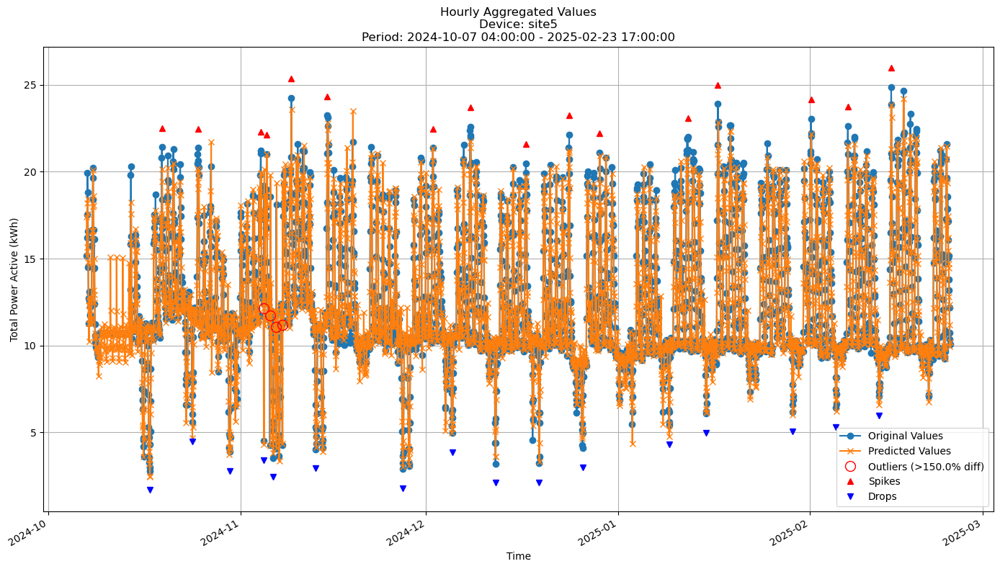


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.1969
MAE: 0.7150
MAPE: 5.8138%

Directional Metrics:
Directional Accuracy: 60.0896%
First-Diff Correlation: 0.2807

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1818
  Recall: 0.1250
  F1 Score: 0.1481
Drops:
  Precision: 0.2727
  Recall: 0.1875
  F1 Score: 0.2222

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.6364
  Recall: 0.4375
  F1 Score: 0.5185
Drops:
  Precision: 0.5455
  Recall: 0.3750
  F1 Score: 0.4444


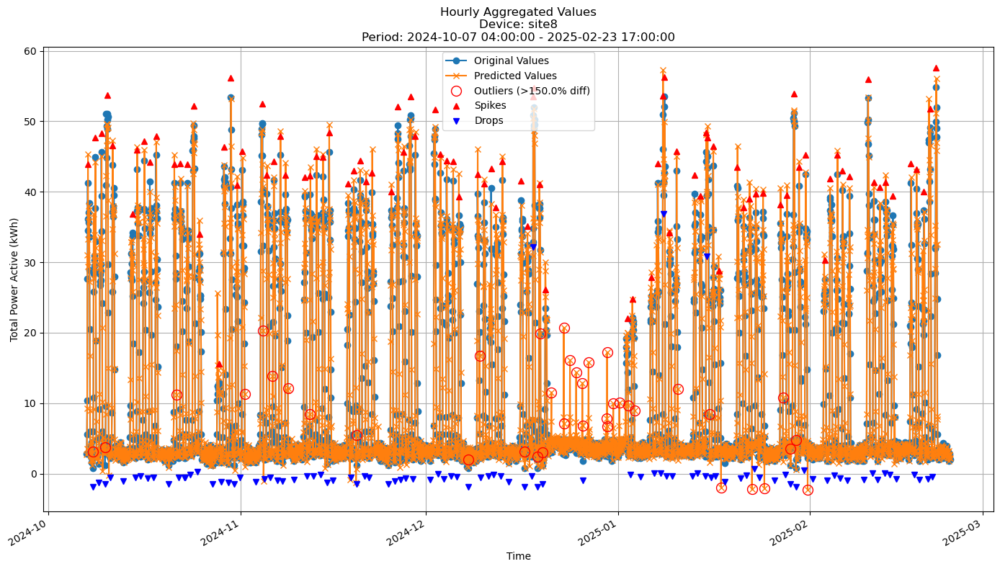


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 3.2908
MAE: 1.8114
MAPE: 25.1457%

Directional Metrics:
Directional Accuracy: 48.3582%
First-Diff Correlation: 0.5800

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1122
  Recall: 0.1158
  F1 Score: 0.1140
Drops:
  Precision: 0.0309
  Recall: 0.0316
  F1 Score: 0.0312

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8776
  Recall: 0.9053
  F1 Score: 0.8912
Drops:
  Precision: 0.4536
  Recall: 0.4632
  F1 Score: 0.4583


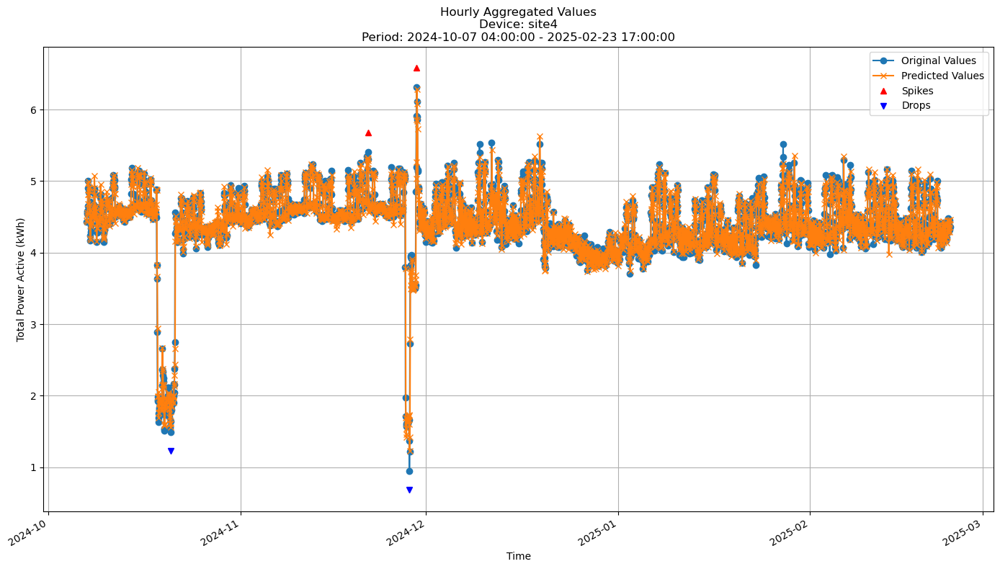


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1653
MAE: 0.1085
MAPE: 2.5450%

Directional Metrics:
Directional Accuracy: 41.3731%
First-Diff Correlation: -0.0860

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.5000
  Recall: 0.5000
  F1 Score: 0.5000
Drops:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000


In [ ]:
join_periods = [-5, -4, -3, -2, -1]
# Device iteration
for device_id in rf_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, rf_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, rf_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### Hoeffding Tree

In [25]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

hoef = HoeffdingTreeRegressor
hoef_params = {
    'max_depth': 15, 
     'grace_period': 10, 
     'tau': 0.1, 
     'delta': 0.01,
    'leaf_prediction': 'mean'
}

In [26]:
hoef_all_train_preds, hoef_all_valid_preds, \
hoef_all_train_metrics, hoef_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=hoef, 
    model_params=hoef_params,
    train=train, 
    valid=valid, 
    use_residuals=USE_RESIDUAL,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/25 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/2 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 04:00:00+01:00 to 2023-03-27 03:00:00+02:00
Model's memory usage: 0.522041 MB
Metrics for Device: site1 | Period: 2023-03-27 04:00:00+02:00 - 2023-04-24 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0629
	MAE: 0.0427
	MAPE: 16.3155%

Directional Metrics:
	Directional Accuracy: 60.0596%
	First-Diff Correlation: 0.3325

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.3636
		Recall: 0.3478
		F1: 0.3556
	Drops:
		Precision: 0.0952
		Recall: 0.0909
		F1: 0.0930

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.8182
		Recall: 0.7826
		F1: 0.8000
	Drops:
		Precision: 0.4286
		Recall: 0.4091
		F1: 0.4186
--------------------------------------------------
Dai

Processing devices in split 1:   0%|          | 0/2 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 04:00:00+01:00 to 2023-04-24 03:00:00+02:00
Model's memory usage: 0.688896 MB
Metrics for Device: site1 | Period: 2023-04-24 04:00:00+02:00 - 2023-05-22 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0404
	MAE: 0.0276
	MAPE: 13.9960%

Directional Metrics:
	Directional Accuracy: 53.6513%
	First-Diff Correlation: 0.4842

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.2292
		Recall: 0.2558
		F1: 0.2418
	Drops:
		Precision: 0.1702
		Recall: 0.1739
		F1: 0.1720

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.6667
		Recall: 0.7442
		F1: 0.7033
	Drops:
		Precision: 0.4468
		Recall: 0.4565
		F1: 0.4516
--------------------------------------------------
Dai

Processing devices in split 2:   0%|          | 0/2 [00:00<?, ?it/s]

... (41 outputs left out)

Processing devices in split 23:   0%|          | 0/7 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 13:00:00+02:00 to 2024-12-30 02:00:00+01:00
Model's memory usage: 1.953987 MB
Metrics for Device: site9 | Period: 2024-12-30 03:00:00+01:00 - 2025-01-27 02:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.8317
	MAE: 0.3895
	MAPE: 27.2158%

Directional Metrics:
	Directional Accuracy: 51.2668%
	First-Diff Correlation: 0.5579

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0312
		Recall: 0.0333
		F1: 0.0323
	Drops:
		Precision: 0.0625
		Recall: 0.0690
		F1: 0.0656

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.5625
		Recall: 0.6000
		F1: 0.5806
	Drops:
		Precision: 0.3125
		Recall: 0.3448
		F1: 0.3279
--------------------------------------------------
Dai

Processing devices in split 24:   0%|          | 0/7 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 13:00:00+02:00 to 2025-01-27 02:00:00+01:00
Model's memory usage: 2.306938 MB
Metrics for Device: site9 | Period: 2025-01-27 03:00:00+01:00 - 2025-02-23 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.9485
	MAE: 0.4668
	MAPE: 22.6962%

Directional Metrics:
	Directional Accuracy: 55.4381%
	First-Diff Correlation: 0.5555

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0588
		Recall: 0.0714
		F1: 0.0645
	Drops:
		Precision: 0.1176
		Recall: 0.1481
		F1: 0.1311

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.6765
		Recall: 0.8214
		F1: 0.7419
	Drops:
		Precision: 0.3235
		Recall: 0.4074
		F1: 0.3607
--------------------------------------------------
Dai

#### Results

In [ ]:
print("\n\nTrain period metrics:")
hoef_all_time_train_metrics = all_time_aggregation_metrics(hoef_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
hoef_all_time_valid_metrics = all_time_aggregation_metrics(hoef_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: site1
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0550 ± 0.0046
	MAE: 0.0365 ± 0.0038
	MAPE: 13.7786% ± 0.4442%

	Directional Metrics:
		Directional Accuracy: 59.1759% ± 2.7526%
		First-Diff Correlation: 0.3889 ± 0.0632

	Immediate Detection (delta=0):
		Spike Precision: 0.2010 ± 0.0428
		Spike Recall: 0.1958 ± 0.0264
		Spike F1: 0.1978 ± 0.0335
		Drop Precision: 0.1168 ± 0.0264
		Drop Recall: 0.1131 ± 0.0334
		Drop F1: 0.1146 ± 0.0296

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.6922 ± 0.0637
		Spike Recall: 0.6829 ± 0.0433
		Spike F1: 0.6854 ± 0.0396
		Drop Precision: 0.4851 ± 0.0564
		Drop Recall: 0.4656 ± 0.0759
		Drop F1: 0.4738 ± 0.0622
Daily Metrics:
	RMSE: 0.2070 ± 0.0293
	MAE: 0.1454 ± 0.0284
	MAPE: 2.0400% ± 0.2072%

	Directional Metrics:
		Directional Accuracy: 95.9946% ± 1.0796%
		First-Diff Correlation: 0.9921 ± 0.0014

	Immediate Detection (delta=0):
		Spik

#### Training plots
Plot only the last period of predictions

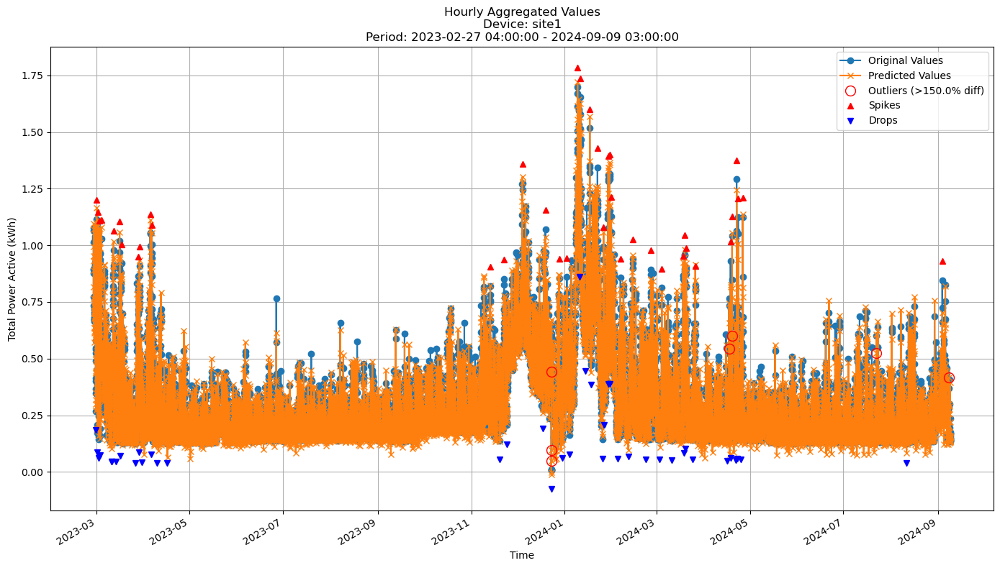


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0582
MAE: 0.0380
MAPE: 14.2888%

Directional Metrics:
Directional Accuracy: 55.8044%
First-Diff Correlation: 0.3057

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0667
  Recall: 0.0513
  F1 Score: 0.0580
Drops:
  Precision: 0.0645
  Recall: 0.0488
  F1 Score: 0.0556

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8333
  Recall: 0.6410
  F1 Score: 0.7246
Drops:
  Precision: 0.5484
  Recall: 0.4146
  F1 Score: 0.4722


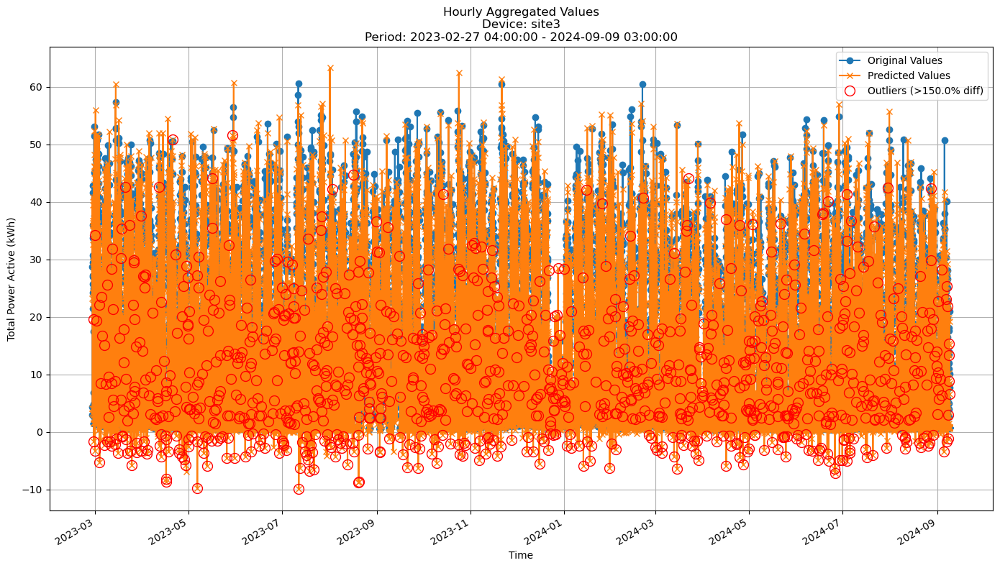


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 7.4565
MAE: 4.8565
MAPE: 63.5368%

Directional Metrics:
Directional Accuracy: 47.1722%
First-Diff Correlation: 0.1387

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


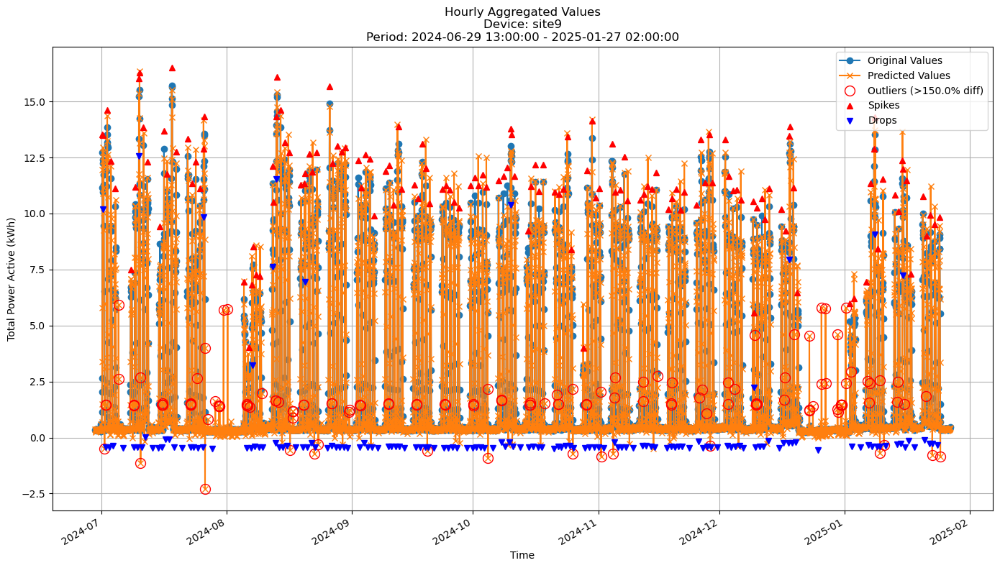


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.8806
MAE: 0.4143
MAPE: 26.8512%

Directional Metrics:
Directional Accuracy: 49.7046%
First-Diff Correlation: 0.5881

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0751
  Recall: 0.0878
  F1 Score: 0.0810
Drops:
  Precision: 0.0289
  Recall: 0.0338
  F1 Score: 0.0312

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7688
  Recall: 0.8986
  F1 Score: 0.8287
Drops:
  Precision: 0.2428
  Recall: 0.2838
  F1 Score: 0.2617


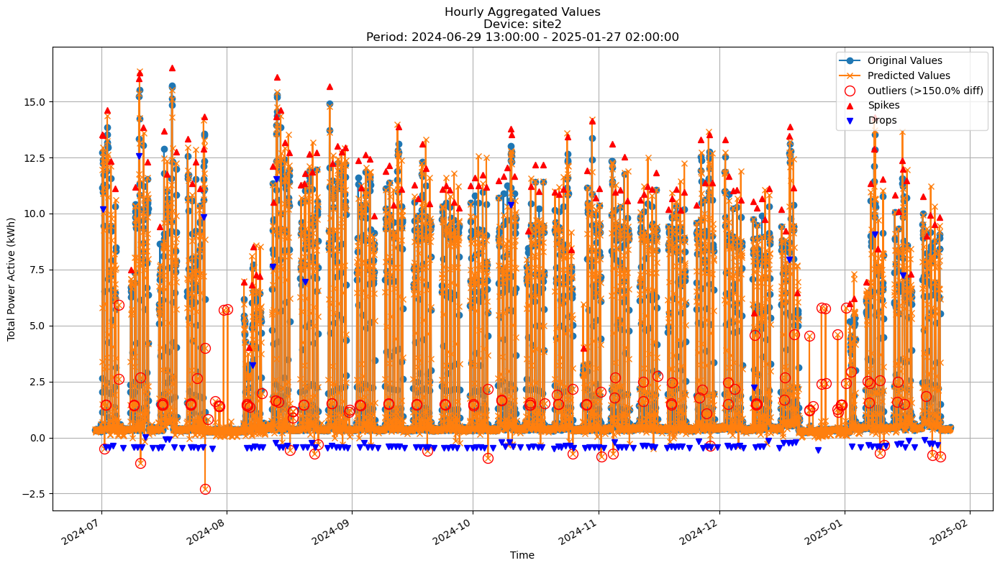


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.8806
MAE: 0.4143
MAPE: 26.8512%

Directional Metrics:
Directional Accuracy: 49.7046%
First-Diff Correlation: 0.5881

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0751
  Recall: 0.0878
  F1 Score: 0.0810
Drops:
  Precision: 0.0289
  Recall: 0.0338
  F1 Score: 0.0312

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7688
  Recall: 0.8986
  F1 Score: 0.8287
Drops:
  Precision: 0.2428
  Recall: 0.2838
  F1 Score: 0.2617


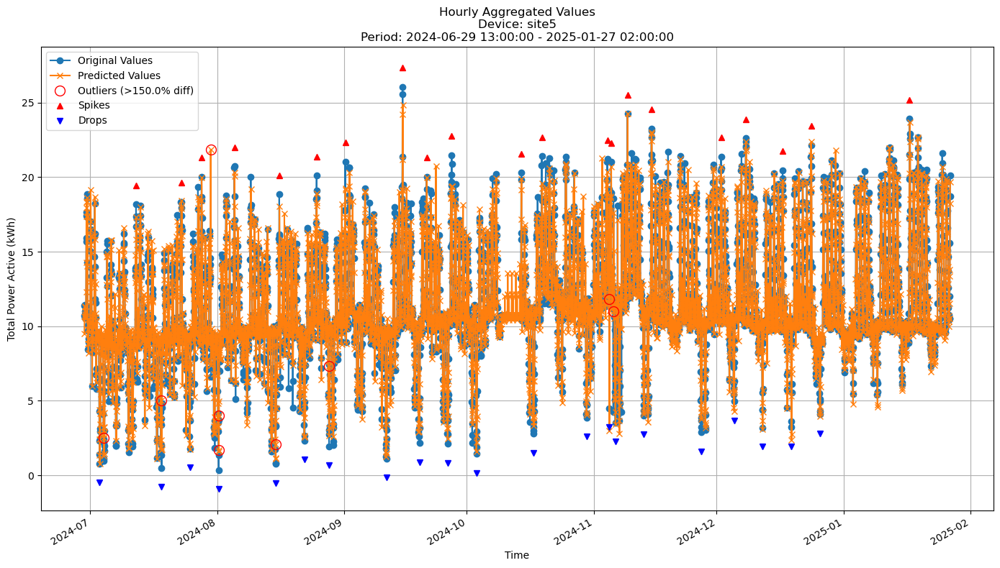


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.2550
MAE: 0.8000
MAPE: 8.4159%

Directional Metrics:
Directional Accuracy: 60.8310%
First-Diff Correlation: 0.2783

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0526
  Recall: 0.0476
  F1 Score: 0.0500
Drops:
  Precision: 0.1579
  Recall: 0.1429
  F1 Score: 0.1500

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.4211
  Recall: 0.3810
  F1 Score: 0.4000
Drops:
  Precision: 0.6316
  Recall: 0.5714
  F1 Score: 0.6000


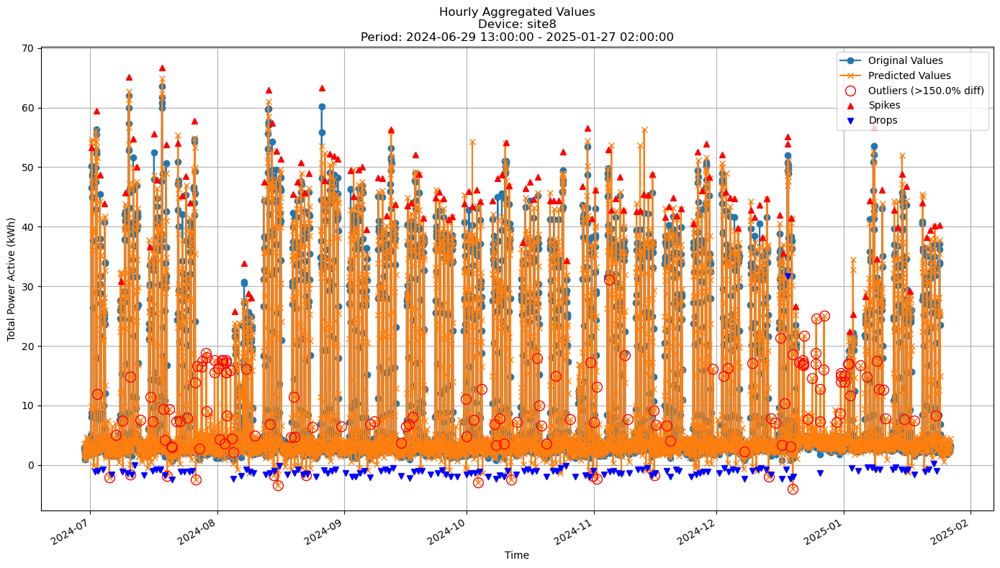


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 4.1178
MAE: 2.2234
MAPE: 33.2442%

Directional Metrics:
Directional Accuracy: 51.2210%
First-Diff Correlation: 0.4538

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0968
  Recall: 0.1111
  F1 Score: 0.1034
Drops:
  Precision: 0.0390
  Recall: 0.0441
  F1 Score: 0.0414

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7290
  Recall: 0.8370
  F1 Score: 0.7793
Drops:
  Precision: 0.2078
  Recall: 0.2353
  F1 Score: 0.2207


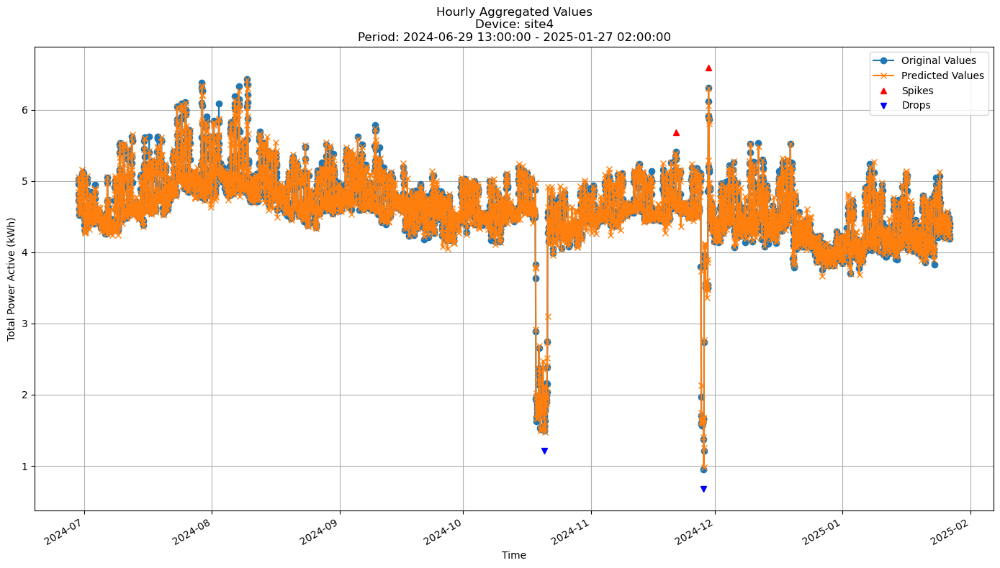


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1374
MAE: 0.0904
MAPE: 2.0389%

Directional Metrics:
Directional Accuracy: 47.5384%
First-Diff Correlation: 0.1038

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.5000
  Recall: 0.5000
  F1 Score: 0.5000
Drops:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000


In [ ]:
for device_id in hoef_all_train_preds.keys():
    y_train = hoef_all_train_preds[device_id][-1]['y_true']
    y_pred_train = hoef_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

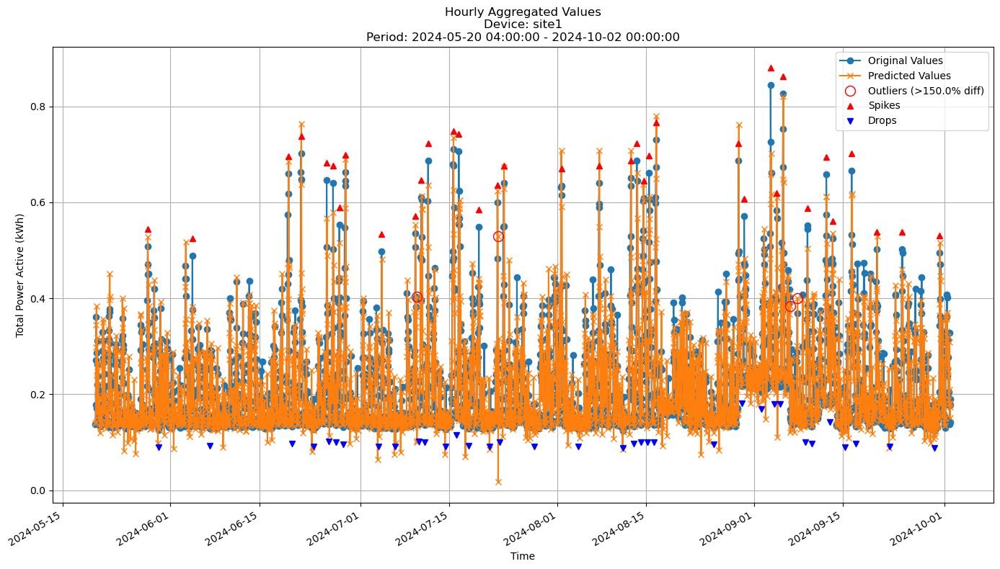


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0574
MAE: 0.0361
MAPE: 15.7234%

Directional Metrics:
Directional Accuracy: 51.9468%
First-Diff Correlation: 0.2915

Immediate Detection (delta=0):
Spikes:
  Precision: 0.3103
  Recall: 0.2500
  F1 Score: 0.2769
Drops:
  Precision: 0.0345
  Recall: 0.0286
  F1 Score: 0.0312

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8276
  Recall: 0.6667
  F1 Score: 0.7385
Drops:
  Precision: 0.1034
  Recall: 0.0857
  F1 Score: 0.0938


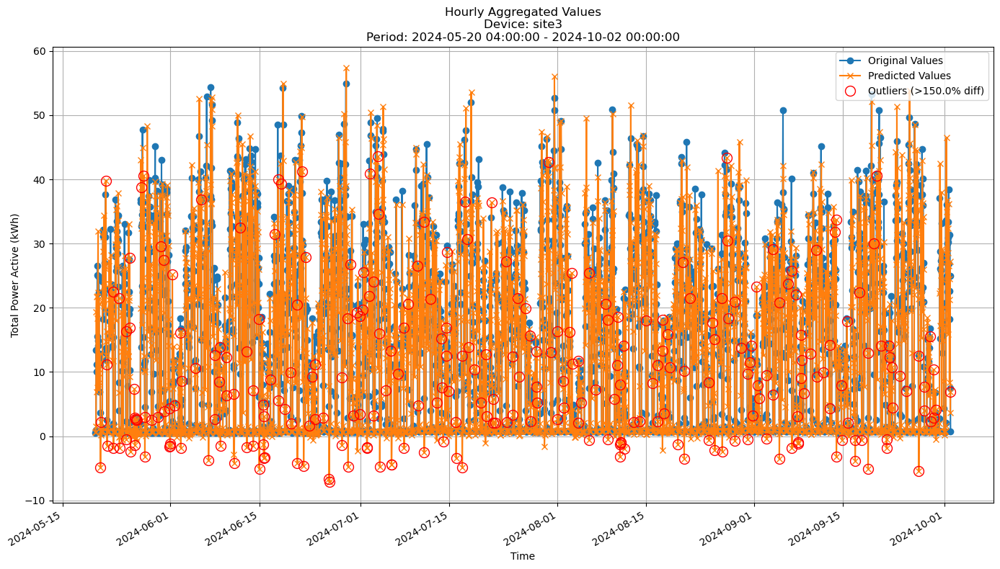


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 7.9630
MAE: 5.1950
MAPE: 65.0702%

Directional Metrics:
Directional Accuracy: 43.8195%
First-Diff Correlation: 0.0480

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


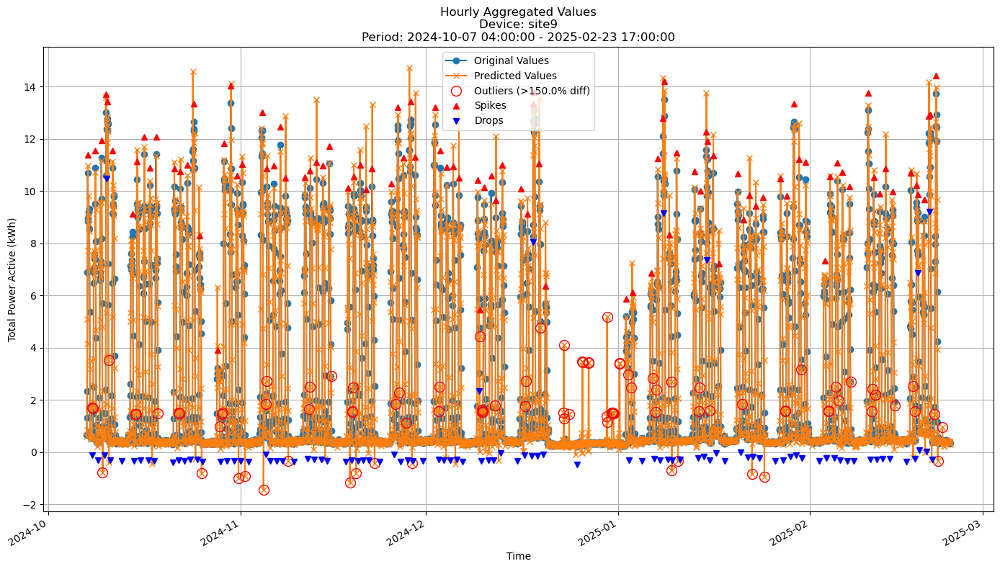


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.9675
MAE: 0.4544
MAPE: 26.1997%

Directional Metrics:
Directional Accuracy: 48.9552%
First-Diff Correlation: 0.4767

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0909
  Recall: 0.1111
  F1 Score: 0.1000
Drops:
  Precision: 0.0500
  Recall: 0.0612
  F1 Score: 0.0550

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7603
  Recall: 0.9293
  F1 Score: 0.8364
Drops:
  Precision: 0.2500
  Recall: 0.3061
  F1 Score: 0.2752


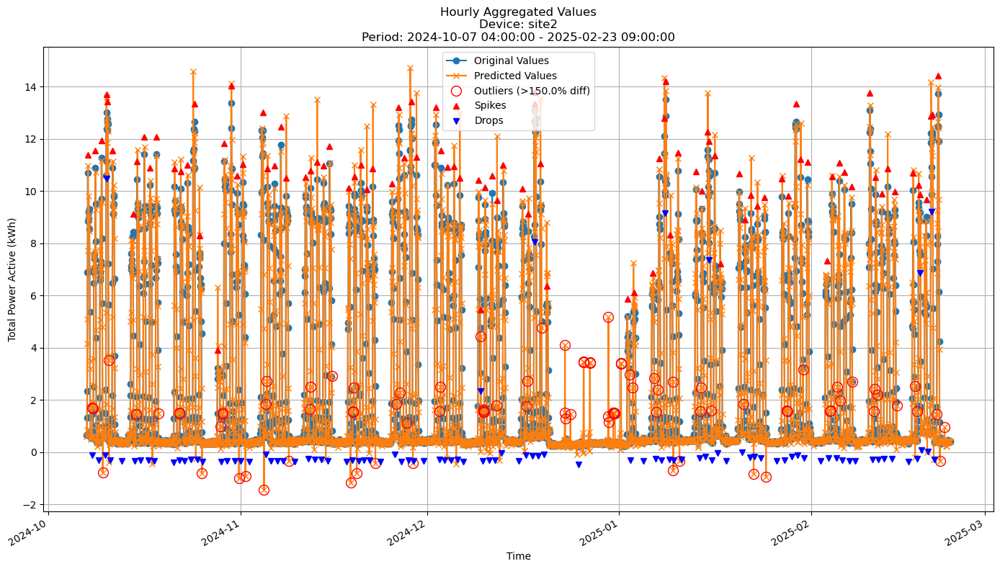


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.9686
MAE: 0.4554
MAPE: 26.2398%

Directional Metrics:
Directional Accuracy: 48.9527%
First-Diff Correlation: 0.4767

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0909
  Recall: 0.1111
  F1 Score: 0.1000
Drops:
  Precision: 0.0500
  Recall: 0.0612
  F1 Score: 0.0550

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7603
  Recall: 0.9293
  F1 Score: 0.8364
Drops:
  Precision: 0.2500
  Recall: 0.3061
  F1 Score: 0.2752


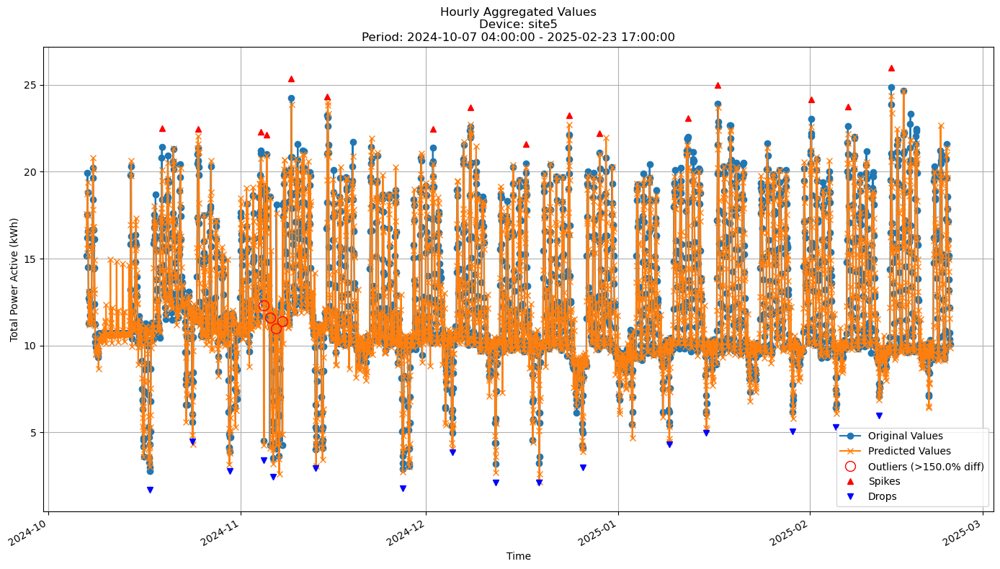


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.2863
MAE: 0.7980
MAPE: 6.4813%

Directional Metrics:
Directional Accuracy: 58.3284%
First-Diff Correlation: 0.2348

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.1667
  Recall: 0.1250
  F1 Score: 0.1429

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.5833
  Recall: 0.4375
  F1 Score: 0.5000
Drops:
  Precision: 0.9167
  Recall: 0.6875
  F1 Score: 0.7857


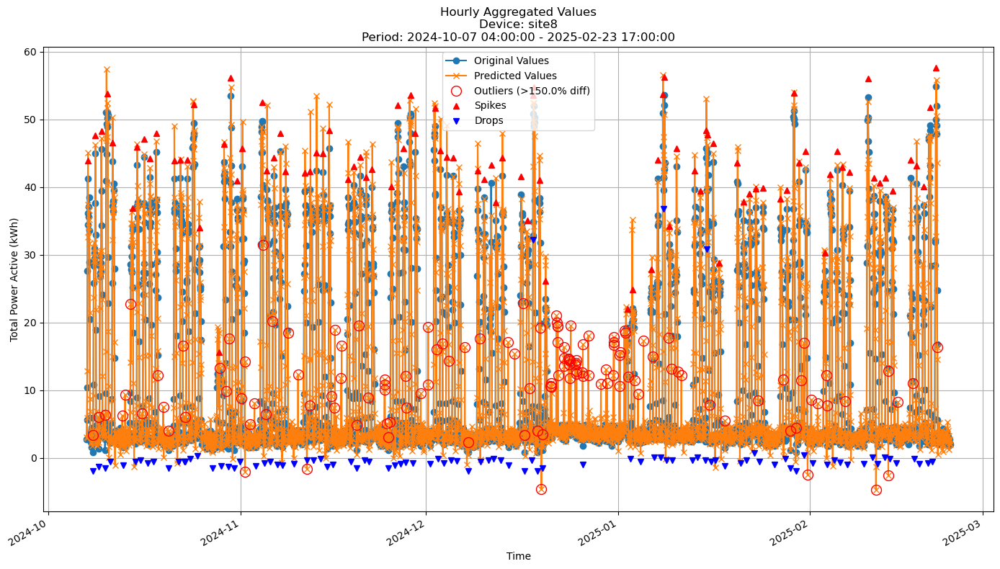


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 4.6455
MAE: 2.5257
MAPE: 36.8316%

Directional Metrics:
Directional Accuracy: 48.4478%
First-Diff Correlation: 0.3032

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0857
  Recall: 0.0947
  F1 Score: 0.0900
Drops:
  Precision: 0.0481
  Recall: 0.0526
  F1 Score: 0.0503

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8000
  Recall: 0.8842
  F1 Score: 0.8400
Drops:
  Precision: 0.2981
  Recall: 0.3263
  F1 Score: 0.3116


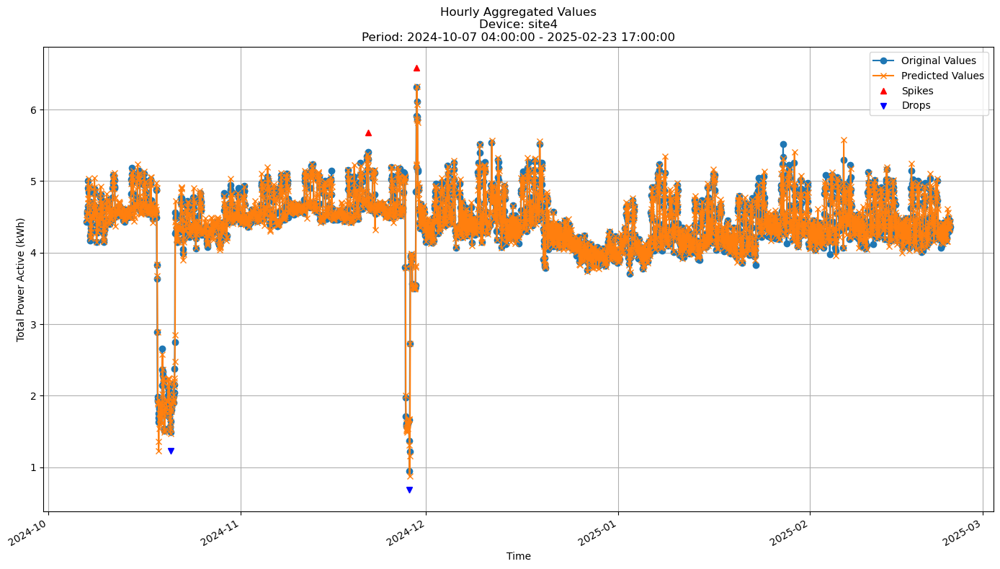


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1708
MAE: 0.1136
MAPE: 2.6753%

Directional Metrics:
Directional Accuracy: 40.8060%
First-Diff Correlation: -0.0909

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.5000
  Recall: 0.5000
  F1 Score: 0.5000
Drops:
  Precision: 0.5000
  Recall: 0.5000
  F1 Score: 0.5000


In [ ]:
join_periods = [-5, -4, -3, -2, -1]
# Device iteration
for device_id in hoef_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, hoef_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, hoef_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (Hoeffding Tree)

In [30]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

arf_hf = ARFRegressor
arf_hf_params = {
    'n_models': 20,
    'max_features': 0.8,
    'aggregation_method': 'mean',
    'grace_period': 24,
    'max_depth': 10,
    'delta': 0.05,  # split confidence
    'tau': 0.05,  # break ties
    'seed': 42
}

In [31]:
arf_hf_all_train_preds, arf_hf_all_valid_preds, \
arf_hf_all_train_metrics, arf_hf_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=arf_hf,
    model_params=arf_hf_params,
    train=train,
    valid=valid,
    use_residuals=USE_RESIDUAL,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/25 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/2 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 04:00:00+01:00 to 2023-03-27 03:00:00+02:00
Model's memory usage: 11.042198 MB
Metrics for Device: site1 | Period: 2023-03-27 04:00:00+02:00 - 2023-04-24 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0596
	MAE: 0.0422
	MAPE: 16.3397%

Directional Metrics:
	Directional Accuracy: 58.8674%
	First-Diff Correlation: 0.2238

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.2609
		Recall: 0.2609
		F1: 0.2609
	Drops:
		Precision: 0.2273
		Recall: 0.2273
		F1: 0.2273

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.6957
		Recall: 0.6957
		F1: 0.6957
	Drops:
		Precision: 0.5455
		Recall: 0.5455
		F1: 0.5455
--------------------------------------------------
Da

Processing devices in split 1:   0%|          | 0/2 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 04:00:00+01:00 to 2023-04-24 03:00:00+02:00
Model's memory usage: 11.882477 MB
Metrics for Device: site1 | Period: 2023-04-24 04:00:00+02:00 - 2023-05-22 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0440
	MAE: 0.0297
	MAPE: 14.7124%

Directional Metrics:
	Directional Accuracy: 53.2042%
	First-Diff Correlation: 0.2273

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0556
		Recall: 0.0465
		F1: 0.0506
	Drops:
		Precision: 0.1143
		Recall: 0.0870
		F1: 0.0988

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.8333
		Recall: 0.6977
		F1: 0.7595
	Drops:
		Precision: 0.7143
		Recall: 0.5435
		F1: 0.6173
--------------------------------------------------
Da

Processing devices in split 2:   0%|          | 0/2 [00:00<?, ?it/s]

... (41 outputs left out)

Processing devices in split 23:   0%|          | 0/7 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 13:00:00+02:00 to 2024-12-30 02:00:00+01:00
Model's memory usage: 16.886116 MB
Metrics for Device: site9 | Period: 2024-12-30 03:00:00+01:00 - 2025-01-27 02:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.7646
	MAE: 0.3660
	MAPE: 30.0434%

Directional Metrics:
	Directional Accuracy: 55.4396%
	First-Diff Correlation: 0.5320

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0833
		Recall: 0.0667
		F1: 0.0741
	Drops:
		Precision: 0.0870
		Recall: 0.0690
		F1: 0.0769

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.7500
		Recall: 0.6000
		F1: 0.6667
	Drops:
		Precision: 0.3043
		Recall: 0.2414
		F1: 0.2692
--------------------------------------------------
Da

Processing devices in split 24:   0%|          | 0/7 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 13:00:00+02:00 to 2025-01-27 02:00:00+01:00
Model's memory usage: 17.407005 MB
Metrics for Device: site9 | Period: 2025-01-27 03:00:00+01:00 - 2025-02-23 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.8854
	MAE: 0.4437
	MAPE: 24.0753%

Directional Metrics:
	Directional Accuracy: 58.4592%
	First-Diff Correlation: 0.5244

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1304
		Recall: 0.1071
		F1: 0.1176
	Drops:
		Precision: 0.2727
		Recall: 0.2222
		F1: 0.2449

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.9565
		Recall: 0.7857
		F1: 0.8627
	Drops:
		Precision: 0.5455
		Recall: 0.4444
		F1: 0.4898
--------------------------------------------------
Da

#### Results

In [ ]:
print("\n\nTrain period metrics:")
arf_hf_all_time_train_metrics = all_time_aggregation_metrics(arf_hf_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
arf_hf_all_time_valid_metrics = all_time_aggregation_metrics(arf_hf_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: site1
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0570 ± 0.0052
	MAE: 0.0387 ± 0.0041
	MAPE: 15.0554% ± 1.4201%

	Directional Metrics:
		Directional Accuracy: 55.0868% ± 4.8964%
		First-Diff Correlation: 0.2171 ± 0.1090

	Immediate Detection (delta=0):
		Spike Precision: 0.1187 ± 0.0424
		Spike Recall: 0.1066 ± 0.0353
		Spike F1: 0.1118 ± 0.0374
		Drop Precision: 0.1146 ± 0.0143
		Drop Recall: 0.1030 ± 0.0233
		Drop F1: 0.1079 ± 0.0184

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.8384 ± 0.0616
		Spike Recall: 0.7712 ± 0.0765
		Spike F1: 0.7992 ± 0.0426
		Drop Precision: 0.6126 ± 0.0474
		Drop Recall: 0.5463 ± 0.0891
		Drop F1: 0.5746 ± 0.0629
Daily Metrics:
	RMSE: 0.2109 ± 0.0498
	MAE: 0.1593 ± 0.0583
	MAPE: 2.5325% ± 1.2518%

	Directional Metrics:
		Directional Accuracy: 97.2854% ± 1.0795%
		First-Diff Correlation: 0.9958 ± 0.0012

	Immediate Detection (delta=0):
		Spik

#### Training plots

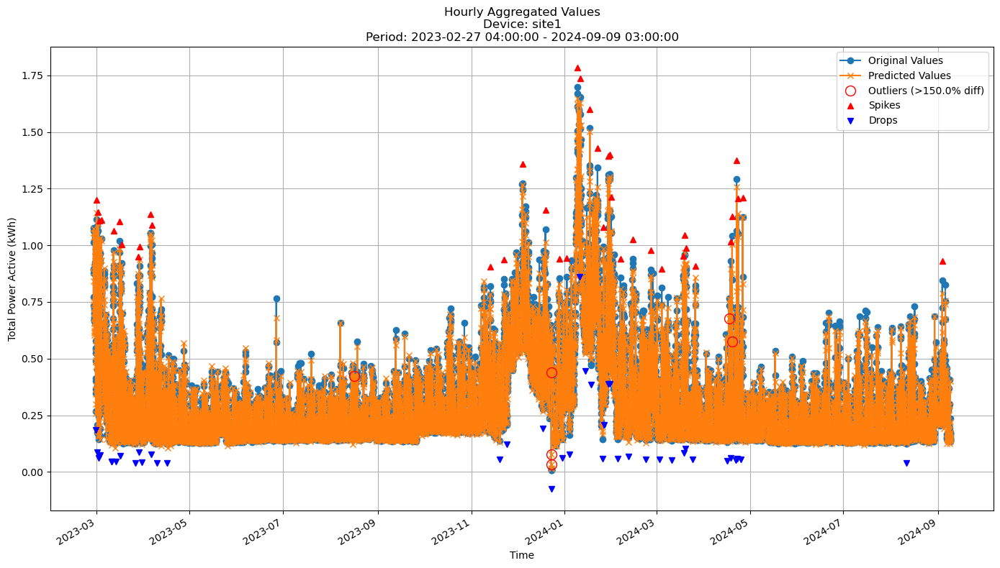


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0608
MAE: 0.0403
MAPE: 15.3625%

Directional Metrics:
Directional Accuracy: 50.1339%
First-Diff Correlation: 0.1205

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0909
  Recall: 0.0769
  F1 Score: 0.0833
Drops:
  Precision: 0.0606
  Recall: 0.0488
  F1 Score: 0.0541

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8788
  Recall: 0.7436
  F1 Score: 0.8056
Drops:
  Precision: 0.7576
  Recall: 0.6098
  F1 Score: 0.6757


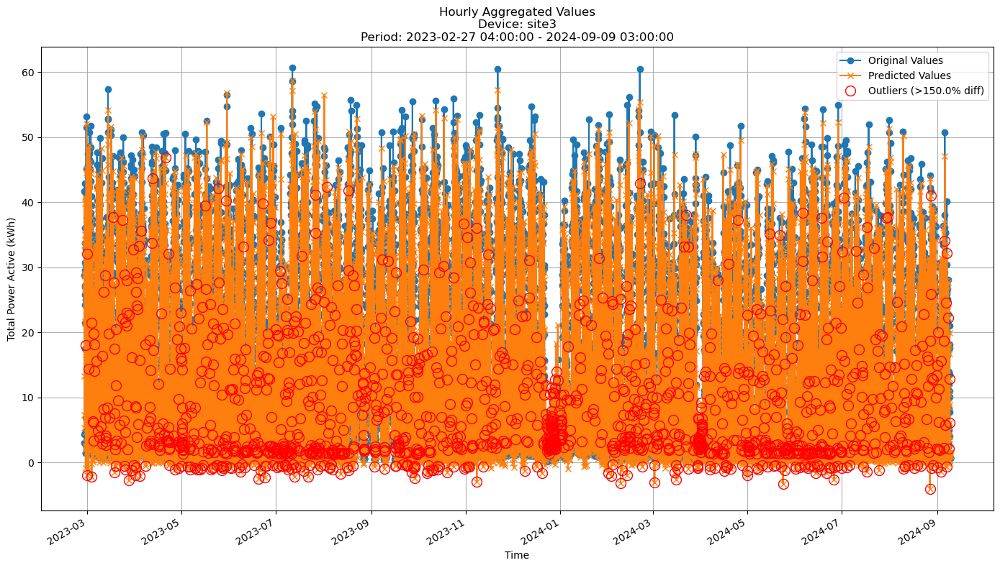


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 7.4520
MAE: 4.9970
MAPE: 73.9417%

Directional Metrics:
Directional Accuracy: 46.3090%
First-Diff Correlation: 0.0344

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


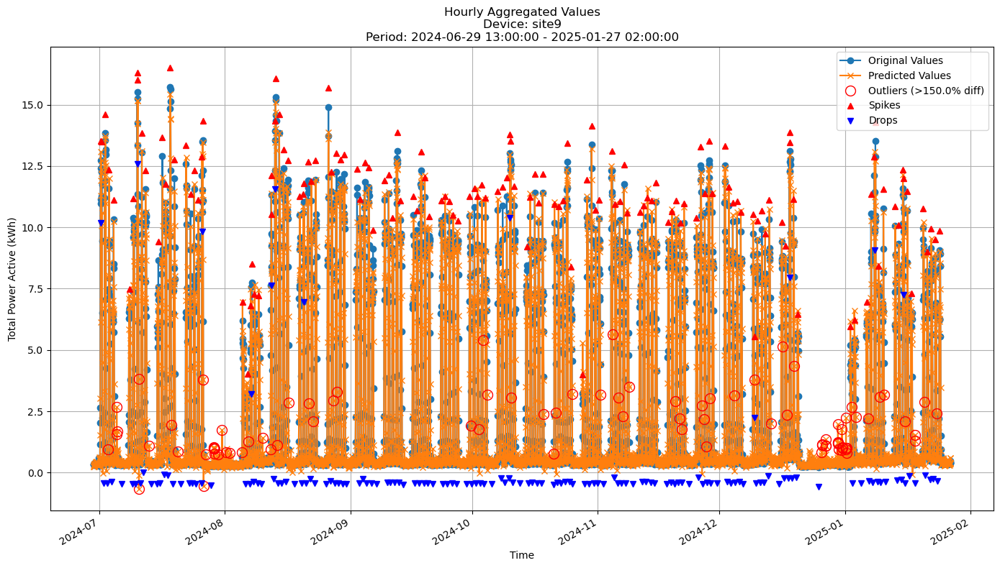


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.8262
MAE: 0.3896
MAPE: 25.1662%

Directional Metrics:
Directional Accuracy: 52.6191%
First-Diff Correlation: 0.5733

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1049
  Recall: 0.1014
  F1 Score: 0.1031
Drops:
  Precision: 0.0423
  Recall: 0.0405
  F1 Score: 0.0414

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.9091
  Recall: 0.8784
  F1 Score: 0.8935
Drops:
  Precision: 0.2817
  Recall: 0.2703
  F1 Score: 0.2759


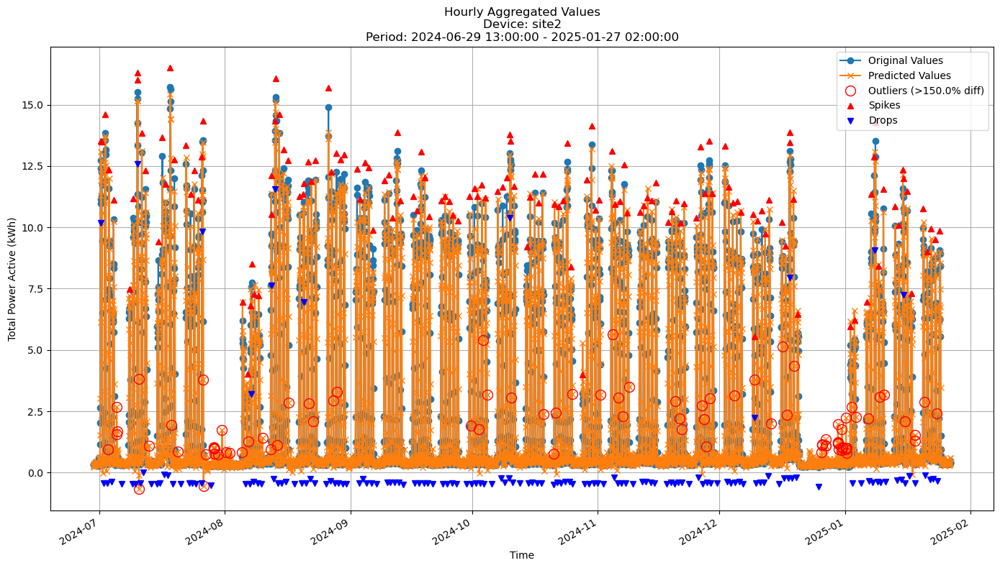


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.8262
MAE: 0.3896
MAPE: 25.1662%

Directional Metrics:
Directional Accuracy: 52.6191%
First-Diff Correlation: 0.5733

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1049
  Recall: 0.1014
  F1 Score: 0.1031
Drops:
  Precision: 0.0423
  Recall: 0.0405
  F1 Score: 0.0414

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.9091
  Recall: 0.8784
  F1 Score: 0.8935
Drops:
  Precision: 0.2817
  Recall: 0.2703
  F1 Score: 0.2759


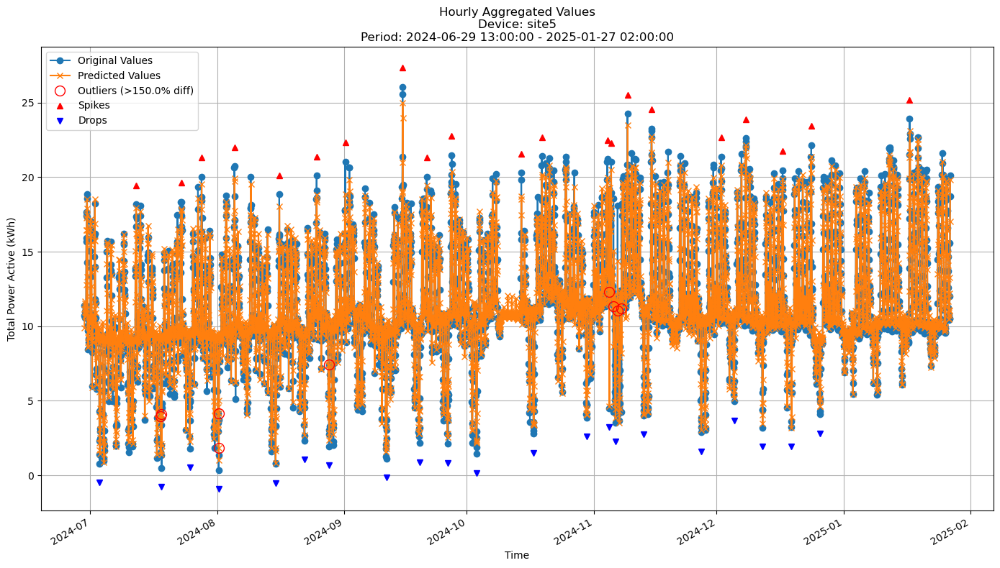


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.1737
MAE: 0.7555
MAPE: 7.8350%

Directional Metrics:
Directional Accuracy: 60.0433%
First-Diff Correlation: 0.2773

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0800
  Recall: 0.0952
  F1 Score: 0.0870
Drops:
  Precision: 0.0800
  Recall: 0.0952
  F1 Score: 0.0870

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.6800
  Recall: 0.8095
  F1 Score: 0.7391
Drops:
  Precision: 0.6800
  Recall: 0.8095
  F1 Score: 0.7391


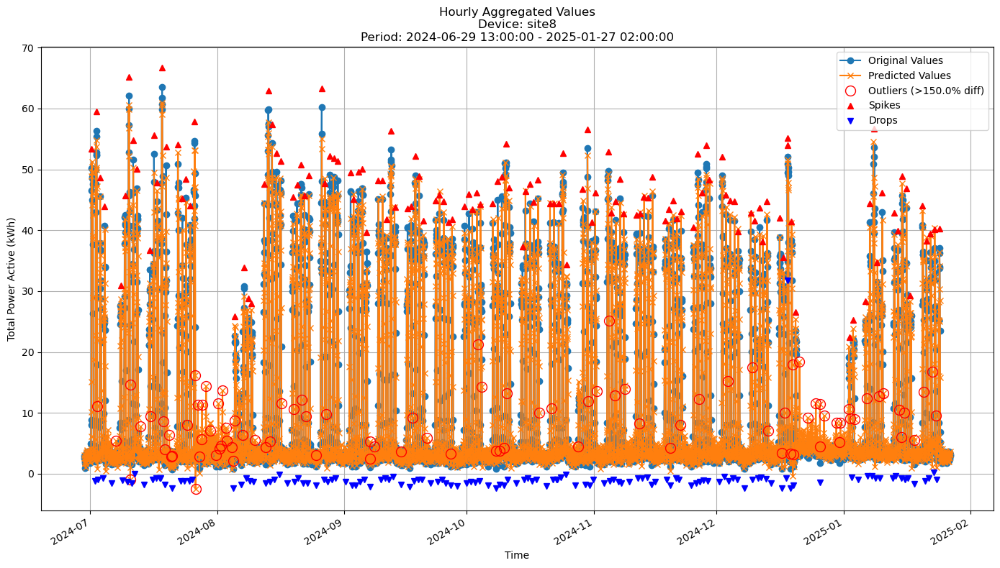


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 3.6942
MAE: 1.9920
MAPE: 29.4277%

Directional Metrics:
Directional Accuracy: 49.1532%
First-Diff Correlation: 0.5140

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0809
  Recall: 0.0815
  F1 Score: 0.0812
Drops:
  Precision: 0.0148
  Recall: 0.0147
  F1 Score: 0.0148

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8897
  Recall: 0.8963
  F1 Score: 0.8930
Drops:
  Precision: 0.4667
  Recall: 0.4632
  F1 Score: 0.4649


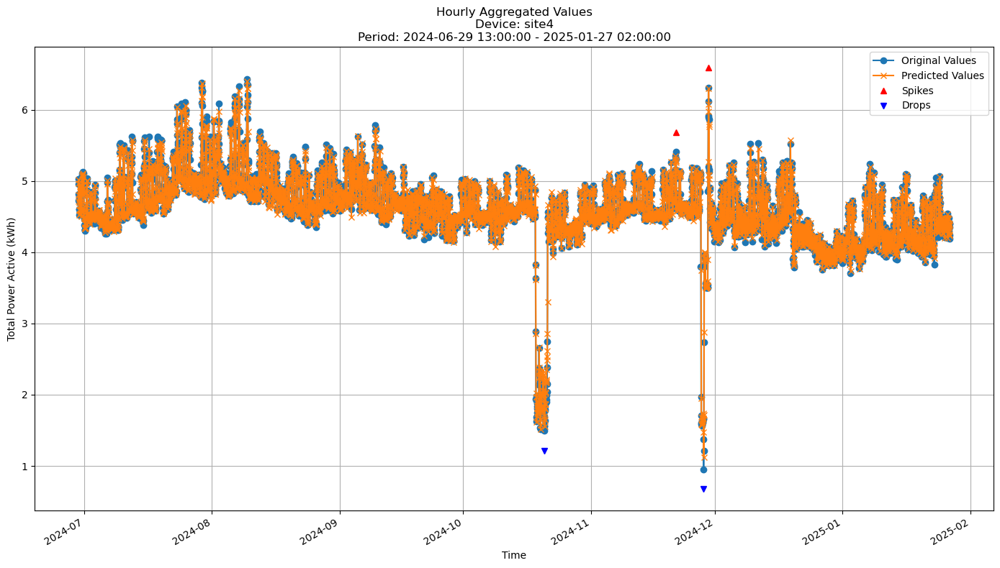


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1308
MAE: 0.0842
MAPE: 1.9102%

Directional Metrics:
Directional Accuracy: 47.5384%
First-Diff Correlation: 0.1045

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.5000
  Recall: 0.5000
  F1 Score: 0.5000
Drops:
  Precision: 0.5000
  Recall: 0.5000
  F1 Score: 0.5000


In [ ]:
for device_id in arf_hf_all_train_preds.keys():
    y_train = arf_hf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_hf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

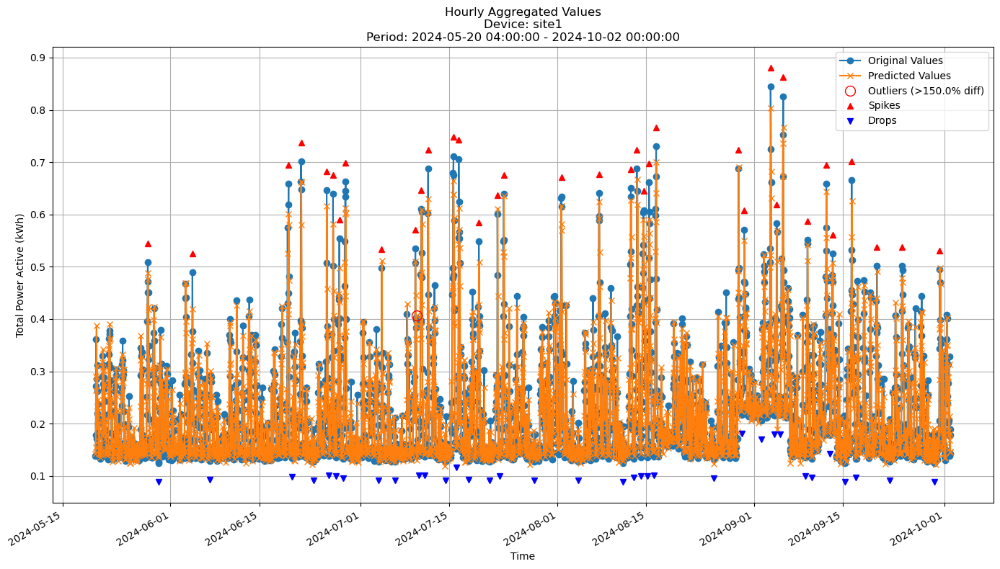


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0602
MAE: 0.0380
MAPE: 16.4432%

Directional Metrics:
Directional Accuracy: 46.4771%
First-Diff Correlation: 0.0372

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1250
  Recall: 0.0833
  F1 Score: 0.1000
Drops:
  Precision: 0.0435
  Recall: 0.0286
  F1 Score: 0.0345

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 0.6667
  F1 Score: 0.8000
Drops:
  Precision: 0.3043
  Recall: 0.2000
  F1 Score: 0.2414


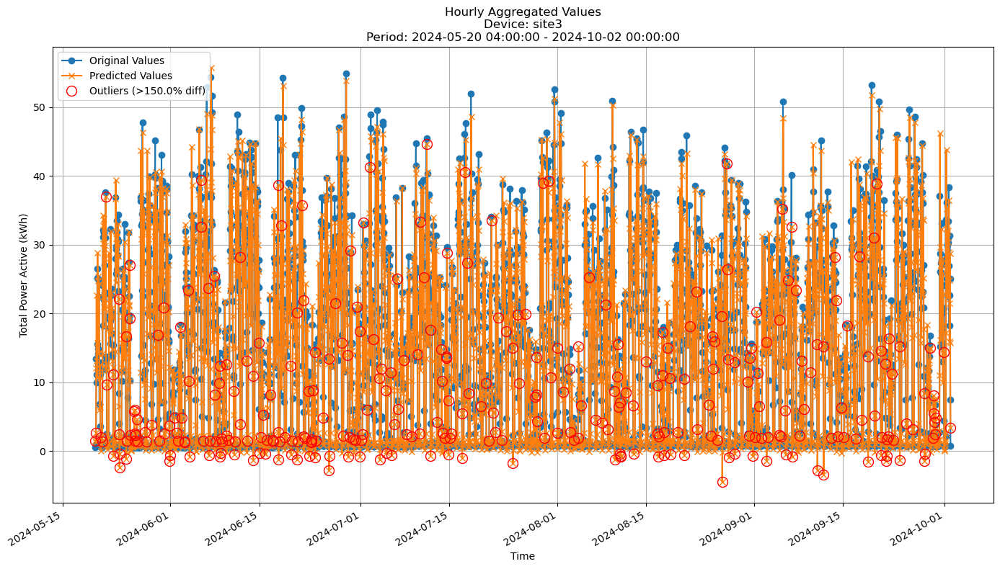


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 7.6550
MAE: 5.1078
MAPE: 72.5926%

Directional Metrics:
Directional Accuracy: 44.7157%
First-Diff Correlation: -0.0155

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


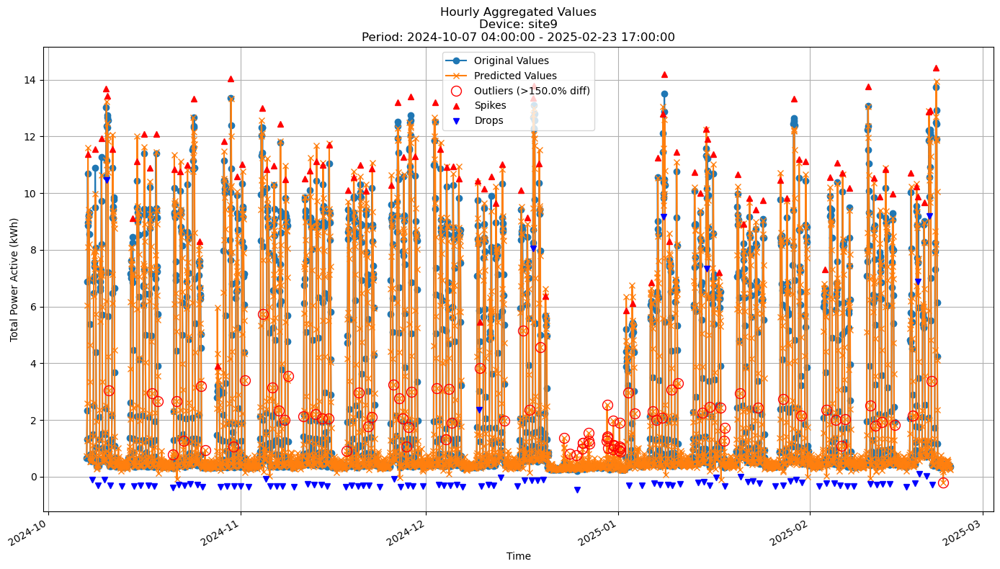


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.8521
MAE: 0.4149
MAPE: 27.1929%

Directional Metrics:
Directional Accuracy: 52.2090%
First-Diff Correlation: 0.5075

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1053
  Recall: 0.1010
  F1 Score: 0.1031
Drops:
  Precision: 0.1277
  Recall: 0.1224
  F1 Score: 0.1250

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.9263
  Recall: 0.8889
  F1 Score: 0.9072
Drops:
  Precision: 0.3617
  Recall: 0.3469
  F1 Score: 0.3542


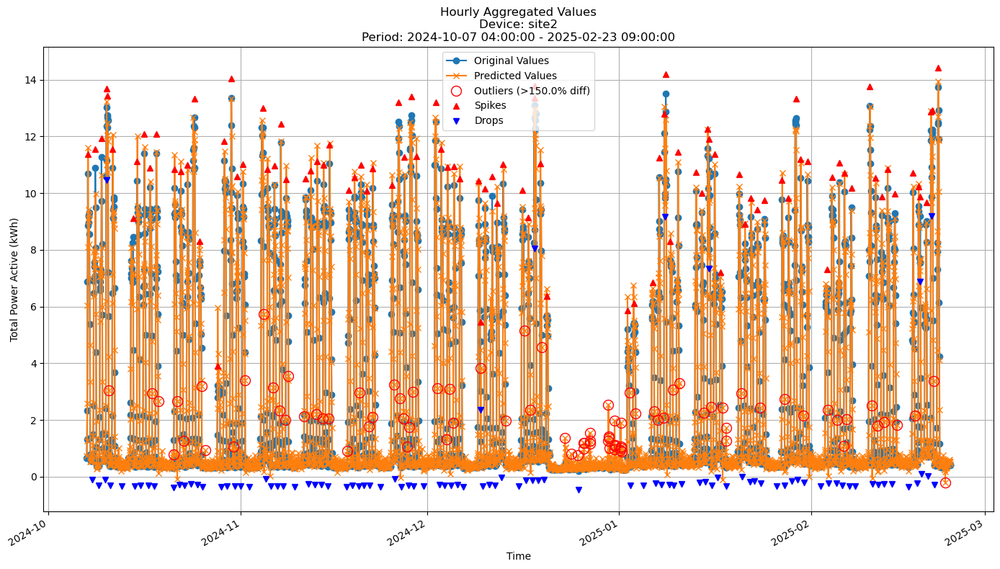


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.8531
MAE: 0.4158
MAPE: 27.2283%

Directional Metrics:
Directional Accuracy: 52.2741%
First-Diff Correlation: 0.5075

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1053
  Recall: 0.1010
  F1 Score: 0.1031
Drops:
  Precision: 0.1277
  Recall: 0.1224
  F1 Score: 0.1250

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.9263
  Recall: 0.8889
  F1 Score: 0.9072
Drops:
  Precision: 0.3617
  Recall: 0.3469
  F1 Score: 0.3542


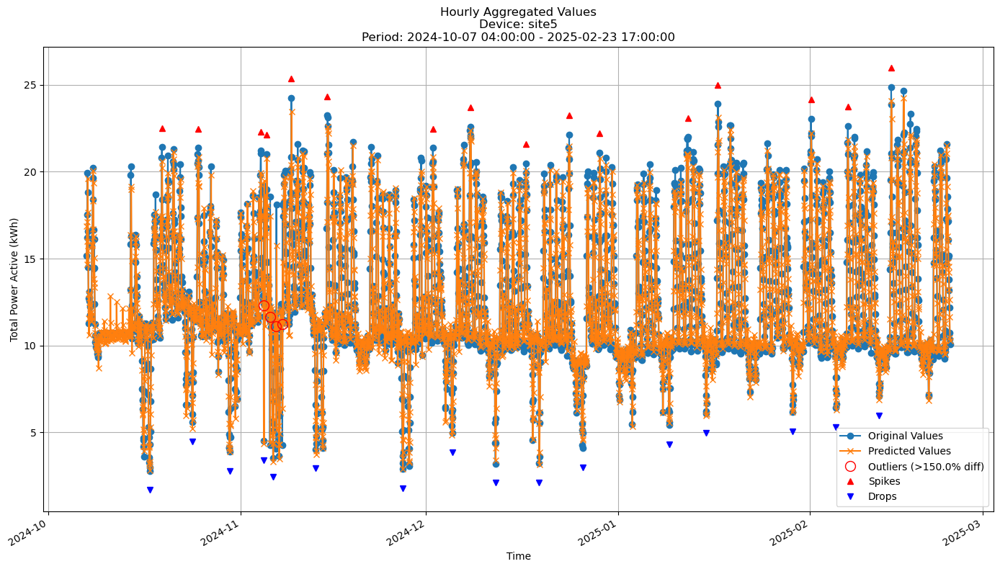


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.2292
MAE: 0.7608
MAPE: 6.1188%

Directional Metrics:
Directional Accuracy: 60.4478%
First-Diff Correlation: 0.2507

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0625
  Recall: 0.0625
  F1 Score: 0.0625
Drops:
  Precision: 0.1765
  Recall: 0.1875
  F1 Score: 0.1818

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8125
  Recall: 0.8125
  F1 Score: 0.8125
Drops:
  Precision: 0.7647
  Recall: 0.8125
  F1 Score: 0.7879


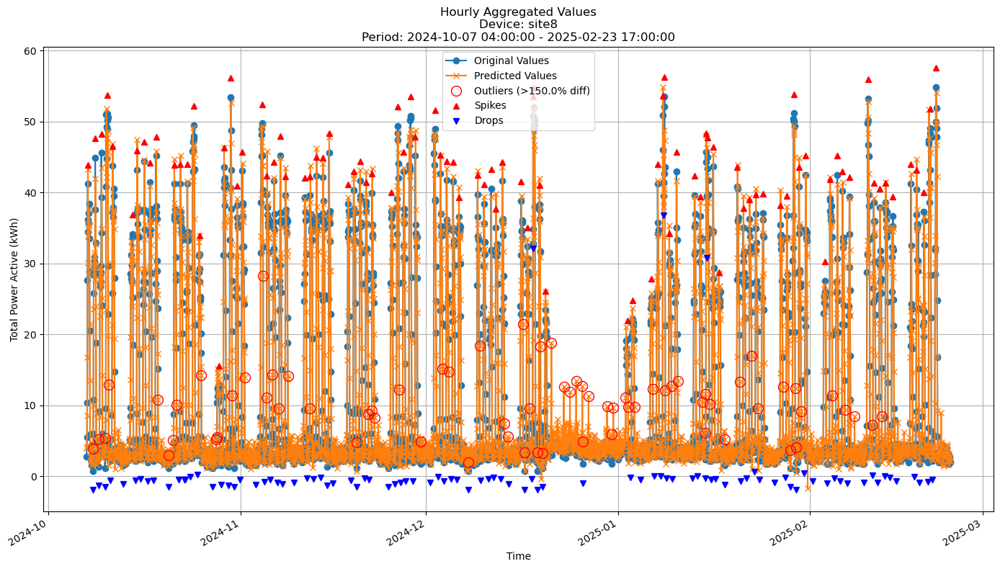


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 3.8785
MAE: 2.1114
MAPE: 30.8779%

Directional Metrics:
Directional Accuracy: 48.7463%
First-Diff Correlation: 0.4232

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0860
  Recall: 0.0842
  F1 Score: 0.0851
Drops:
  Precision: 0.0326
  Recall: 0.0316
  F1 Score: 0.0321

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.9032
  Recall: 0.8842
  F1 Score: 0.8936
Drops:
  Precision: 0.4783
  Recall: 0.4632
  F1 Score: 0.4706


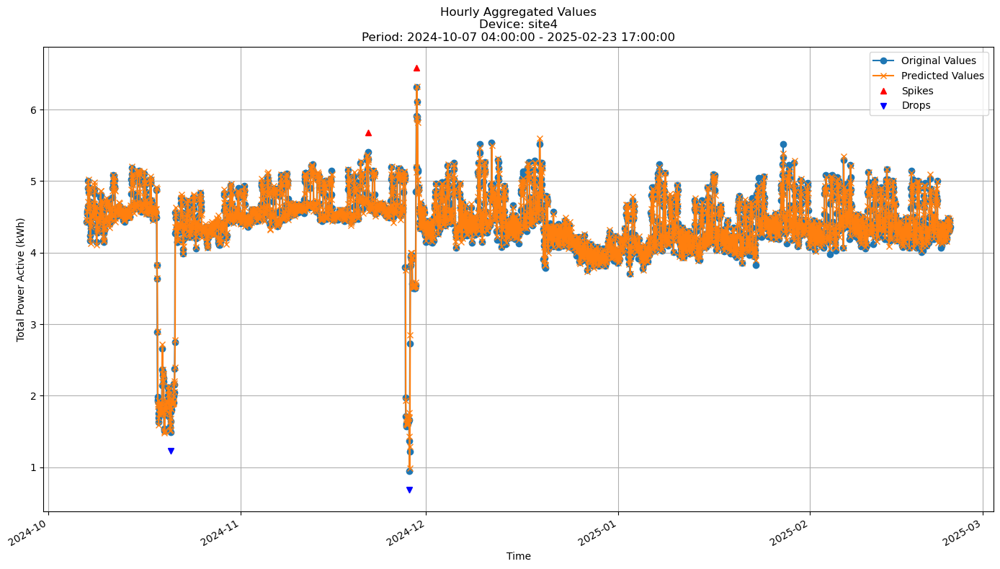


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1663
MAE: 0.1084
MAPE: 2.5368%

Directional Metrics:
Directional Accuracy: 40.5373%
First-Diff Correlation: -0.0976

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.5000
  Recall: 0.5000
  F1 Score: 0.5000
Drops:
  Precision: 0.5000
  Recall: 0.5000
  F1 Score: 0.5000


In [ ]:
join_periods = [-5, -4, -3, -2, -1]
# Device iteration
for device_id in arf_hf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_hf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_hf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

### FastODT

In [35]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

fodt = fastodt.FastODT
fodt_params = {
        'depth': 50, 
         'grace_period': 10, 
         'grace_period_depth': -1, 
         'split_confidence': 0.5, 
         'max_feature': 1.0, 
         'tie_threshold': 0.05, 
         'bin_type': 'adaptive', 
         'max_bins': 32, 
         'split_criterion': 'vr_rel'}

In [36]:
fodt_all_train_preds, fodt_all_valid_preds, \
fodt_all_train_metrics, fodt_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=fodt,
    model_params=fodt_params,
    train=train, 
    valid=valid, 
    use_residuals=USE_RESIDUAL,
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/25 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/2 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 04:00:00+01:00 to 2023-03-27 03:00:00+02:00
Model's memory usage: 1.311424 MB
Metrics for Device: site1 | Period: 2023-03-27 04:00:00+02:00 - 2023-04-24 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0741
	MAE: 0.0507
	MAPE: 19.8502%

Directional Metrics:
	Directional Accuracy: 52.9061%
	First-Diff Correlation: 0.1744

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1852
		Recall: 0.2174
		F1: 0.2000
	Drops:
		Precision: 0.1154
		Recall: 0.1364
		F1: 0.1250

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.7407
		Recall: 0.8696
		F1: 0.8000
	Drops:
		Precision: 0.4231
		Recall: 0.5000
		F1: 0.4583
--------------------------------------------------
Dai

Processing devices in split 1:   0%|          | 0/2 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 04:00:00+01:00 to 2023-04-24 03:00:00+02:00
Model's memory usage: 2.043854 MB
Metrics for Device: site1 | Period: 2023-04-24 04:00:00+02:00 - 2023-05-22 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0511
	MAE: 0.0351
	MAPE: 17.3867%

Directional Metrics:
	Directional Accuracy: 48.4352%
	First-Diff Correlation: 0.2415

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.2222
		Recall: 0.2326
		F1: 0.2273
	Drops:
		Precision: 0.0682
		Recall: 0.0652
		F1: 0.0667

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.7111
		Recall: 0.7442
		F1: 0.7273
	Drops:
		Precision: 0.3182
		Recall: 0.3043
		F1: 0.3111
--------------------------------------------------
Dai

Processing devices in split 2:   0%|          | 0/2 [00:00<?, ?it/s]

... (41 outputs left out)

Processing devices in split 23:   0%|          | 0/7 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 13:00:00+02:00 to 2024-12-30 02:00:00+01:00
Model's memory usage: 5.250999 MB
Metrics for Device: site9 | Period: 2024-12-30 03:00:00+01:00 - 2025-01-27 02:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.0917
	MAE: 0.5000
	MAPE: 29.4199%

Directional Metrics:
	Directional Accuracy: 50.5216%
	First-Diff Correlation: 0.3160

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0233
		Recall: 0.0333
		F1: 0.0274
	Drops:
		Precision: 0.0233
		Recall: 0.0345
		F1: 0.0278

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.5814
		Recall: 0.8333
		F1: 0.6849
	Drops:
		Precision: 0.4186
		Recall: 0.6207
		F1: 0.5000
--------------------------------------------------
Dai

Processing devices in split 24:   0%|          | 0/7 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 13:00:00+02:00 to 2025-01-27 02:00:00+01:00
Model's memory usage: 5.963081 MB
Metrics for Device: site9 | Period: 2025-01-27 03:00:00+01:00 - 2025-02-23 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.3438
	MAE: 0.6719
	MAPE: 36.3189%

Directional Metrics:
	Directional Accuracy: 54.6828%
	First-Diff Correlation: 0.2422

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0625
		Recall: 0.1071
		F1: 0.0789
	Drops:
		Precision: 0.0851
		Recall: 0.1481
		F1: 0.1081

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.5417
		Recall: 0.9286
		F1: 0.6842
	Drops:
		Precision: 0.3617
		Recall: 0.6296
		F1: 0.4595
--------------------------------------------------
Dai

#### Results

In [ ]:
print("\n\nTrain period metrics:")
fodt_all_time_train_metrics = all_time_aggregation_metrics(fodt_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
fodt_all_time_valid_metrics = all_time_aggregation_metrics(fodt_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: site1
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0727 ± 0.0085
	MAE: 0.0486 ± 0.0056
	MAPE: 18.4508% ± 0.8248%

	Directional Metrics:
		Directional Accuracy: 52.9535% ± 1.7347%
		First-Diff Correlation: 0.2092 ± 0.0694

	Immediate Detection (delta=0):
		Spike Precision: 0.1111 ± 0.0345
		Spike Recall: 0.1224 ± 0.0382
		Spike F1: 0.1159 ± 0.0352
		Drop Precision: 0.0875 ± 0.0291
		Drop Recall: 0.0944 ± 0.0353
		Drop F1: 0.0903 ± 0.0311

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.6713 ± 0.0849
		Spike Recall: 0.7420 ± 0.0701
		Spike F1: 0.7009 ± 0.0585
		Drop Precision: 0.3913 ± 0.0641
		Drop Recall: 0.4190 ± 0.0698
		Drop F1: 0.4024 ± 0.0598
Daily Metrics:
	RMSE: 0.4707 ± 0.1444
	MAE: 0.3132 ± 0.0938
	MAPE: 3.9431% ± 0.5174%

	Directional Metrics:
		Directional Accuracy: 92.3270% ± 1.8423%
		First-Diff Correlation: 0.9837 ± 0.0054

	Immediate Detection (delta=0):
		Spik

```

Train period metrics:


==================================================
Aggregated Metrics Across Periods
==================================================
Device ID: site1
--------------------------------------------------
Hourly Metrics:
	RMSE: 1.4286 ± 0.4411
	MAE: 0.4649 ± 0.0949
	MAPE: 154.1858% ± 12.7512%

	Directional Metrics:
		Directional Accuracy: 63.7949% ± 1.4450%
		First-Diff Correlation: 0.0459 ± 0.0963

	Immediate Detection (delta=0):
		Spike Precision: 0.0945 ± 0.0637
		Spike Recall: 0.1248 ± 0.0342
		Spike F1: 0.1023 ± 0.0492
		Drop Precision: 0.0928 ± 0.0243
		Drop Recall: 0.1472 ± 0.0543
		Drop F1: 0.1082 ± 0.0211

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.2370 ± 0.1074
		Spike Recall: 0.3507 ± 0.0532
		Spike F1: 0.2679 ± 0.0703
		Drop Precision: 0.1830 ± 0.0423
		Drop Recall: 0.3002 ± 0.1367
		Drop F1: 0.2161 ± 0.0506
Daily Metrics:
	RMSE: 20.4400 ± 7.4693
	MAE: 10.7240 ± 2.2030
	MAPE: 140.4382% ± 15.5932%

	Directional Metrics:
		Directional Accuracy: 69.0647% ± 1.8056%
		First-Diff Correlation: 0.5645 ± 0.0631

	Immediate Detection (delta=0):
		Spike Precision: 0.3597 ± 0.1428
		Spike Recall: 0.6779 ± 0.2191
		Spike F1: 0.4554 ± 0.1511
		Drop Precision: 0.2963 ± 0.1443
		Drop Recall: 0.5238 ± 0.1866
		Drop F1: 0.3630 ± 0.1328

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.4043 ± 0.1354
		Spike Recall: 0.7713 ± 0.2297
		Spike F1: 0.5155 ± 0.1490
		Drop Precision: 0.4329 ± 0.1644
		Drop Recall: 0.7762 ± 0.2140
		Drop F1: 0.5371 ± 0.1586
Weekly Metrics:
	RMSE: 113.7435 ± 37.9546
	MAE: 72.5625 ± 15.5612
	MAPE: 142.3324% ± 16.4446%
28_days Metrics:
	RMSE: 360.8309 ± 118.6854
	MAE: 263.8197 ± 64.2663
	MAPE: 149.4141% ± 21.0361%
==================================================
Device ID: site3
--------------------------------------------------
Hourly Metrics:
	RMSE: 11.5669 ± 1.4555
	MAE: 8.0340 ± 1.0846
	MAPE: 111.1159% ± 6.0388%

	Directional Metrics:
		Directional Accuracy: 62.6447% ± 3.8172%
		First-Diff Correlation: 0.5265 ± 0.0533

	Immediate Detection (delta=0):
		Spike Precision: 0.0630 ± 0.0472
		Spike Recall: 0.0105 ± 0.0087
		Spike F1: 0.0177 ± 0.0140
		Drop Precision: 0.1906 ± 0.1411
		Drop Recall: 0.0133 ± 0.0121
		Drop F1: 0.0218 ± 0.0153

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.1596 ± 0.1153
		Spike Recall: 0.0262 ± 0.0204
		Spike F1: 0.0442 ± 0.0332
		Drop Precision: 0.4194 ± 0.2593
		Drop Recall: 0.0504 ± 0.0704
		Drop F1: 0.0571 ± 0.0369
Daily Metrics:
	RMSE: 172.6580 ± 26.0863
	MAE: 146.3021 ± 23.9399
	MAPE: 41.7586% ± 4.0344%

	Directional Metrics:
		Directional Accuracy: 81.5129% ± 2.2913%
		First-Diff Correlation: 0.8680 ± 0.0527

	Immediate Detection (delta=0):
		Spike Precision: 0.3788 ± 0.1361
		Spike Recall: 0.5379 ± 0.1611
		Spike F1: 0.4389 ± 0.1422
		Drop Precision: 0.5538 ± 0.1801
		Drop Recall: 0.7194 ± 0.1023
		Drop F1: 0.6031 ± 0.1125

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.5900 ± 0.2319
		Spike Recall: 0.8119 ± 0.2027
		Spike F1: 0.6742 ± 0.2186
		Drop Precision: 0.6804 ± 0.1865
		Drop Recall: 0.8966 ± 0.1323
		Drop F1: 0.7489 ± 0.1365
Weekly Metrics:
	RMSE: 971.9025 ± 152.7558
	MAE: 902.1004 ± 139.8825
	MAPE: 33.8709% ± 3.7386%
28_days Metrics:
	RMSE: 3496.3959 ± 412.0541
	MAE: 3151.8350 ± 226.5504
	MAPE: 31.4738% ± 3.8223%
==================================================
Device ID: site4
--------------------------------------------------
Hourly Metrics:
	RMSE: 7.2047 ± 0.1088
	MAE: 5.8004 ± 0.0861
	MAPE: 122.7946% ± 6.2983%

	Directional Metrics:
		Directional Accuracy: 51.1547% ± 0.5179%
		First-Diff Correlation: 0.0186 ± 0.0173

	Immediate Detection (delta=0):
		Spike Precision: 0.0430 ± 0.0220
		Spike Recall: 0.0769 ± 0.0120
		Spike F1: 0.0537 ± 0.0183
		Drop Precision: 0.0219 ± 0.0096
		Drop Recall: 0.0463 ± 0.0214
		Drop F1: 0.0296 ± 0.0130

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.2057 ± 0.0498
		Spike Recall: 0.3891 ± 0.0493
		Spike F1: 0.2640 ± 0.0395
		Drop Precision: 0.0536 ± 0.0238
		Drop Recall: 0.0945 ± 0.0143
		Drop F1: 0.0664 ± 0.0186
Daily Metrics:
	RMSE: 122.3920 ± 3.3864
	MAE: 113.0393 ± 4.2904
	MAPE: 101.4446% ± 6.2264%

	Directional Metrics:
		Directional Accuracy: 64.9284% ± 1.3102%
		First-Diff Correlation: 0.4384 ± 0.0827

	Immediate Detection (delta=0):
		Spike Precision: 0.0151 ± 0.0196
		Spike Recall: 0.1250 ± 0.1614
		Spike F1: 0.0270 ± 0.0350
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0221 ± 0.0227
		Spike Recall: 0.1875 ± 0.1943
		Spike F1: 0.0395 ± 0.0405
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000
Weekly Metrics:
	RMSE: 744.0829 ± 66.3055
	MAE: 688.2735 ± 105.1532
	MAPE: 93.2305% ± 10.0279%
28_days Metrics:
	RMSE: 2808.1318 ± 427.2894
	MAE: 2750.4929 ± 422.6597
	MAPE: 101.6742% ± 6.1800%
==================================================
Device ID: site5
--------------------------------------------------
Hourly Metrics:
	RMSE: 7.1001 ± 0.1762
	MAE: 5.7555 ± 0.1221
	MAPE: 66.2675% ± 8.1382%

	Directional Metrics:
		Directional Accuracy: 49.6081% ± 1.7725%
		First-Diff Correlation: -0.0996 ± 0.0138

	Immediate Detection (delta=0):
		Spike Precision: 0.0350 ± 0.0220
		Spike Recall: 0.0310 ± 0.0204
		Spike F1: 0.0329 ± 0.0211
		Drop Precision: 0.0128 ± 0.0095
		Drop Recall: 0.0108 ± 0.0076
		Drop F1: 0.0117 ± 0.0084

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0821 ± 0.0119
		Spike Recall: 0.0723 ± 0.0103
		Spike F1: 0.0769 ± 0.0109
		Drop Precision: 0.0287 ± 0.0171
		Drop Recall: 0.0246 ± 0.0142
		Drop F1: 0.0265 ± 0.0155
Daily Metrics:
	RMSE: 72.5536 ± 6.0504
	MAE: 63.1687 ± 4.2827
	MAPE: 27.2779% ± 1.6561%

	Directional Metrics:
		Directional Accuracy: 55.3416% ± 4.8641%
		First-Diff Correlation: 0.3503 ± 0.1151

	Immediate Detection (delta=0):
		Spike Precision: 0.0208 ± 0.0551
		Spike Recall: 0.0312 ± 0.0827
		Spike F1: 0.0250 ± 0.0661
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.3750 ± 0.3975
		Spike Recall: 0.0878 ± 0.0838
		Spike F1: 0.1216 ± 0.1029
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000
Weekly Metrics:
	RMSE: 167.7174 ± 47.6658
	MAE: 145.0577 ± 39.8770
	MAPE: 15.7286% ± 6.2873%
28_days Metrics:
	RMSE: 567.2156 ± 260.0607
	MAE: 496.8963 ± 223.2519
	MAPE: 7.9982% ± 2.5192%
==================================================
Device ID: site8
--------------------------------------------------
Hourly Metrics:
	RMSE: 12.6180 ± 0.4301
	MAE: 9.3018 ± 0.2926
	MAPE: 170.1830% ± 4.8446%

	Directional Metrics:
		Directional Accuracy: 55.8814% ± 0.4535%
		First-Diff Correlation: 0.2770 ± 0.0194

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0675 ± 0.0323
		Drop Recall: 0.0441 ± 0.0232
		Drop F1: 0.0532 ± 0.0269

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.3221 ± 0.0573
		Drop Recall: 0.1984 ± 0.0158
		Drop F1: 0.2443 ± 0.0233
Daily Metrics:
	RMSE: 121.2843 ± 7.3768
	MAE: 107.5501 ± 5.9390
	MAPE: 83.3115% ± 9.1902%

	Directional Metrics:
		Directional Accuracy: 70.3931% ± 4.6669%
		First-Diff Correlation: 0.7882 ± 0.0525

	Immediate Detection (delta=0):
		Spike Precision: 0.0601 ± 0.0559
		Spike Recall: 0.1874 ± 0.3129
		Spike F1: 0.0764 ± 0.0691
		Drop Precision: 0.2129 ± 0.1830
		Drop Recall: 0.2998 ± 0.2383
		Drop F1: 0.2475 ± 0.2041

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.2720 ± 0.1944
		Spike Recall: 0.4892 ± 0.3140
		Spike F1: 0.3243 ± 0.2143
		Drop Precision: 0.4358 ± 0.3483
		Drop Recall: 0.6250 ± 0.4841
		Drop F1: 0.5107 ± 0.3995
Weekly Metrics:
	RMSE: 367.8093 ± 70.2237
	MAE: 284.2988 ± 56.1231
	MAPE: 40.3974% ± 14.2109%
28_days Metrics:
	RMSE: 820.4173 ± 289.0154
	MAE: 742.9542 ± 275.4982
	MAPE: 14.3376% ± 12.4256%
==================================================
Device ID: site9
--------------------------------------------------
Hourly Metrics:
	RMSE: 5.7836 ± 0.1403
	MAE: 2.8282 ± 0.1197
	MAPE: 265.3842% ± 9.8812%

	Directional Metrics:
		Directional Accuracy: 56.1699% ± 0.9240%
		First-Diff Correlation: 0.2290 ± 0.0405

	Immediate Detection (delta=0):
		Spike Precision: 0.1096 ± 0.0110
		Spike Recall: 0.2695 ± 0.0391
		Spike F1: 0.1557 ± 0.0174
		Drop Precision: 0.0456 ± 0.0099
		Drop Recall: 0.1107 ± 0.0224
		Drop F1: 0.0646 ± 0.0137

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.2966 ± 0.0195
		Spike Recall: 0.7280 ± 0.0769
		Spike F1: 0.4212 ± 0.0316
		Drop Precision: 0.1371 ± 0.0128
		Drop Recall: 0.3335 ± 0.0337
		Drop F1: 0.1942 ± 0.0180
Daily Metrics:
	RMSE: 75.9224 ± 2.2358
	MAE: 58.7399 ± 3.8585
	MAPE: 89.9029% ± 3.5175%

	Directional Metrics:
		Directional Accuracy: 71.6727% ± 2.3395%
		First-Diff Correlation: 0.8671 ± 0.0193

	Immediate Detection (delta=0):
		Spike Precision: 0.0789 ± 0.0587
		Spike Recall: 0.1904 ± 0.3103
		Spike F1: 0.0971 ± 0.0869
		Drop Precision: 0.3151 ± 0.2497
		Drop Recall: 0.3689 ± 0.2877
		Drop F1: 0.3389 ± 0.2658

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.3344 ± 0.2253
		Spike Recall: 0.4891 ± 0.3131
		Spike F1: 0.3717 ± 0.2311
		Drop Precision: 0.4978 ± 0.3925
		Drop Recall: 0.5830 ± 0.4519
		Drop F1: 0.5353 ± 0.4173
Weekly Metrics:
	RMSE: 406.6172 ± 39.8134
	MAE: 358.5418 ± 62.1463
	MAPE: 89.8596% ± 5.4210%
28_days Metrics:
	RMSE: 1482.0490 ± 251.4957
	MAE: 1434.1671 ± 248.5852
	MAPE: 100.6348% ± 11.5976%
==================================================
Device ID: site2
--------------------------------------------------
Hourly Metrics:
	RMSE: 5.7677 ± 0.1537
	MAE: 2.8198 ± 0.1269
	MAPE: 264.2847% ± 10.9065%

	Directional Metrics:
		Directional Accuracy: 56.2055% ± 0.9262%
		First-Diff Correlation: 0.2297 ± 0.0402

	Immediate Detection (delta=0):
		Spike Precision: 0.1127 ± 0.0120
		Spike Recall: 0.2768 ± 0.0375
		Spike F1: 0.1601 ± 0.0180
		Drop Precision: 0.0461 ± 0.0103
		Drop Recall: 0.1117 ± 0.0227
		Drop F1: 0.0652 ± 0.0141

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.2999 ± 0.0175
		Spike Recall: 0.7354 ± 0.0651
		Spike F1: 0.4257 ± 0.0269
		Drop Precision: 0.1375 ± 0.0142
		Drop Recall: 0.3344 ± 0.0349
		Drop F1: 0.1948 ± 0.0195
Daily Metrics:
	RMSE: 75.6948 ± 2.4162
	MAE: 58.5538 ± 4.0795
	MAPE: 89.5460% ± 3.8834%

	Directional Metrics:
		Directional Accuracy: 72.4540% ± 3.8659%
		First-Diff Correlation: 0.8664 ± 0.0205

	Immediate Detection (delta=0):
		Spike Precision: 0.0830 ± 0.0655
		Spike Recall: 0.1904 ± 0.3103
		Spike F1: 0.1030 ± 0.1002
		Drop Precision: 0.3151 ± 0.2497
		Drop Recall: 0.3689 ± 0.2877
		Drop F1: 0.3389 ± 0.2658

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.3385 ± 0.2225
		Spike Recall: 0.4891 ± 0.3131
		Spike F1: 0.3777 ± 0.2294
		Drop Precision: 0.4978 ± 0.3925
		Drop Recall: 0.5830 ± 0.4519
		Drop F1: 0.5353 ± 0.4173
Weekly Metrics:
	RMSE: 405.4382 ± 41.4482
	MAE: 357.6252 ± 63.3554
	MAPE: 89.4626% ± 6.0151%
28_days Metrics:
	RMSE: 1478.1633 ± 256.4983
	MAE: 1430.5009 ± 253.4215
	MAPE: 100.3042% ± 11.5080%
==================================================

\Valid period metrics:


==================================================
Aggregated Metrics Across Periods
==================================================
Device ID: site1
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.9517 ± 1.3326
	MAE: 0.4789 ± 0.5493
	MAPE: 160.8027% ± 43.0824%

	Directional Metrics:
		Directional Accuracy: 59.4841% ± 3.0337%
		First-Diff Correlation: 0.1607 ± 0.1725

	Immediate Detection (delta=0):
		Spike Precision: 0.1808 ± 0.1957
		Spike Recall: 0.1208 ± 0.0885
		Spike F1: 0.1298 ± 0.1186
		Drop Precision: 0.0945 ± 0.0706
		Drop Recall: 0.0973 ± 0.0820
		Drop F1: 0.0828 ± 0.0591

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.3351 ± 0.2361
		Spike Recall: 0.2752 ± 0.1159
		Spike F1: 0.2588 ± 0.1325
		Drop Precision: 0.1761 ± 0.1247
		Drop Recall: 0.2038 ± 0.1785
		Drop F1: 0.1574 ± 0.1118
Daily Metrics:
	RMSE: 14.5838 ± 20.9681
	MAE: 10.6832 ± 12.1654
	MAPE: 143.0981% ± 40.2923%

	Directional Metrics:
		Directional Accuracy: 67.8649% ± 7.5689%
		First-Diff Correlation: 0.5882 ± 0.1056

	Immediate Detection (delta=0):
		Spike Precision: 0.2475 ± 0.2703
		Spike Recall: 0.4333 ± 0.4453
		Spike F1: 0.3010 ± 0.3107
		Drop Precision: 0.2375 ± 0.3701
		Drop Recall: 0.2917 ± 0.4278
		Drop F1: 0.2433 ± 0.3616

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.4058 ± 0.3076
		Spike Recall: 0.6417 ± 0.4258
		Spike F1: 0.4679 ± 0.3155
		Drop Precision: 0.3125 ± 0.3978
		Drop Recall: 0.3917 ± 0.4633
		Drop F1: 0.3267 ± 0.3943
Weekly Metrics:
	RMSE: 78.4506 ± 101.4114
	MAE: 61.9615 ± 70.3464
	MAPE: 142.7509% ± 41.8130%
28_days Metrics:
	RMSE: 219.1738 ± 248.5095
	MAE: 157.4884 ± 175.2153
	MAPE: 148.2634% ± 48.2707%
==================================================
Device ID: site3
--------------------------------------------------
Hourly Metrics:
	RMSE: 10.9856 ± 1.6665
	MAE: 7.5816 ± 1.2908
	MAPE: 123.2313% ± 29.9137%

	Directional Metrics:
		Directional Accuracy: 58.0760% ± 3.3480%
		First-Diff Correlation: 0.4170 ± 0.0758

	Immediate Detection (delta=0):
		Spike Precision: 0.0217 ± 0.0669
		Spike Recall: 0.0058 ± 0.0214
		Spike F1: 0.0088 ± 0.0316
		Drop Precision: 0.1696 ± 0.3068
		Drop Recall: 0.0339 ± 0.0653
		Drop F1: 0.0464 ± 0.0842

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0476 ± 0.1023
		Spike Recall: 0.0284 ± 0.0531
		Spike F1: 0.0279 ± 0.0534
		Drop Precision: 0.2625 ± 0.3603
		Drop Recall: 0.0738 ± 0.1239
		Drop F1: 0.0955 ± 0.1512
Daily Metrics:
	RMSE: 153.2790 ± 37.8610
	MAE: 126.7289 ± 33.1132
	MAPE: 45.8233% ± 17.1199%

	Directional Metrics:
		Directional Accuracy: 76.1568% ± 8.3840%
		First-Diff Correlation: 0.8191 ± 0.0897

	Immediate Detection (delta=0):
		Spike Precision: 0.2167 ± 0.2986
		Spike Recall: 0.2667 ± 0.3704
		Spike F1: 0.2333 ± 0.3187
		Drop Precision: 0.4000 ± 0.3590
		Drop Recall: 0.5250 ± 0.4225
		Drop F1: 0.4367 ± 0.3616

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.4083 ± 0.3435
		Spike Recall: 0.5417 ± 0.4212
		Spike F1: 0.4517 ± 0.3547
		Drop Precision: 0.4667 ± 0.3712
		Drop Recall: 0.6167 ± 0.4349
		Drop F1: 0.5133 ± 0.3764
Weekly Metrics:
	RMSE: 753.5966 ± 244.0231
	MAE: 636.7292 ± 231.9271
	MAPE: 31.3748% ± 11.5298%
28_days Metrics:
	RMSE: 2199.5025 ± 868.6285
	MAE: 1593.7725 ± 649.8763
	MAPE: 30.4113% ± 17.6259%
==================================================
Device ID: site4
--------------------------------------------------
Hourly Metrics:
	RMSE: 7.3202 ± 0.1849
	MAE: 5.8934 ± 0.1437
	MAPE: 130.5138% ± 12.8996%

	Directional Metrics:
		Directional Accuracy: 49.9876% ± 2.2315%
		First-Diff Correlation: -0.0185 ± 0.0428

	Immediate Detection (delta=0):
		Spike Precision: 0.0576 ± 0.0415
		Spike Recall: 0.0491 ± 0.0325
		Spike F1: 0.0502 ± 0.0319
		Drop Precision: 0.0447 ± 0.0635
		Drop Recall: 0.0380 ± 0.0393
		Drop F1: 0.0385 ± 0.0440

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.2645 ± 0.1393
		Spike Recall: 0.2468 ± 0.1333
		Spike F1: 0.2463 ± 0.1269
		Drop Precision: 0.1092 ± 0.1266
		Drop Recall: 0.0902 ± 0.0738
		Drop F1: 0.0945 ± 0.0882
Daily Metrics:
	RMSE: 123.3938 ± 6.2612
	MAE: 114.1434 ± 5.9808
	MAPE: 107.0105% ± 12.3918%

	Directional Metrics:
		Directional Accuracy: 70.9160% ± 6.8781%
		First-Diff Correlation: 0.5723 ± 0.0343

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000
Weekly Metrics:
	RMSE: 746.8908 ± 35.8703
	MAE: 678.1720 ± 42.4480
	MAPE: 93.9671% ± 9.5943%
28_days Metrics:
	RMSE: 2439.0257 ± 244.2624
	MAE: 1836.6557 ± 451.5047
	MAPE: 71.8009% ± 14.0903%
==================================================
Device ID: site5
--------------------------------------------------
Hourly Metrics:
	RMSE: 7.6519 ± 0.5666
	MAE: 6.1892 ± 0.4665
	MAPE: 55.9432% ± 6.9875%

	Directional Metrics:
		Directional Accuracy: 47.0407% ± 4.8812%
		First-Diff Correlation: -0.1117 ± 0.0473

	Immediate Detection (delta=0):
		Spike Precision: 0.0191 ± 0.0246
		Spike Recall: 0.0163 ± 0.0213
		Spike F1: 0.0175 ± 0.0228
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0697 ± 0.0499
		Spike Recall: 0.0590 ± 0.0431
		Spike F1: 0.0638 ± 0.0461
		Drop Precision: 0.0132 ± 0.0348
		Drop Recall: 0.0104 ± 0.0276
		Drop F1: 0.0116 ± 0.0308
Daily Metrics:
	RMSE: 84.4285 ± 12.0095
	MAE: 70.3333 ± 7.4046
	MAPE: 26.7400% ± 2.6748%

	Directional Metrics:
		Directional Accuracy: 51.5542% ± 7.2265%
		First-Diff Correlation: 0.4274 ± 0.1041

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.1250 ± 0.3307
		Spike Recall: 0.0312 ± 0.0827
		Spike F1: 0.0500 ± 0.1323
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000
Weekly Metrics:
	RMSE: 245.3329 ± 119.7072
	MAE: 223.5658 ± 118.4510
	MAPE: 22.9895% ± 4.4954%
28_days Metrics:
	RMSE: 745.4015 ± 528.2215
	MAE: 607.3523 ± 508.3497
	MAPE: 38.1472% ± 8.2102%
==================================================
Device ID: site8
--------------------------------------------------
Hourly Metrics:
	RMSE: 11.8501 ± 1.2181
	MAE: 8.9456 ± 0.8876
	MAPE: 161.3096% ± 7.3006%

	Directional Metrics:
		Directional Accuracy: 55.5691% ± 1.7971%
		First-Diff Correlation: 0.3082 ± 0.0356

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0847 ± 0.0671
		Drop Recall: 0.0479 ± 0.0434
		Drop F1: 0.0595 ± 0.0501

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0078 ± 0.0207
		Spike Recall: 0.0050 ± 0.0132
		Spike F1: 0.0061 ± 0.0161
		Drop Precision: 0.2937 ± 0.1193
		Drop Recall: 0.1697 ± 0.0764
		Drop F1: 0.2115 ± 0.0897
Daily Metrics:
	RMSE: 105.6844 ± 12.5365
	MAE: 91.1066 ± 14.3190
	MAPE: 68.6242% ± 9.6434%

	Directional Metrics:
		Directional Accuracy: 68.1878% ± 8.7447%
		First-Diff Correlation: 0.7325 ± 0.0905

	Immediate Detection (delta=0):
		Spike Precision: 0.1562 ± 0.1583
		Spike Recall: 0.1562 ± 0.1583
		Spike F1: 0.1548 ± 0.1557
		Drop Precision: 0.3750 ± 0.3511
		Drop Recall: 0.3750 ± 0.3511
		Drop F1: 0.3750 ± 0.3511

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.4792 ± 0.2818
		Spike Recall: 0.5000 ± 0.3227
		Spike F1: 0.4810 ± 0.2868
		Drop Precision: 0.7292 ± 0.3721
		Drop Recall: 0.8750 ± 0.3307
		Drop F1: 0.7708 ± 0.3430
Weekly Metrics:
	RMSE: 298.9891 ± 140.2942
	MAE: 216.2730 ± 99.1015
	MAPE: 20.5737% ± 14.3802%
28_days Metrics:
	RMSE: 586.5825 ± 239.4246
	MAE: 428.8414 ± 160.5970
	MAPE: 13.2441% ± 7.7204%
==================================================
Device ID: site9
--------------------------------------------------
Hourly Metrics:
	RMSE: 5.9176 ± 0.3311
	MAE: 2.9218 ± 0.3076
	MAPE: 270.3083% ± 29.7465%

	Directional Metrics:
		Directional Accuracy: 55.0079% ± 3.1764%
		First-Diff Correlation: 0.1970 ± 0.1029

	Immediate Detection (delta=0):
		Spike Precision: 0.0943 ± 0.0350
		Spike Recall: 0.2279 ± 0.0972
		Spike F1: 0.1329 ± 0.0510
		Drop Precision: 0.0478 ± 0.0201
		Drop Recall: 0.1129 ± 0.0423
		Drop F1: 0.0669 ± 0.0270

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.2623 ± 0.0637
		Spike Recall: 0.6345 ± 0.1876
		Spike F1: 0.3698 ± 0.0940
		Drop Precision: 0.1384 ± 0.0325
		Drop Recall: 0.3349 ± 0.0842
		Drop F1: 0.1949 ± 0.0439
Daily Metrics:
	RMSE: 76.0067 ± 5.0255
	MAE: 60.2040 ± 6.6322
	MAPE: 91.4623% ± 7.9597%

	Directional Metrics:
		Directional Accuracy: 68.6508% ± 7.1786%
		First-Diff Correlation: 0.8693 ± 0.0353

	Immediate Detection (delta=0):
		Spike Precision: 0.1667 ± 0.2357
		Spike Recall: 0.1667 ± 0.2357
		Spike F1: 0.1667 ± 0.2357
		Drop Precision: 0.3333 ± 0.4410
		Drop Recall: 0.3333 ± 0.4410
		Drop F1: 0.3333 ± 0.4410

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.4792 ± 0.2818
		Spike Recall: 0.4375 ± 0.2627
		Spike F1: 0.4554 ± 0.2687
		Drop Precision: 0.6250 ± 0.4841
		Drop Recall: 0.6250 ± 0.4841
		Drop F1: 0.6250 ± 0.4841
Weekly Metrics:
	RMSE: 408.1824 ± 27.3570
	MAE: 358.2268 ± 45.4032
	MAPE: 90.0797% ± 5.7593%
28_days Metrics:
	RMSE: 1290.6594 ± 202.6912
	MAE: 974.7000 ± 286.3010
	MAPE: 75.2432% ± 9.8562%
==================================================
Device ID: site2
--------------------------------------------------
Hourly Metrics:
	RMSE: 5.9014 ± 0.3367
	MAE: 2.9144 ± 0.3107
	MAPE: 269.3024% ± 29.6465%

	Directional Metrics:
		Directional Accuracy: 54.9561% ± 2.9216%
		First-Diff Correlation: 0.1992 ± 0.1018

	Immediate Detection (delta=0):
		Spike Precision: 0.0955 ± 0.0365
		Spike Recall: 0.2311 ± 0.0971
		Spike F1: 0.1346 ± 0.0525
		Drop Precision: 0.0502 ± 0.0211
		Drop Recall: 0.1198 ± 0.0458
		Drop F1: 0.0705 ± 0.0286

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.2646 ± 0.0641
		Spike Recall: 0.6404 ± 0.1805
		Spike F1: 0.3731 ± 0.0930
		Drop Precision: 0.1413 ± 0.0312
		Drop Recall: 0.3439 ± 0.0789
		Drop F1: 0.1994 ± 0.0412
Daily Metrics:
	RMSE: 75.7461 ± 5.1066
	MAE: 59.9825 ± 6.7047
	MAPE: 91.0894% ± 7.7876%

	Directional Metrics:
		Directional Accuracy: 68.6508% ± 7.1786%
		First-Diff Correlation: 0.8689 ± 0.0361

	Immediate Detection (delta=0):
		Spike Precision: 0.1667 ± 0.2357
		Spike Recall: 0.1667 ± 0.2357
		Spike F1: 0.1667 ± 0.2357
		Drop Precision: 0.3333 ± 0.4410
		Drop Recall: 0.3333 ± 0.4410
		Drop F1: 0.3333 ± 0.4410

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.4792 ± 0.2818
		Spike Recall: 0.4375 ± 0.2627
		Spike F1: 0.4554 ± 0.2687
		Drop Precision: 0.6250 ± 0.4841
		Drop Recall: 0.6250 ± 0.4841
		Drop F1: 0.6250 ± 0.4841
Weekly Metrics:
	RMSE: 406.7281 ± 27.7785
	MAE: 356.9030 ± 45.6577
	MAPE: 89.7187% ± 5.6834%
28_days Metrics:
	RMSE: 1285.8742 ± 202.9780
	MAE: 971.0458 ± 285.3396
	MAPE: 74.9596% ± 9.8430%
==================================================
```

#### Training plots

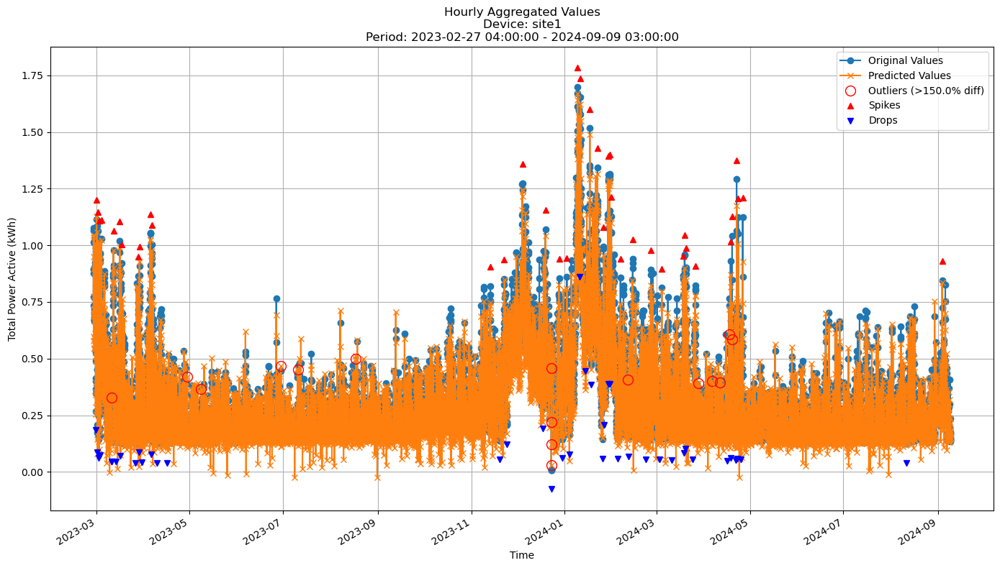


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0783
MAE: 0.0516
MAPE: 19.3902%

Directional Metrics:
Directional Accuracy: 50.4391%
First-Diff Correlation: 0.0885

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1471
  Recall: 0.1282
  F1 Score: 0.1370
Drops:
  Precision: 0.0882
  Recall: 0.0732
  F1 Score: 0.0800

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7059
  Recall: 0.6154
  F1 Score: 0.6575
Drops:
  Precision: 0.3235
  Recall: 0.2683
  F1 Score: 0.2933


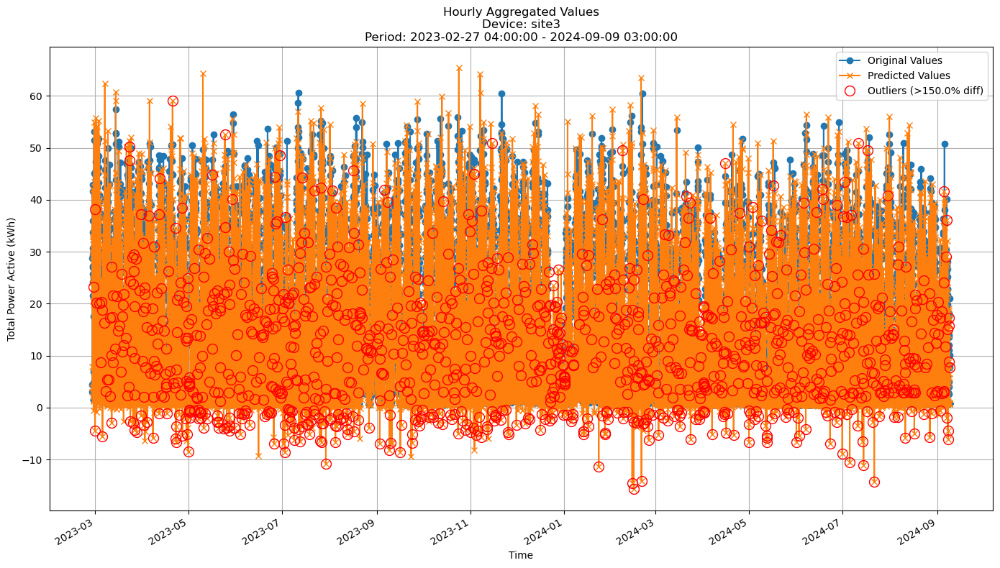


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 8.6938
MAE: 5.6835
MAPE: 69.0027%

Directional Metrics:
Directional Accuracy: 44.5974%
First-Diff Correlation: -0.0126

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


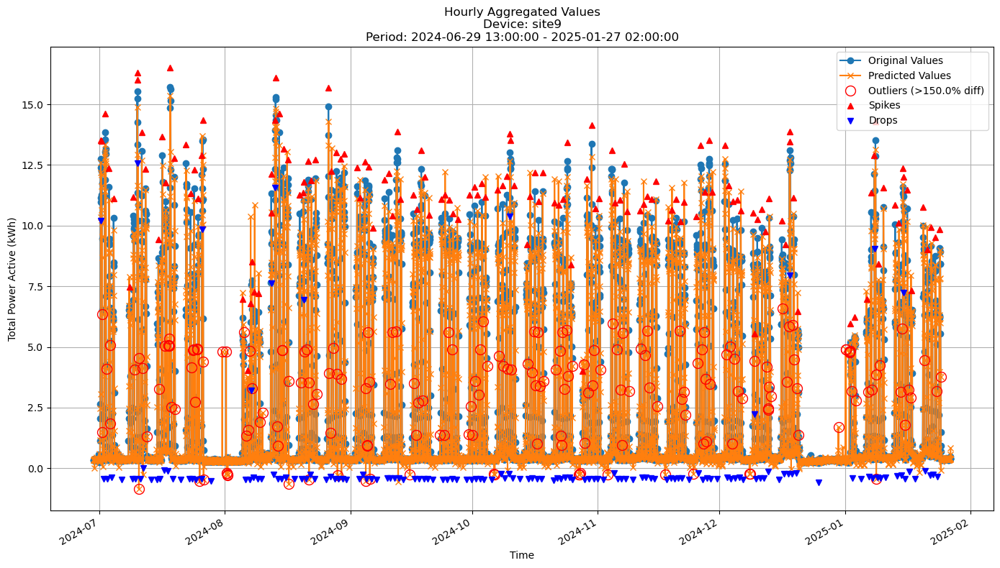


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.2602
MAE: 0.5575
MAPE: 32.5680%

Directional Metrics:
Directional Accuracy: 48.0701%
First-Diff Correlation: 0.2759

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0476
  Recall: 0.0676
  F1 Score: 0.0559
Drops:
  Precision: 0.0191
  Recall: 0.0270
  F1 Score: 0.0224

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.6524
  Recall: 0.9257
  F1 Score: 0.7654
Drops:
  Precision: 0.2249
  Recall: 0.3176
  F1 Score: 0.2633


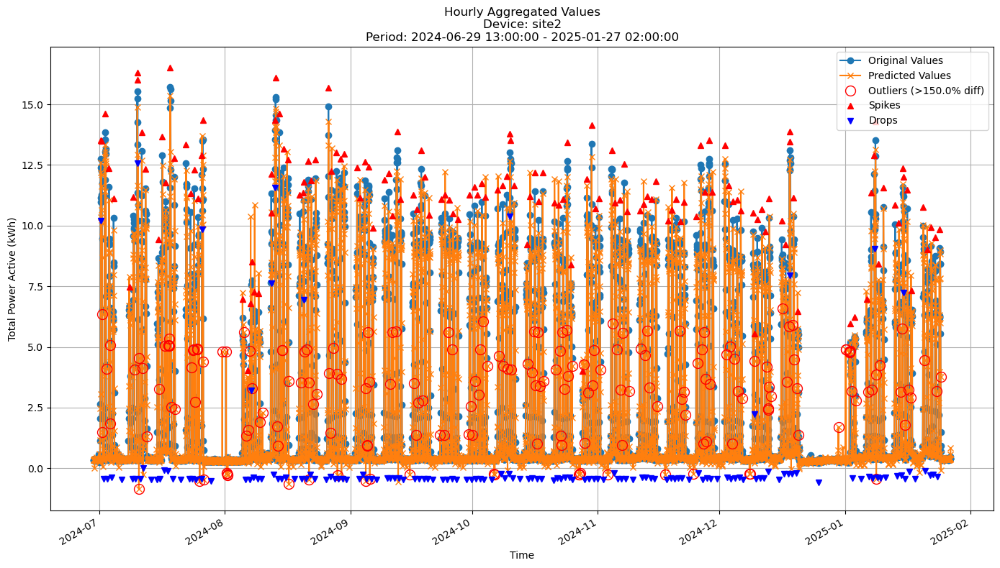


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.2602
MAE: 0.5575
MAPE: 32.5680%

Directional Metrics:
Directional Accuracy: 48.0701%
First-Diff Correlation: 0.2759

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0476
  Recall: 0.0676
  F1 Score: 0.0559
Drops:
  Precision: 0.0191
  Recall: 0.0270
  F1 Score: 0.0224

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.6524
  Recall: 0.9257
  F1 Score: 0.7654
Drops:
  Precision: 0.2249
  Recall: 0.3176
  F1 Score: 0.2633


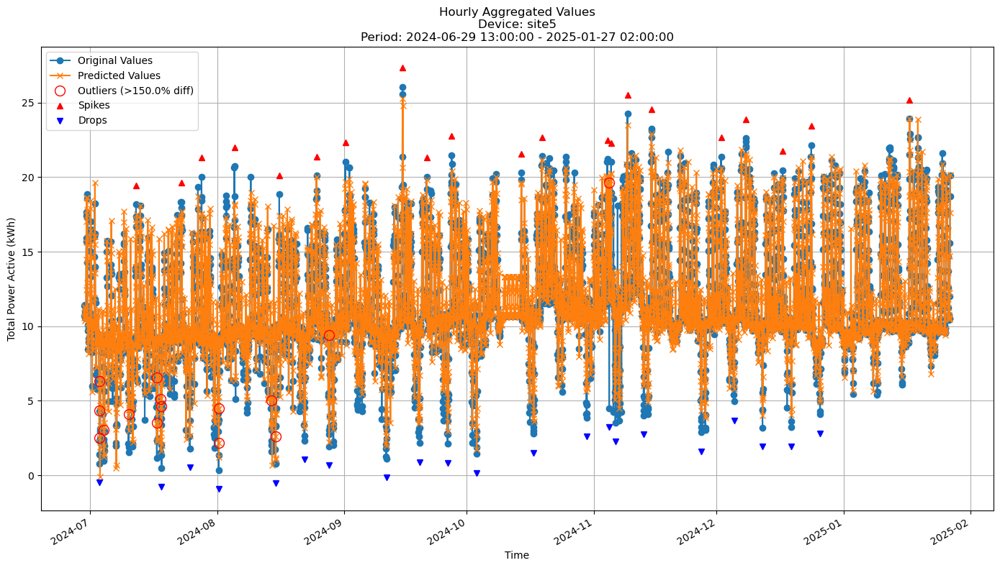


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.5367
MAE: 1.0194
MAPE: 11.2608%

Directional Metrics:
Directional Accuracy: 57.4833%
First-Diff Correlation: 0.2168

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1000
  Recall: 0.0476
  F1 Score: 0.0645
Drops:
  Precision: 0.1000
  Recall: 0.0476
  F1 Score: 0.0645

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.6000
  Recall: 0.2857
  F1 Score: 0.3871
Drops:
  Precision: 0.6000
  Recall: 0.2857
  F1 Score: 0.3871


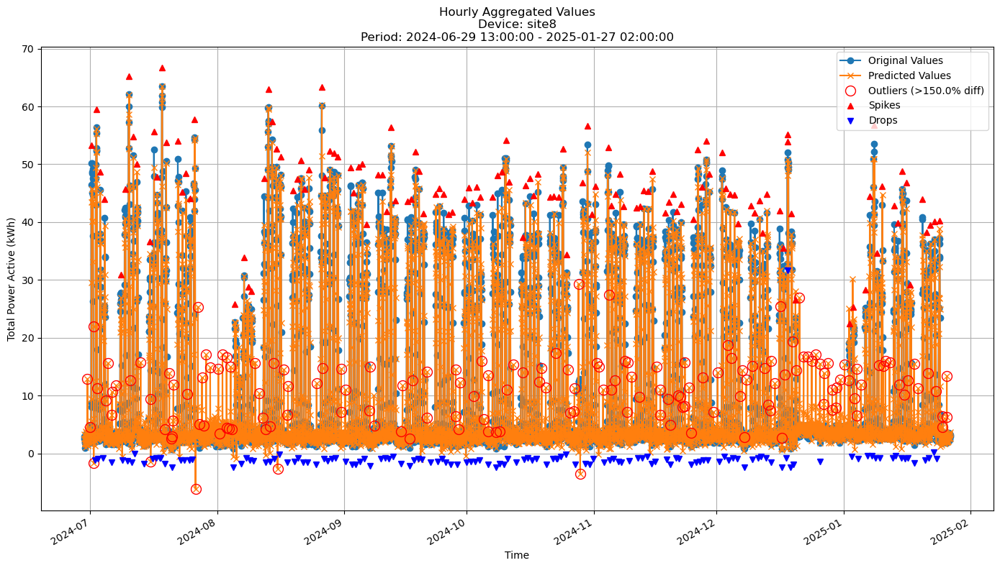


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 4.0790
MAE: 2.1912
MAPE: 34.1605%

Directional Metrics:
Directional Accuracy: 49.1532%
First-Diff Correlation: 0.4954

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0541
  Recall: 0.0593
  F1 Score: 0.0565
Drops:
  Precision: 0.0544
  Recall: 0.0588
  F1 Score: 0.0565

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8108
  Recall: 0.8889
  F1 Score: 0.8481
Drops:
  Precision: 0.4966
  Recall: 0.5368
  F1 Score: 0.5159


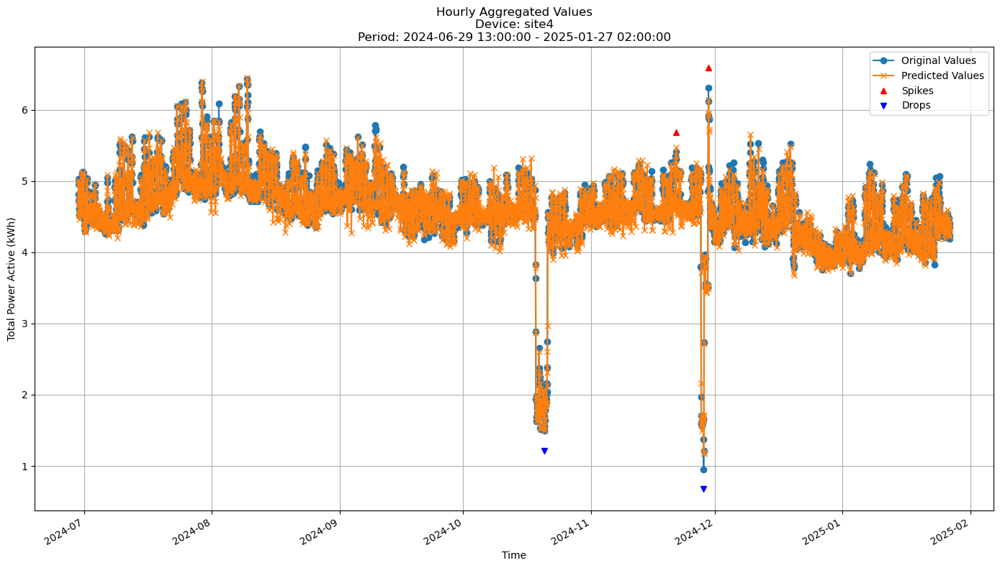


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1580
MAE: 0.1089
MAPE: 2.4197%

Directional Metrics:
Directional Accuracy: 46.8098%
First-Diff Correlation: 0.0624

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000


In [ ]:
for device_id in fodt_all_train_preds.keys():
    y_train = fodt_all_train_preds[device_id][-1]['y_true']
    y_pred_train = fodt_all_train_preds[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

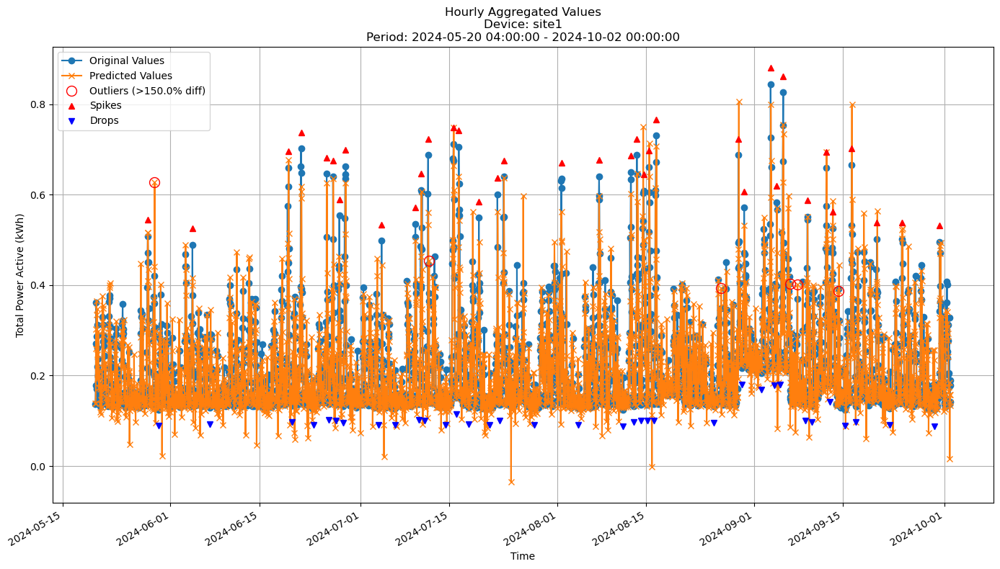


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0707
MAE: 0.0454
MAPE: 19.9525%

Directional Metrics:
Directional Accuracy: 46.9098%
First-Diff Correlation: 0.0375

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1515
  Recall: 0.1389
  F1 Score: 0.1449
Drops:
  Precision: 0.0312
  Recall: 0.0286
  F1 Score: 0.0299

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7576
  Recall: 0.6944
  F1 Score: 0.7246
Drops:
  Precision: 0.0938
  Recall: 0.0857
  F1 Score: 0.0896


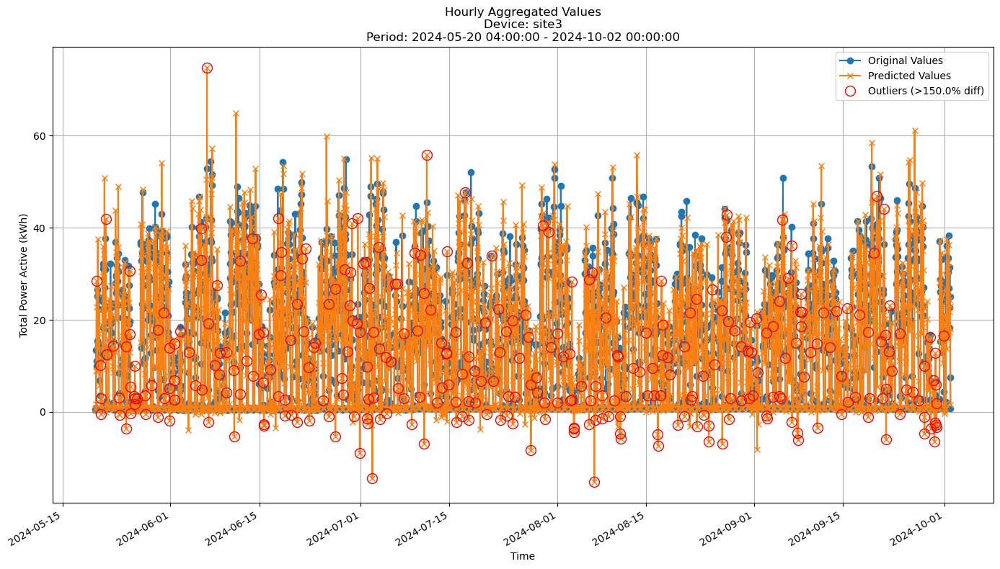


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 9.0333
MAE: 5.9349
MAPE: 69.8767%

Directional Metrics:
Directional Accuracy: 45.2101%
First-Diff Correlation: -0.0235

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


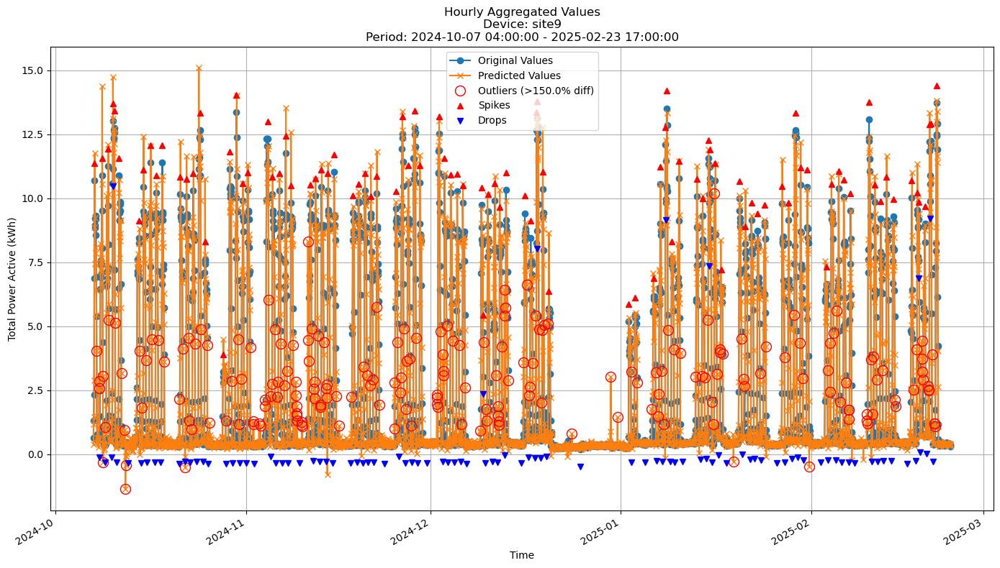


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.2852
MAE: 0.6169
MAPE: 37.7111%

Directional Metrics:
Directional Accuracy: 47.9701%
First-Diff Correlation: 0.2588

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0846
  Recall: 0.1111
  F1 Score: 0.0961
Drops:
  Precision: 0.0620
  Recall: 0.0816
  F1 Score: 0.0705

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7077
  Recall: 0.9293
  F1 Score: 0.8035
Drops:
  Precision: 0.3333
  Recall: 0.4388
  F1 Score: 0.3789


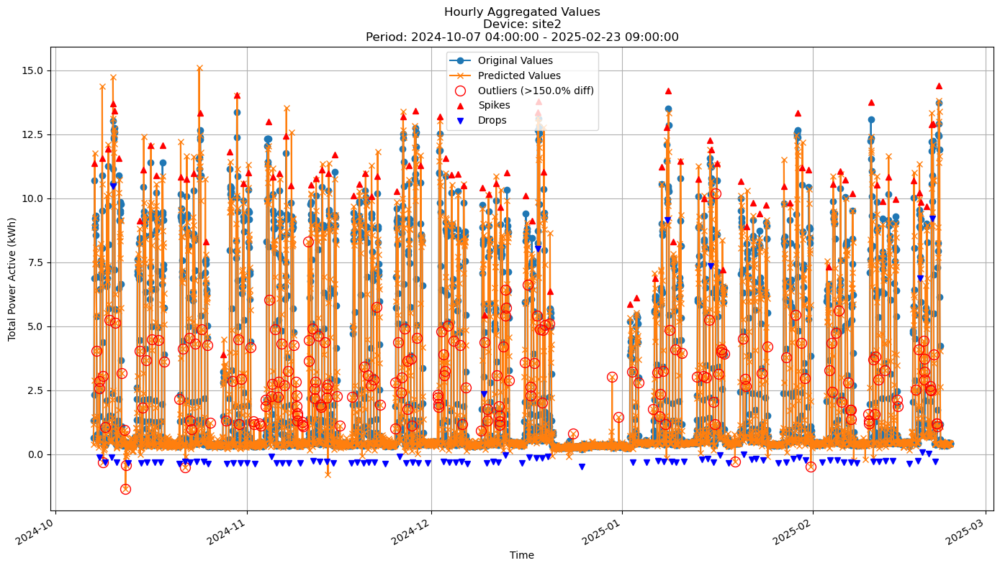


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.2868
MAE: 0.6183
MAPE: 37.7784%

Directional Metrics:
Directional Accuracy: 47.9653%
First-Diff Correlation: 0.2588

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0846
  Recall: 0.1111
  F1 Score: 0.0961
Drops:
  Precision: 0.0620
  Recall: 0.0816
  F1 Score: 0.0705

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7077
  Recall: 0.9293
  F1 Score: 0.8035
Drops:
  Precision: 0.3333
  Recall: 0.4388
  F1 Score: 0.3789


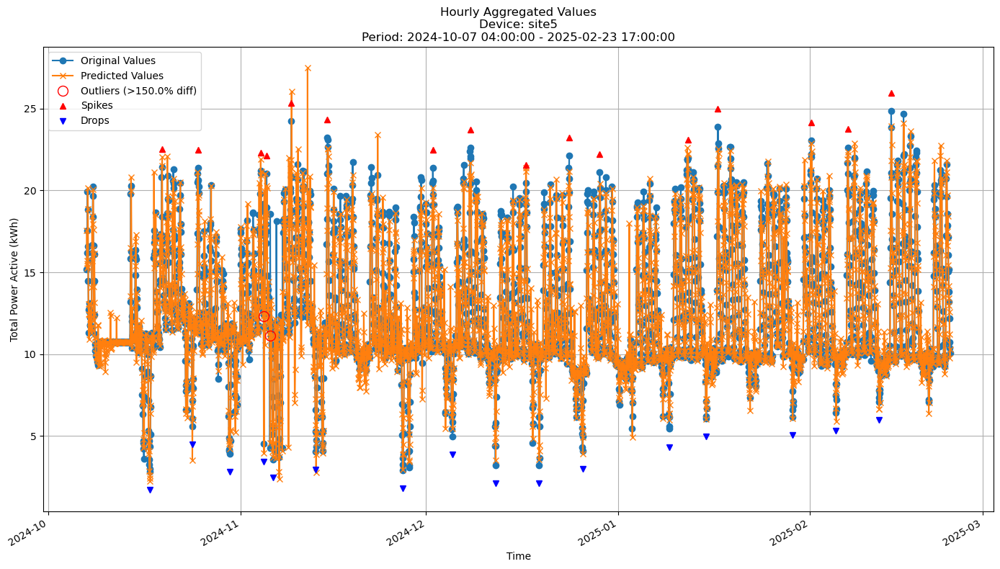


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.3327
MAE: 0.8214
MAPE: 6.7668%

Directional Metrics:
Directional Accuracy: 60.3284%
First-Diff Correlation: 0.3406

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.1000
  Recall: 0.0625
  F1 Score: 0.0769

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.5000
  Recall: 0.3125
  F1 Score: 0.3846
Drops:
  Precision: 0.8000
  Recall: 0.5000
  F1 Score: 0.6154


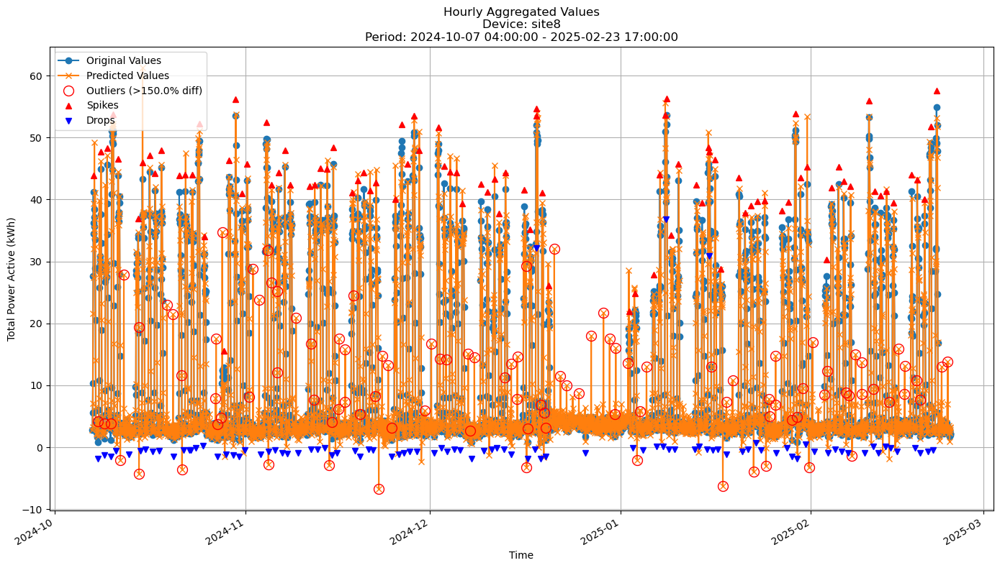


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 4.2784
MAE: 2.3223
MAPE: 35.4325%

Directional Metrics:
Directional Accuracy: 47.9403%
First-Diff Correlation: 0.4530

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0734
  Recall: 0.0842
  F1 Score: 0.0784
Drops:
  Precision: 0.0185
  Recall: 0.0211
  F1 Score: 0.0197

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7339
  Recall: 0.8421
  F1 Score: 0.7843
Drops:
  Precision: 0.3241
  Recall: 0.3684
  F1 Score: 0.3448


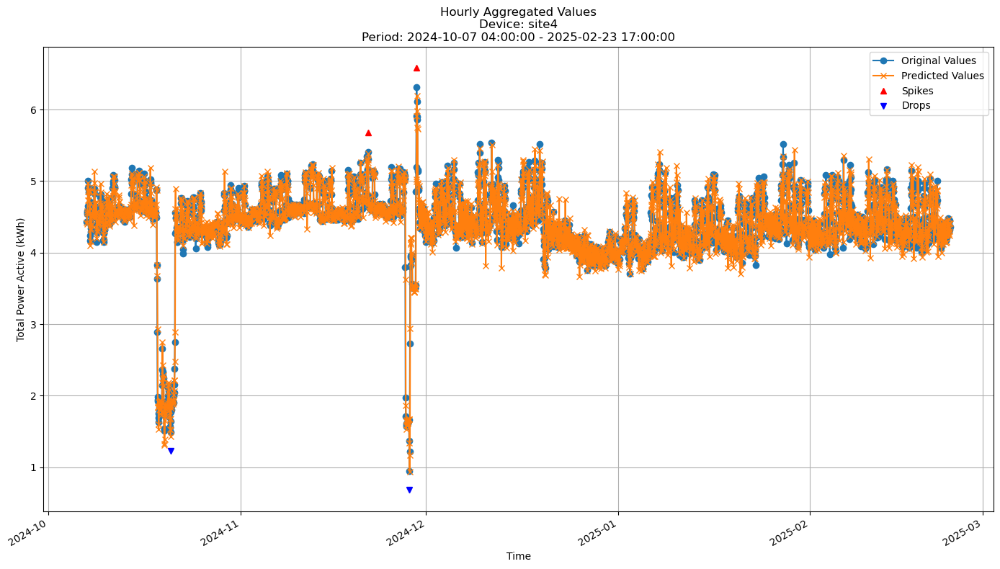


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1828
MAE: 0.1221
MAPE: 2.8526%

Directional Metrics:
Directional Accuracy: 42.2985%
First-Diff Correlation: -0.0736

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 0.5000
  Recall: 0.5000
  F1 Score: 0.5000


In [ ]:
join_periods = [-5, -4, -3, -2, -1]
# Device iteration
for device_id in fodt_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, fodt_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, fodt_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### xFastODT

In [ ]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

xfodt = xfastodt.xFastODT

xfodt_params = {'depth': 50, 
               'grace_period': 24, 
               'grace_period_depth': 0, 
               'split_confidence': 0.005, 
               'max_feature': 0.3, 
               'tie_threshold': 0.05, 
               'bin_type': 'mean', 
               'split_criterion': 'vr_rel'}

In [ ]:
xfodt_all_train_preds, xfodt_all_valid_preds, \
xfodt_all_train_metrics, xfodt_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=xfodt, 
    model_params=xfodt_params, 
    train=train, 
    valid=valid, 
    use_residuals=USE_RESIDUAL,
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

#### Results

In [ ]:
print("\n\nTrain period metrics:")
xfodt_all_time_train_metrics = all_time_aggregation_metrics(xfodt_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
xfodt_all_time_valid_metrics = all_time_aggregation_metrics(xfodt_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)

#### Training plots


In [ ]:
for device_id in xfodt_all_train_preds.keys():
    y_train = xfodt_all_train_preds[device_id][-1]['y_true']
    y_pred_train = xfodt_all_train_preds[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id,
                            spike_prominence=SPIKE_PROMINENCE, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

In [ ]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in xfodt_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, xfodt_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, xfodt_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (FastODT)

In [40]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

arf = ARFRegressorFODT
arf_params = {
    'n_models': 60, 
     'max_feature': 0.5, 
     'max_depth': 30, 
     'aggregation_method': 'mean', 
     'disable_weighted_vote': True, 
     'eagerness': 0, 
     'tau': 0.01, 
     'delta': 0.1, 
     'grace_period': 0, 
     'grace_period_depth': 0, 
     'bin_type': 'mean', 
     'split_criterion': 'vr_rel'
}

In [41]:
arf_all_train_preds, arf_all_valid_preds, \
arf_all_train_metrics, arf_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=arf,
    model_params=arf_params,
    train=train,
    valid=valid,
    use_residuals=USE_RESIDUAL,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE,
    start_split=0,
    #end_split=4,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/25 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/2 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 04:00:00+01:00 to 2023-03-27 03:00:00+02:00
Model's memory usage: 146.553177 MB
Metrics for Device: site1 | Period: 2023-03-27 04:00:00+02:00 - 2023-04-24 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0688
	MAE: 0.0472
	MAPE: 17.3091%

Directional Metrics:
	Directional Accuracy: 55.2906%
	First-Diff Correlation: 0.0487

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0400
		Recall: 0.0435
		F1: 0.0417
	Drops:
		Precision: 0.0833
		Recall: 0.0909
		F1: 0.0870

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.7200
		Recall: 0.7826
		F1: 0.7500
	Drops:
		Precision: 0.5000
		Recall: 0.5455
		F1: 0.5217
--------------------------------------------------
D

Processing devices in split 1:   0%|          | 0/2 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 04:00:00+01:00 to 2023-04-24 03:00:00+02:00
Model's memory usage: 182.270088 MB
Metrics for Device: site1 | Period: 2023-04-24 04:00:00+02:00 - 2023-05-22 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0461
	MAE: 0.0308
	MAPE: 15.0216%

Directional Metrics:
	Directional Accuracy: 54.8435%
	First-Diff Correlation: 0.1657

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0882
		Recall: 0.0698
		F1: 0.0779
	Drops:
		Precision: 0.1818
		Recall: 0.1304
		F1: 0.1519

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.8529
		Recall: 0.6744
		F1: 0.7532
	Drops:
		Precision: 0.6667
		Recall: 0.4783
		F1: 0.5570
--------------------------------------------------
D

Processing devices in split 2:   0%|          | 0/2 [00:00<?, ?it/s]

... (41 outputs left out)

Processing devices in split 23:   0%|          | 0/7 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 13:00:00+02:00 to 2024-12-30 02:00:00+01:00
Model's memory usage: 420.101624 MB
Metrics for Device: site9 | Period: 2024-12-30 03:00:00+01:00 - 2025-01-27 02:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.7864
	MAE: 0.3914
	MAPE: 29.4218%

Directional Metrics:
	Directional Accuracy: 53.5022%
	First-Diff Correlation: 0.4960

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0294
		Recall: 0.0333
		F1: 0.0312
	Drops:
		Precision: 0.0606
		Recall: 0.0690
		F1: 0.0645

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.5000
		Recall: 0.5667
		F1: 0.5312
	Drops:
		Precision: 0.2121
		Recall: 0.2414
		F1: 0.2258
--------------------------------------------------
D

Processing devices in split 24:   0%|          | 0/7 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 13:00:00+02:00 to 2025-01-27 02:00:00+01:00
Model's memory usage: 412.078827 MB
Metrics for Device: site9 | Period: 2025-01-27 03:00:00+01:00 - 2025-02-23 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.9147
	MAE: 0.4690
	MAPE: 25.7230%

Directional Metrics:
	Directional Accuracy: 57.8550%
	First-Diff Correlation: 0.4908

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1071
		Recall: 0.1071
		F1: 0.1071
	Drops:
		Precision: 0.1111
		Recall: 0.1111
		F1: 0.1111

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.7500
		Recall: 0.7500
		F1: 0.7500
	Drops:
		Precision: 0.4074
		Recall: 0.4074
		F1: 0.4074
--------------------------------------------------
D

#### Results

In [ ]:
print("\n\nTrain period metrics:")
arf_all_time_train_metrics = all_time_aggregation_metrics(arf_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
arf_all_time_valid_metrics = all_time_aggregation_metrics(arf_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: site1
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0550 ± 0.0041
	MAE: 0.0371 ± 0.0030
	MAPE: 14.1507% ± 0.9509%

	Directional Metrics:
		Directional Accuracy: 57.5247% ± 3.8623%
		First-Diff Correlation: 0.2202 ± 0.0743

	Immediate Detection (delta=0):
		Spike Precision: 0.1283 ± 0.0501
		Spike Recall: 0.1175 ± 0.0484
		Spike F1: 0.1222 ± 0.0482
		Drop Precision: 0.1483 ± 0.0271
		Drop Recall: 0.1311 ± 0.0226
		Drop F1: 0.1386 ± 0.0223

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.8205 ± 0.0614
		Spike Recall: 0.7552 ± 0.0492
		Spike F1: 0.7835 ± 0.0254
		Drop Precision: 0.6014 ± 0.0699
		Drop Recall: 0.5366 ± 0.0875
		Drop F1: 0.5650 ± 0.0738
Daily Metrics:
	RMSE: 0.2201 ± 0.0777
	MAE: 0.1624 ± 0.0574
	MAPE: 2.3997% ± 0.5458%

	Directional Metrics:
		Directional Accuracy: 97.0407% ± 1.2100%
		First-Diff Correlation: 0.9953 ± 0.0016

	Immediate Detection (delta=0):
		Spik

#### Training plots

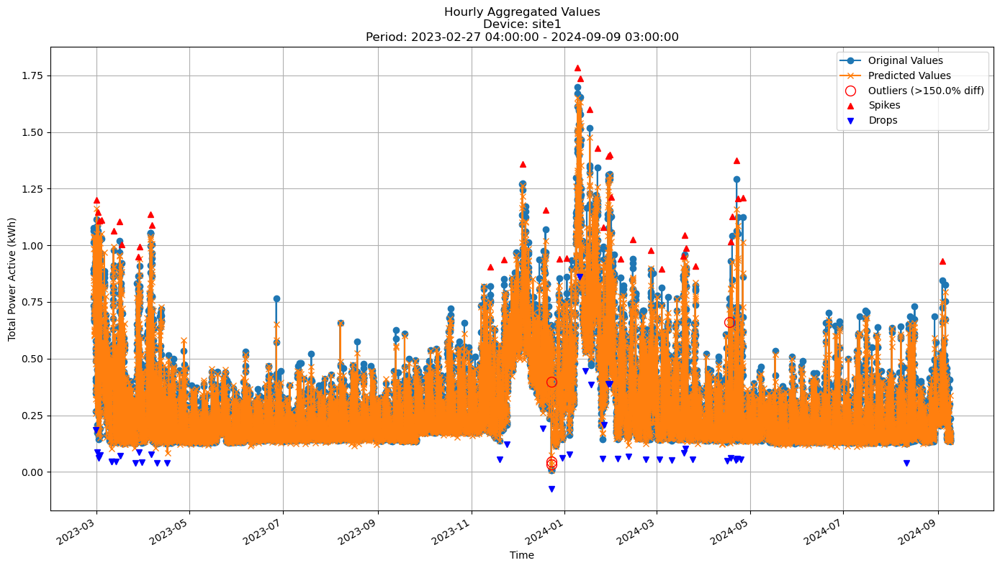


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0572
MAE: 0.0384
MAPE: 14.6117%

Directional Metrics:
Directional Accuracy: 54.4054%
First-Diff Correlation: 0.1790

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1471
  Recall: 0.1282
  F1 Score: 0.1370
Drops:
  Precision: 0.0882
  Recall: 0.0732
  F1 Score: 0.0800

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7941
  Recall: 0.6923
  F1 Score: 0.7397
Drops:
  Precision: 0.6471
  Recall: 0.5366
  F1 Score: 0.5867


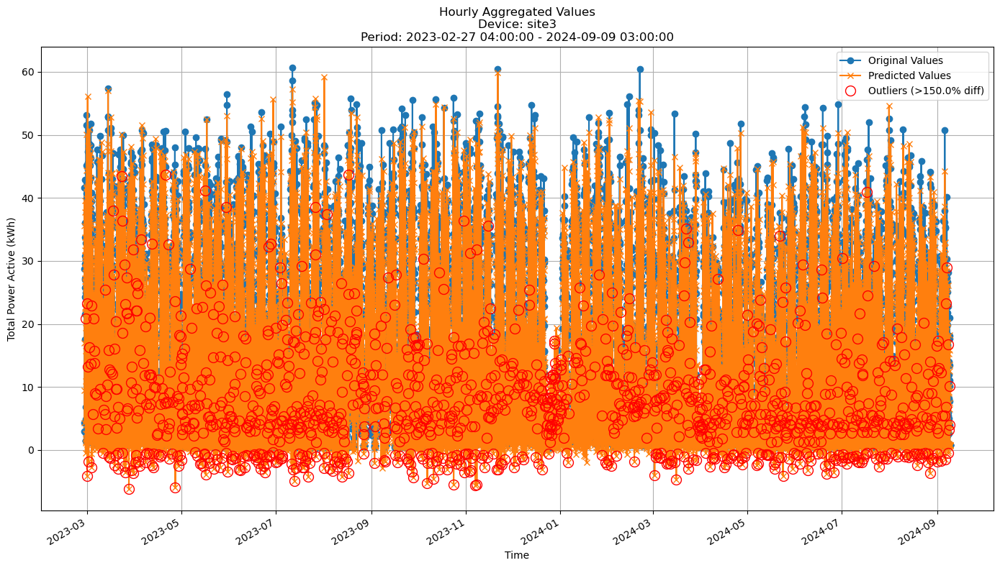


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 6.8714
MAE: 4.5860
MAPE: 63.1089%

Directional Metrics:
Directional Accuracy: 48.5042%
First-Diff Correlation: 0.1165

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


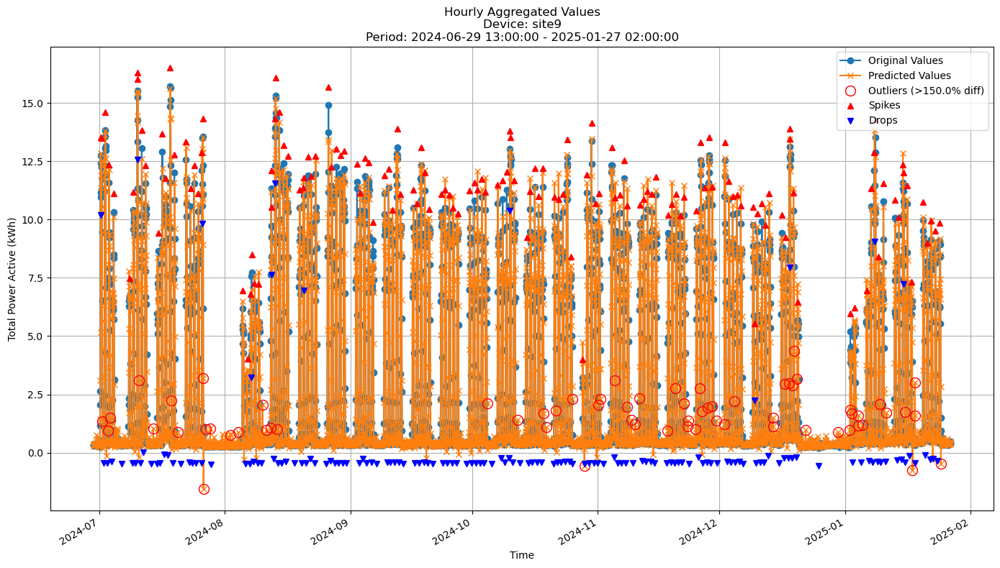


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.7768
MAE: 0.3670
MAPE: 20.8905%

Directional Metrics:
Directional Accuracy: 53.8795%
First-Diff Correlation: 0.6037

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1042
  Recall: 0.1014
  F1 Score: 0.1027
Drops:
  Precision: 0.0350
  Recall: 0.0338
  F1 Score: 0.0344

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8750
  Recall: 0.8514
  F1 Score: 0.8630
Drops:
  Precision: 0.2308
  Recall: 0.2230
  F1 Score: 0.2268


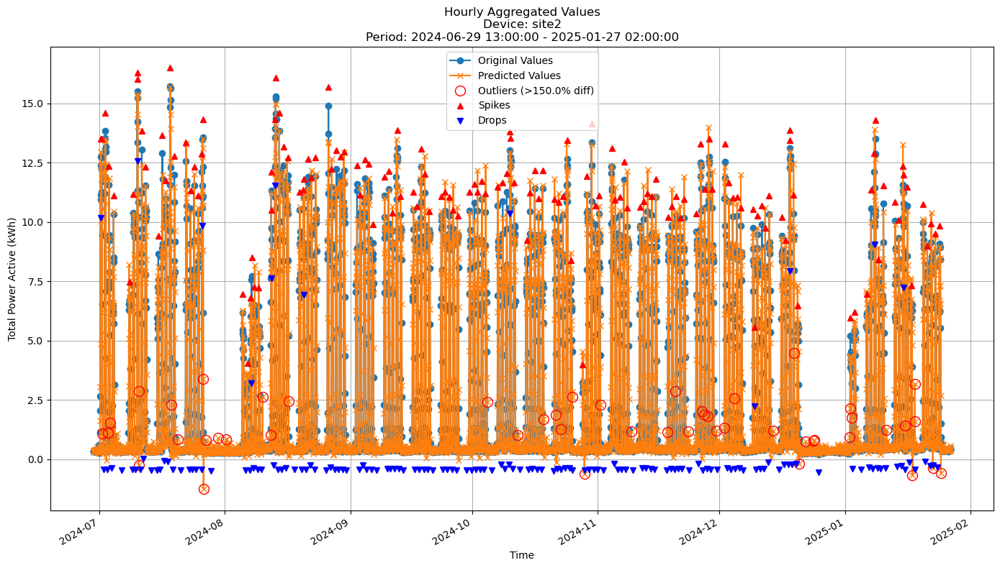


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.7636
MAE: 0.3592
MAPE: 19.8406%

Directional Metrics:
Directional Accuracy: 54.3915%
First-Diff Correlation: 0.6156

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1267
  Recall: 0.1284
  F1 Score: 0.1275
Drops:
  Precision: 0.0268
  Recall: 0.0270
  F1 Score: 0.0269

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8333
  Recall: 0.8446
  F1 Score: 0.8389
Drops:
  Precision: 0.2483
  Recall: 0.2500
  F1 Score: 0.2492


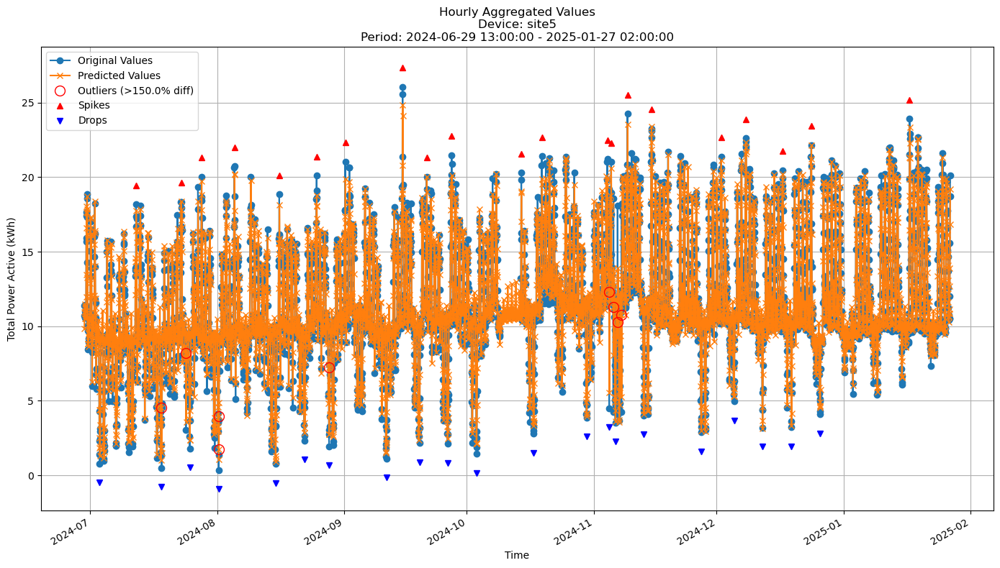


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.1337
MAE: 0.7366
MAPE: 7.6673%

Directional Metrics:
Directional Accuracy: 61.1461%
First-Diff Correlation: 0.2920

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.1000
  Recall: 0.0952
  F1 Score: 0.0976

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7368
  Recall: 0.6667
  F1 Score: 0.7000
Drops:
  Precision: 0.5500
  Recall: 0.5238
  F1 Score: 0.5366


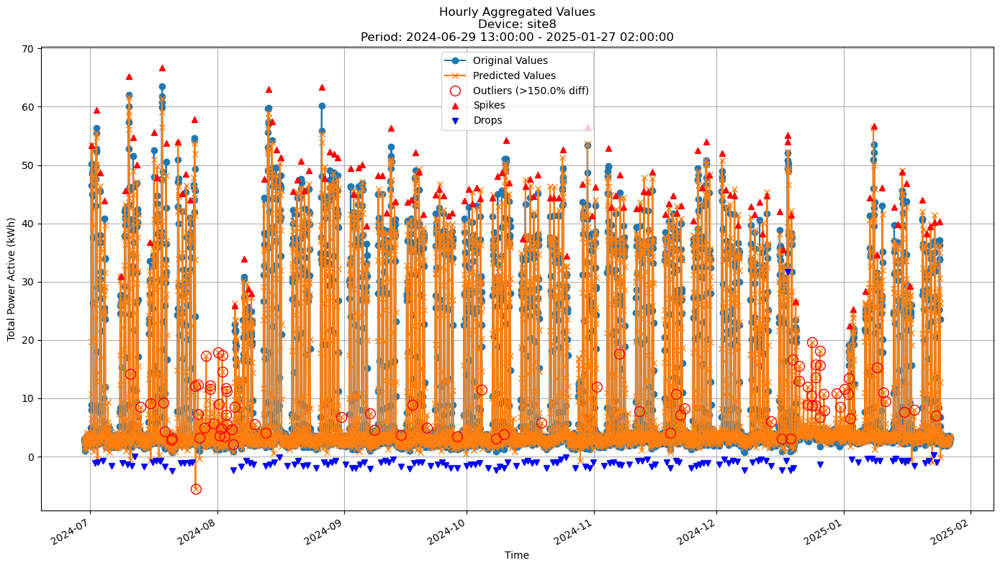


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 3.2394
MAE: 1.7550
MAPE: 25.8285%

Directional Metrics:
Directional Accuracy: 53.2296%
First-Diff Correlation: 0.5779

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0764
  Recall: 0.0815
  F1 Score: 0.0789
Drops:
  Precision: 0.0490
  Recall: 0.0515
  F1 Score: 0.0502

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7986
  Recall: 0.8519
  F1 Score: 0.8244
Drops:
  Precision: 0.4476
  Recall: 0.4706
  F1 Score: 0.4588


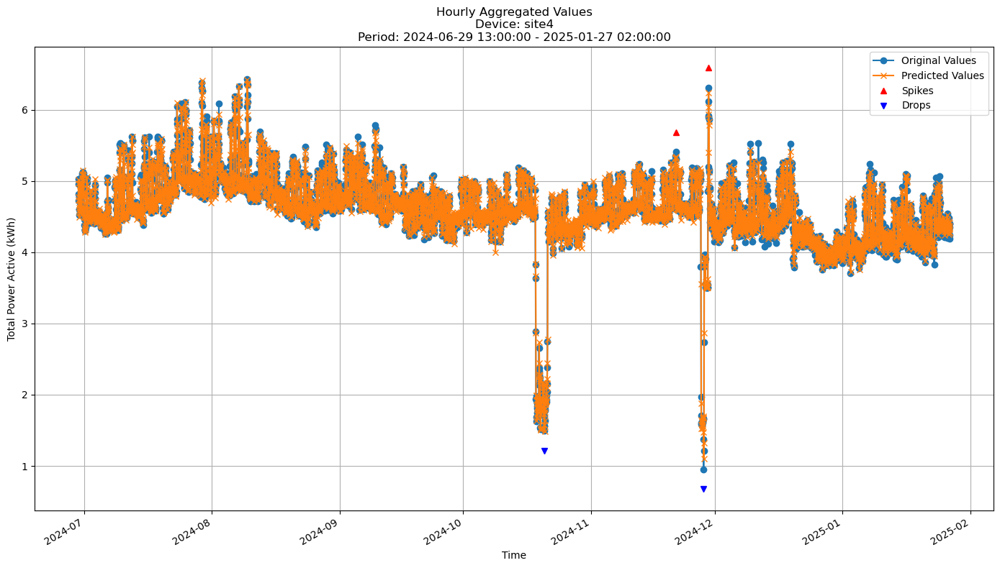


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1186
MAE: 0.0769
MAPE: 1.7350%

Directional Metrics:
Directional Accuracy: 51.3391%
First-Diff Correlation: 0.2394

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000


In [ ]:
for device_id in arf_all_train_preds.keys():
    y_train = arf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

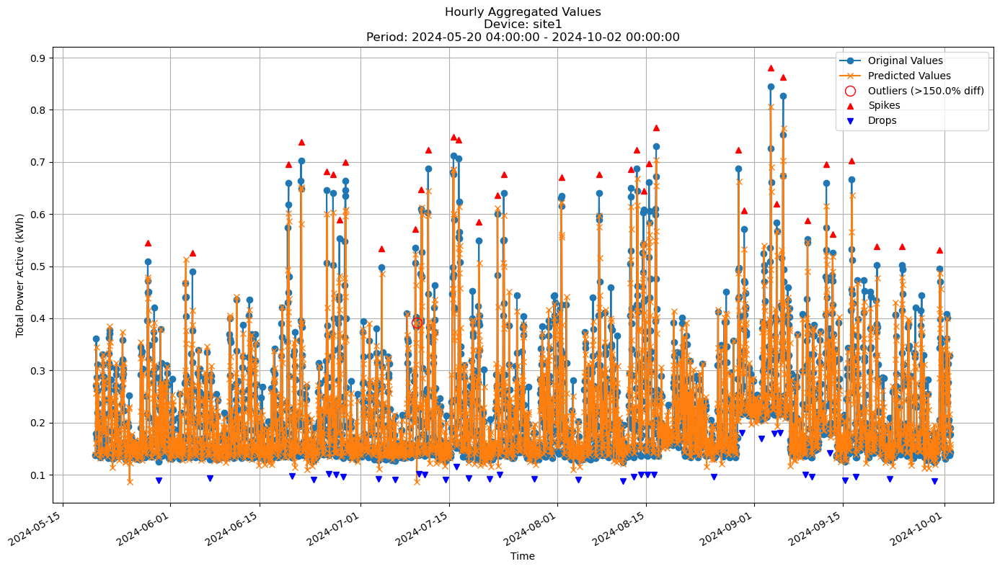


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0593
MAE: 0.0376
MAPE: 16.3761%

Directional Metrics:
Directional Accuracy: 48.4240%
First-Diff Correlation: 0.0509

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1923
  Recall: 0.1389
  F1 Score: 0.1613
Drops:
  Precision: 0.0800
  Recall: 0.0571
  F1 Score: 0.0667

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.9615
  Recall: 0.6944
  F1 Score: 0.8065
Drops:
  Precision: 0.3200
  Recall: 0.2286
  F1 Score: 0.2667


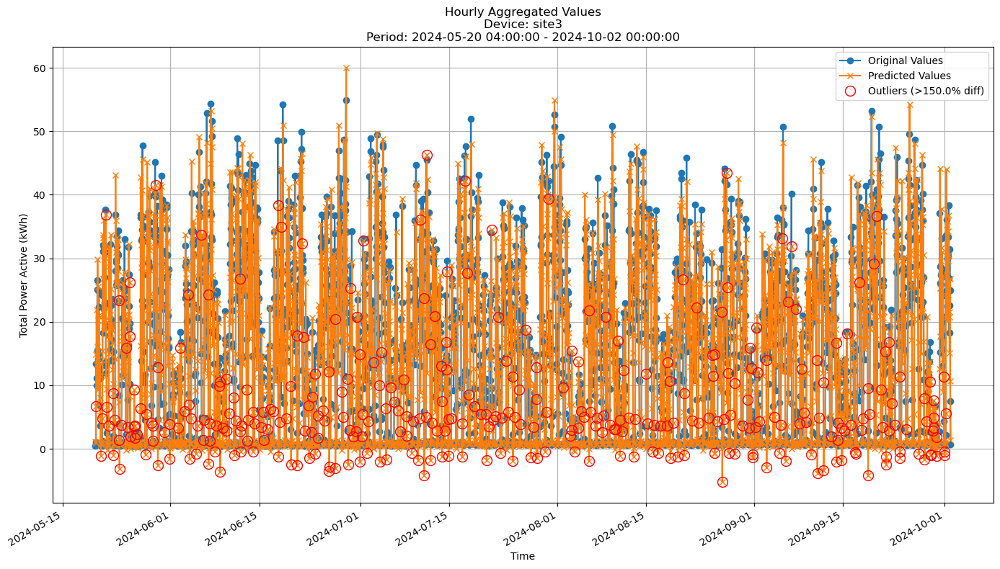


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 7.3908
MAE: 4.9049
MAPE: 65.0668%

Directional Metrics:
Directional Accuracy: 45.6428%
First-Diff Correlation: 0.0224

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


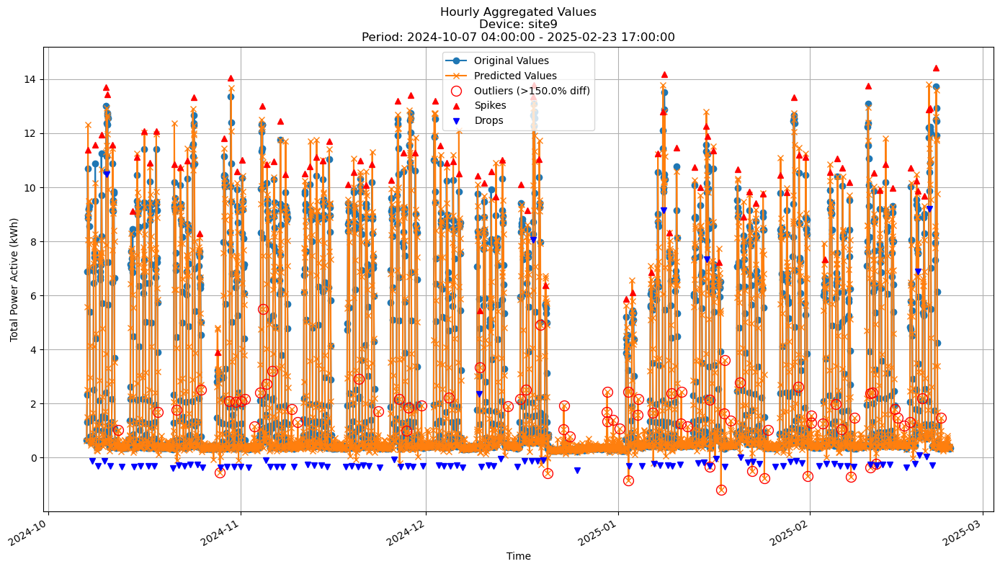


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.8455
MAE: 0.4243
MAPE: 25.9247%

Directional Metrics:
Directional Accuracy: 52.4478%
First-Diff Correlation: 0.5076

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0816
  Recall: 0.0808
  F1 Score: 0.0812
Drops:
  Precision: 0.0722
  Recall: 0.0714
  F1 Score: 0.0718

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8878
  Recall: 0.8788
  F1 Score: 0.8832
Drops:
  Precision: 0.2577
  Recall: 0.2551
  F1 Score: 0.2564


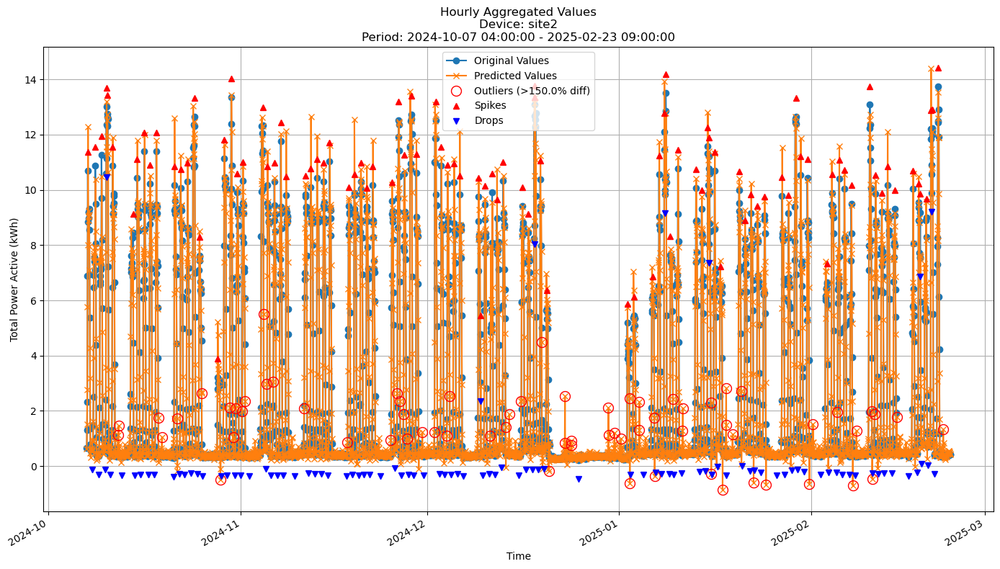


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.8383
MAE: 0.4188
MAPE: 24.5366%

Directional Metrics:
Directional Accuracy: 52.2442%
First-Diff Correlation: 0.5172

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0900
  Recall: 0.0909
  F1 Score: 0.0905
Drops:
  Precision: 0.0808
  Recall: 0.0816
  F1 Score: 0.0812

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8600
  Recall: 0.8687
  F1 Score: 0.8643
Drops:
  Precision: 0.2626
  Recall: 0.2653
  F1 Score: 0.2640


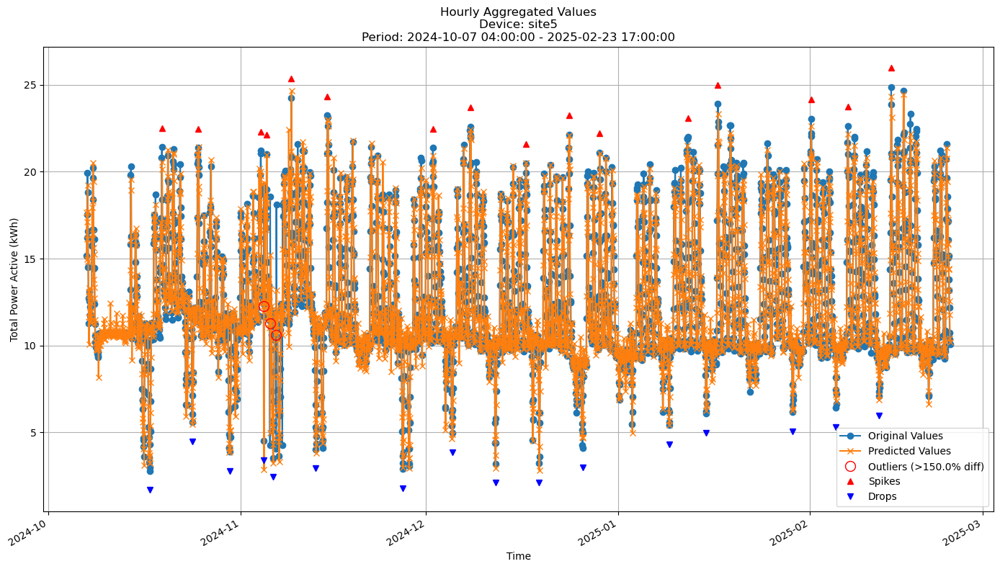


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.1735
MAE: 0.7451
MAPE: 6.0288%

Directional Metrics:
Directional Accuracy: 60.9552%
First-Diff Correlation: 0.3120

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0714
  Recall: 0.0625
  F1 Score: 0.0667

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7143
  Recall: 0.6250
  F1 Score: 0.6667
Drops:
  Precision: 0.7143
  Recall: 0.6250
  F1 Score: 0.6667


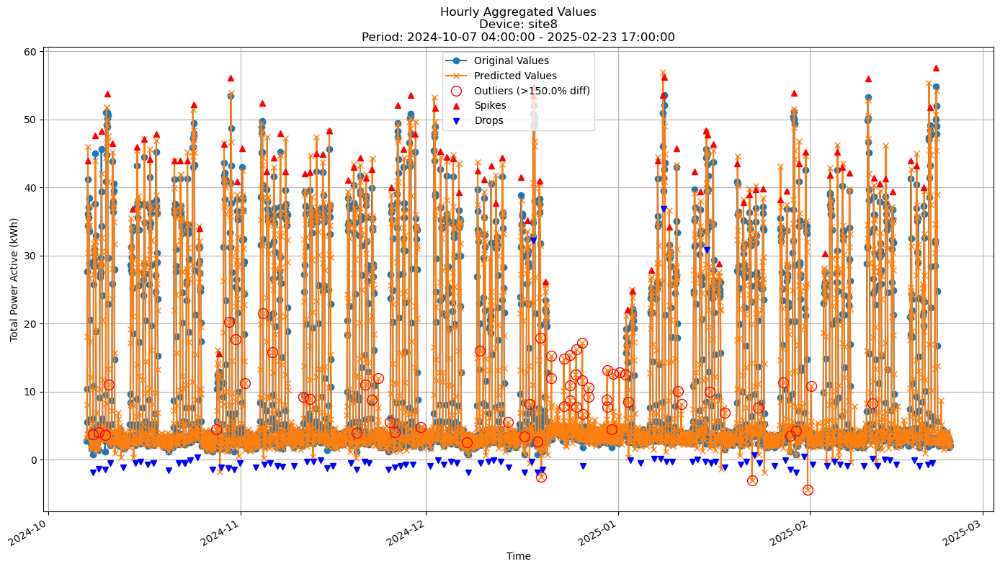


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 3.6280
MAE: 2.0213
MAPE: 29.0997%

Directional Metrics:
Directional Accuracy: 49.1343%
First-Diff Correlation: 0.4465

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0957
  Recall: 0.0947
  F1 Score: 0.0952
Drops:
  Precision: 0.0323
  Recall: 0.0316
  F1 Score: 0.0319

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8830
  Recall: 0.8737
  F1 Score: 0.8783
Drops:
  Precision: 0.3656
  Recall: 0.3579
  F1 Score: 0.3617


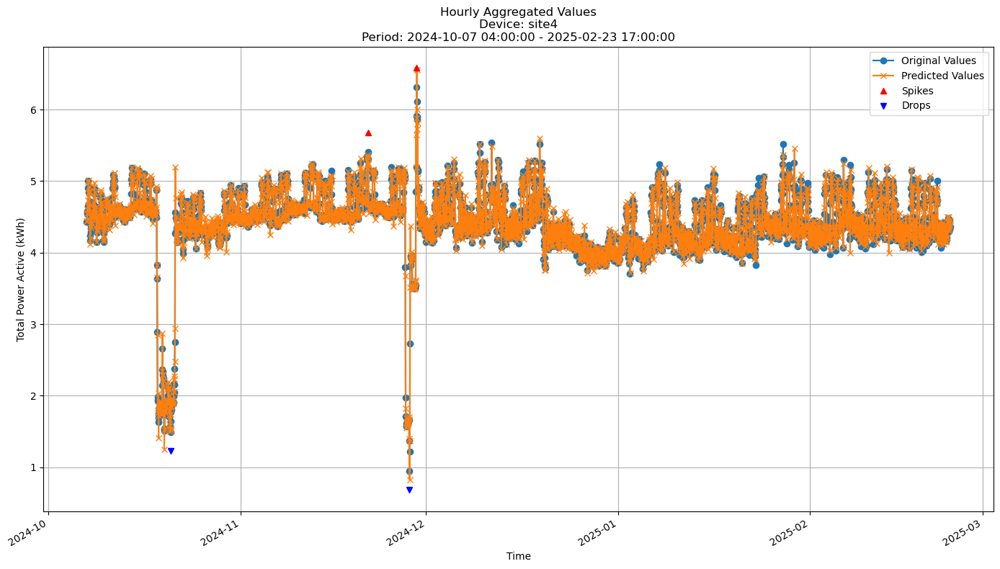


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1692
MAE: 0.1125
MAPE: 2.6287%

Directional Metrics:
Directional Accuracy: 40.4179%
First-Diff Correlation: -0.0932

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.5000
  Recall: 0.5000
  F1 Score: 0.5000
Drops:
  Precision: 0.5000
  Recall: 0.5000
  F1 Score: 0.5000


In [ ]:
join_periods = [-5, -4, -3, -2, -1]
# Device iteration
for device_id in arf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

### iNcubation Boost

In [45]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario:


incb = IncubationBoost
incb_params = {
    'length': 20, 
    'learning_rate': 0.5, 
    'depth': 5, 
    'grace_period': 48, 
    'grace_period_depth': -1, 
    'split_confidence': 0.5, 
    'max_feature': 1.0, 
    'tie_threshold': 0.05, 
    'bin_type': 'adaptive', 
    'max_bins': 4, 
    'split_criterion': 'vr_rel', 
    'verbose': False
}


In [46]:
incb_all_train_preds, incb_all_valid_preds, \
incb_all_train_metrics, incb_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=incb, 
    model_params=incb_params,
    train=train, 
    valid=valid, 
    use_residuals=USE_RESIDUAL,
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    # end_split=1,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/25 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/2 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 04:00:00+01:00 to 2023-03-27 03:00:00+02:00
Model's memory usage: 0.184753 MB
Metrics for Device: site1 | Period: 2023-03-27 04:00:00+02:00 - 2023-04-24 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0771
	MAE: 0.0520
	MAPE: 18.8923%

Directional Metrics:
	Directional Accuracy: 49.6274%
	First-Diff Correlation: -0.0125

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.9565
		Recall: 0.9565
		F1: 0.9565
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Da

Processing devices in split 1:   0%|          | 0/2 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 04:00:00+01:00 to 2023-04-24 03:00:00+02:00
Model's memory usage: 0.157074 MB
Metrics for Device: site1 | Period: 2023-04-24 04:00:00+02:00 - 2023-05-22 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0605
	MAE: 0.0385
	MAPE: 18.1546%

Directional Metrics:
	Directional Accuracy: 41.7288%
	First-Diff Correlation: -0.2243

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Da

Processing devices in split 2:   0%|          | 0/2 [00:00<?, ?it/s]

... (41 outputs left out)

Processing devices in split 23:   0%|          | 0/7 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 13:00:00+02:00 to 2024-12-30 02:00:00+01:00
Model's memory usage: 0.448074 MB
Metrics for Device: site9 | Period: 2024-12-30 03:00:00+01:00 - 2025-01-27 02:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.0917
	MAE: 0.5495
	MAPE: 50.9031%

Directional Metrics:
	Directional Accuracy: 51.1177%
	First-Diff Correlation: 0.2643

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0556
		Recall: 0.0345
		F1: 0.0426

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.8947
		Recall: 0.5667
		F1: 0.6939
	Drops:
		Precision: 0.5556
		Recall: 0.3448
		F1: 0.4255
--------------------------------------------------
Dai

Processing devices in split 24:   0%|          | 0/7 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 13:00:00+02:00 to 2025-01-27 02:00:00+01:00
Model's memory usage: 0.455688 MB
Metrics for Device: site9 | Period: 2025-01-27 03:00:00+01:00 - 2025-02-23 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.2876
	MAE: 0.6744
	MAPE: 47.5272%

Directional Metrics:
	Directional Accuracy: 53.9275%
	First-Diff Correlation: 0.2811

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1429
		Recall: 0.1071
		F1: 0.1224
	Drops:
		Precision: 0.2000
		Recall: 0.1481
		F1: 0.1702

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.9048
		Recall: 0.6786
		F1: 0.7755
	Drops:
		Precision: 0.4500
		Recall: 0.3333
		F1: 0.3830
--------------------------------------------------
Dai

#### Results

In [ ]:
print("\n\nTrain period metrics:")
incb_all_time_train_metrics = all_time_aggregation_metrics(incb_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
incb_all_time_valid_metrics = all_time_aggregation_metrics(incb_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: site1
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0734 ± 0.0041
	MAE: 0.0483 ± 0.0038
	MAPE: 17.9776% ± 0.5907%

	Directional Metrics:
		Directional Accuracy: 46.8528% ± 2.6462%
		First-Diff Correlation: -0.0630 ± 0.0500

	Immediate Detection (delta=0):
		Spike Precision: 0.0170 ± 0.0274
		Spike Recall: 0.0175 ± 0.0281
		Spike F1: 0.0173 ± 0.0277
		Drop Precision: 0.0052 ± 0.0069
		Drop Recall: 0.0054 ± 0.0078
		Drop F1: 0.0053 ± 0.0073

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.9334 ± 0.0771
		Spike Recall: 0.9425 ± 0.0600
		Spike F1: 0.9376 ± 0.0681
		Drop Precision: 0.9568 ± 0.0851
		Drop Recall: 0.9651 ± 0.0658
		Drop F1: 0.9607 ± 0.0759
Daily Metrics:
	RMSE: 0.1604 ± 0.0428
	MAE: 0.0842 ± 0.0249
	MAPE: 0.9510% ± 0.1923%

	Directional Metrics:
		Directional Accuracy: 97.6070% ± 0.6925%
		First-Diff Correlation: 0.9964 ± 0.0003

	Immediate Detection (delta=0):
		Spi

#### Train plots

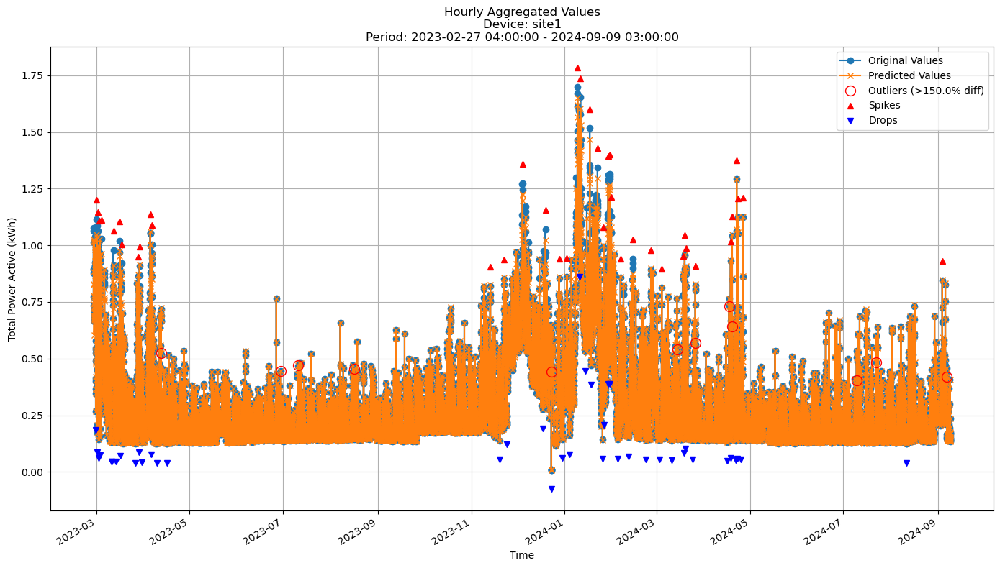


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0736
MAE: 0.0478
MAPE: 17.6012%

Directional Metrics:
Directional Accuracy: 45.2746%
First-Diff Correlation: -0.0637

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0270
  Recall: 0.0256
  F1 Score: 0.0263
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.8919
  Recall: 0.8462
  F1 Score: 0.8684
Drops:
  Precision: 0.9487
  Recall: 0.9024
  F1 Score: 0.9250


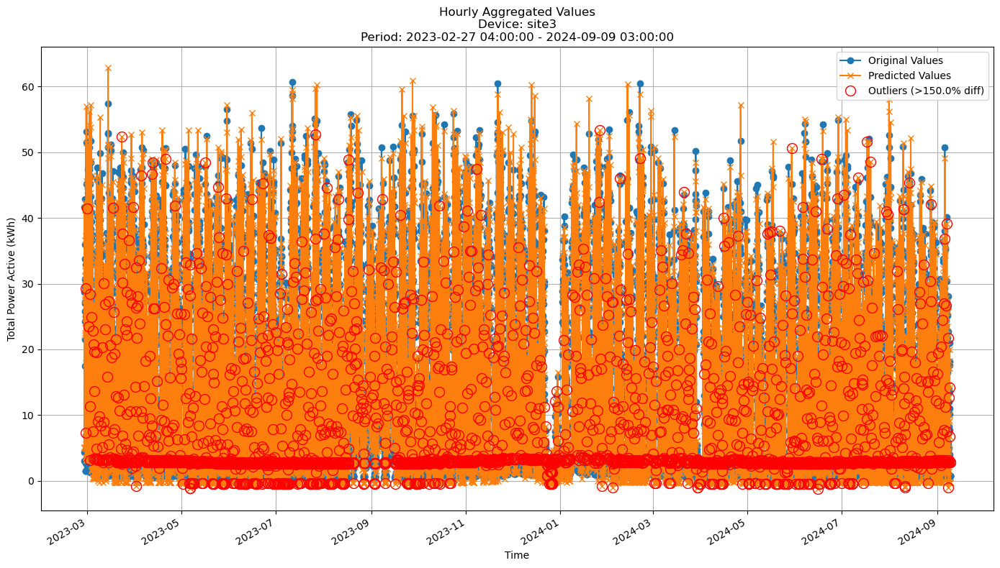


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 9.2054
MAE: 6.2419
MAPE: 116.6876%

Directional Metrics:
Directional Accuracy: 40.2515%
First-Diff Correlation: -0.1325

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


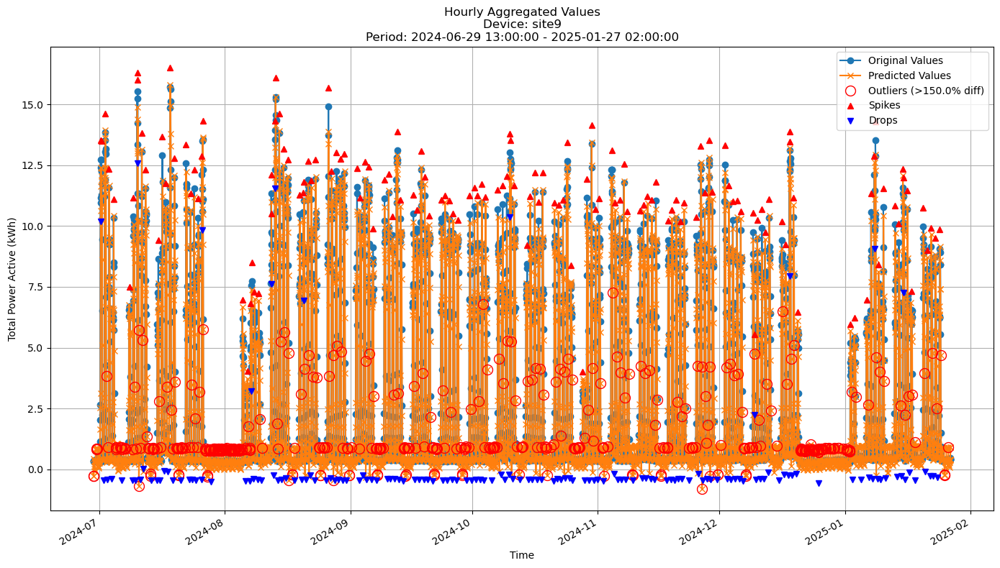


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.2780
MAE: 0.6346
MAPE: 54.5918%

Directional Metrics:
Directional Accuracy: 49.6849%
First-Diff Correlation: 0.2967

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0746
  Recall: 0.0676
  F1 Score: 0.0709
Drops:
  Precision: 0.0150
  Recall: 0.0135
  F1 Score: 0.0142

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.9403
  Recall: 0.8514
  F1 Score: 0.8936
Drops:
  Precision: 0.2556
  Recall: 0.2297
  F1 Score: 0.2420


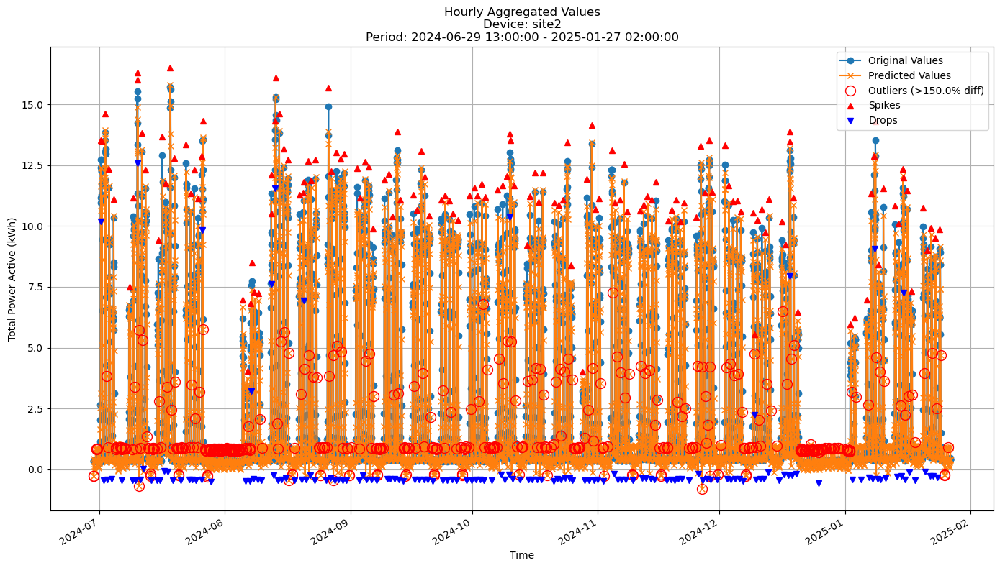


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.2780
MAE: 0.6346
MAPE: 54.5918%

Directional Metrics:
Directional Accuracy: 49.6849%
First-Diff Correlation: 0.2967

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0746
  Recall: 0.0676
  F1 Score: 0.0709
Drops:
  Precision: 0.0150
  Recall: 0.0135
  F1 Score: 0.0142

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.9403
  Recall: 0.8514
  F1 Score: 0.8936
Drops:
  Precision: 0.2556
  Recall: 0.2297
  F1 Score: 0.2420


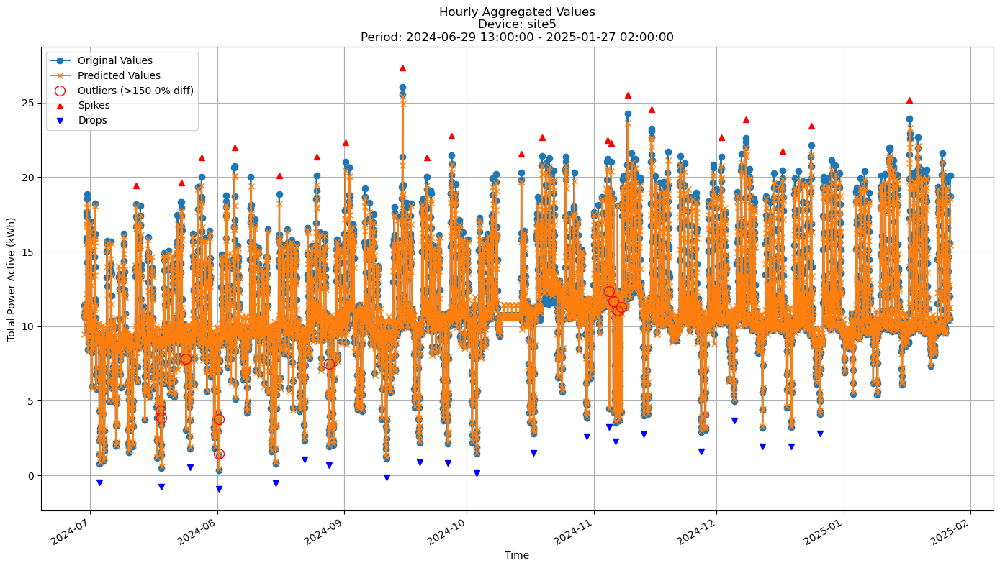


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.3760
MAE: 0.8813
MAPE: 9.1169%

Directional Metrics:
Directional Accuracy: 59.6692%
First-Diff Correlation: 0.1465

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 0.8095
  F1 Score: 0.8947
Drops:
  Precision: 1.0000
  Recall: 0.8571
  F1 Score: 0.9231


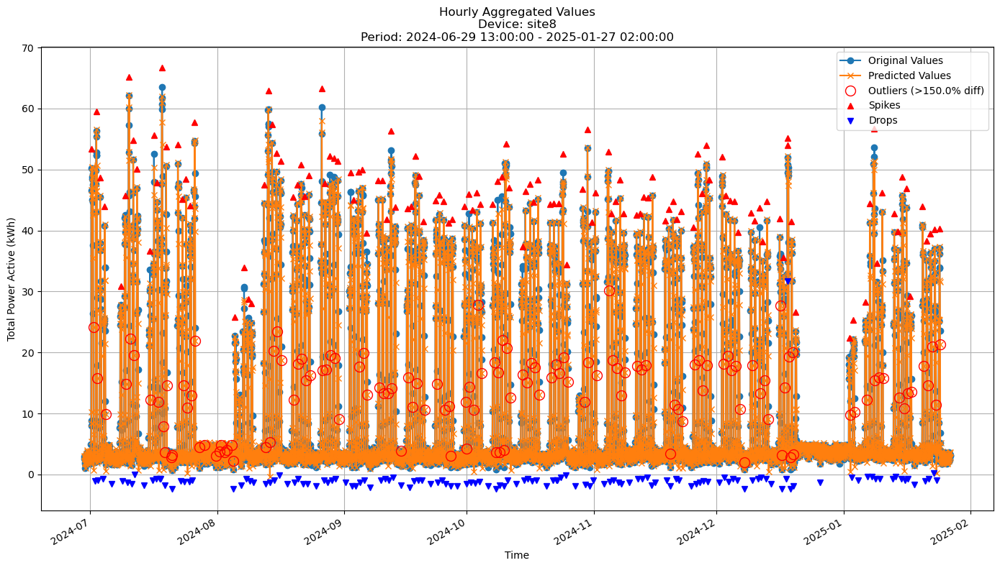


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 5.2707
MAE: 2.4748
MAPE: 30.8708%

Directional Metrics:
Directional Accuracy: 46.9279%
First-Diff Correlation: 0.2848

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0222
  Recall: 0.0222
  F1 Score: 0.0222
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.9481
  Recall: 0.9481
  F1 Score: 0.9481
Drops:
  Precision: 0.5597
  Recall: 0.5515
  F1 Score: 0.5556


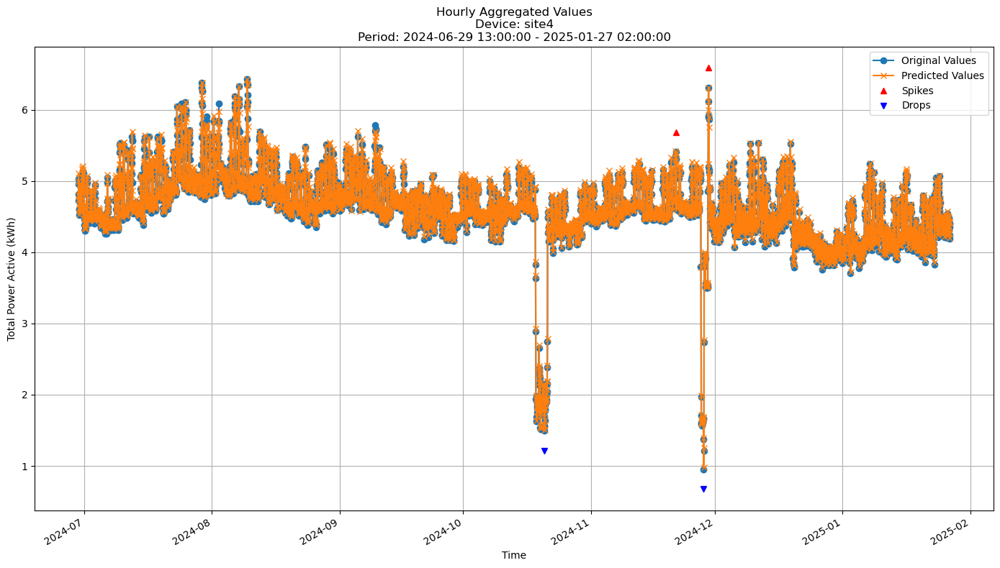


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1465
MAE: 0.0940
MAPE: 2.1086%

Directional Metrics:
Directional Accuracy: 45.1162%
First-Diff Correlation: 0.0343

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.5000
  Recall: 0.5000
  F1 Score: 0.5000
Drops:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000


In [ ]:
for device_id in incb_all_train_preds.keys():
    y_train = incb_all_train_preds[device_id][-1]['y_true']
    y_pred_train = incb_all_train_preds[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

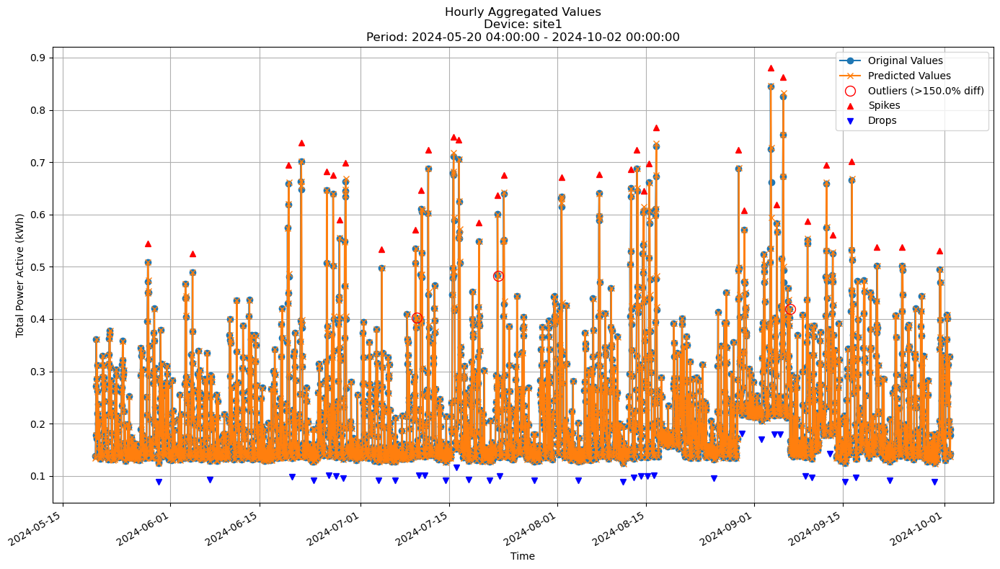


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0683
MAE: 0.0436
MAPE: 18.6467%

Directional Metrics:
Directional Accuracy: 42.3053%
First-Diff Correlation: -0.0929

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000


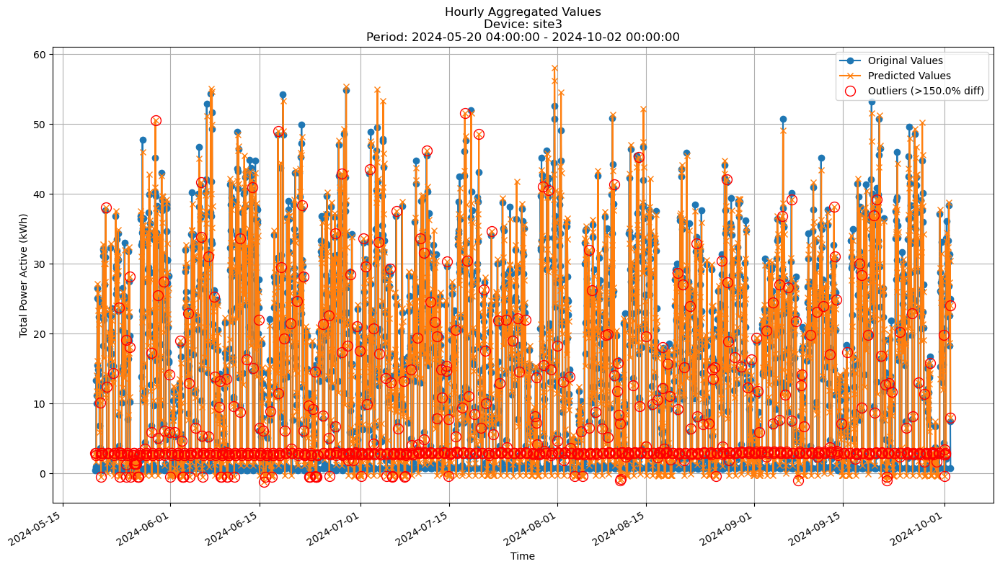


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 8.9750
MAE: 6.1820
MAPE: 129.1201%

Directional Metrics:
Directional Accuracy: 40.6057%
First-Diff Correlation: -0.1438

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


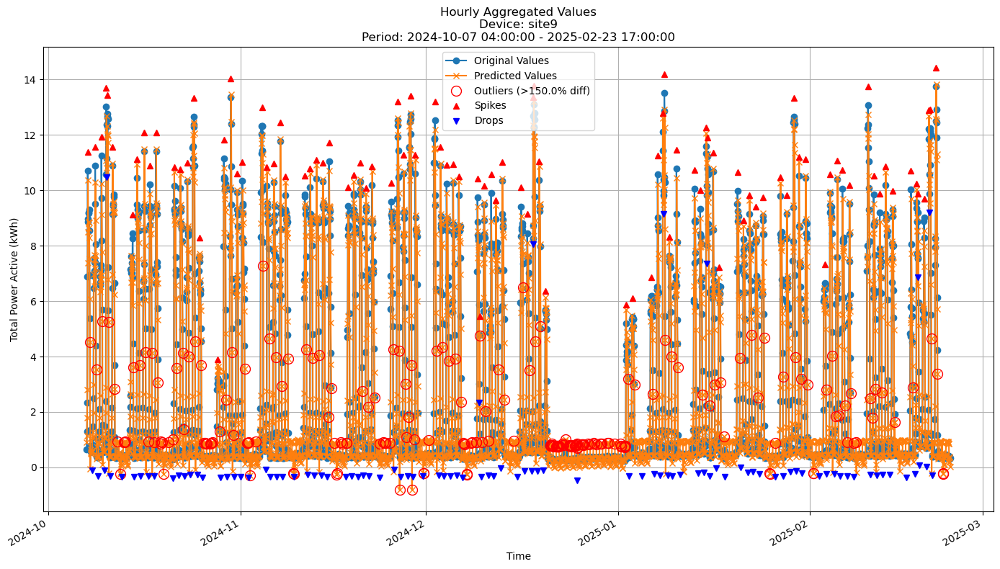


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.2423
MAE: 0.6280
MAPE: 51.9627%

Directional Metrics:
Directional Accuracy: 48.1791%
First-Diff Correlation: 0.2778

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0556
  Recall: 0.0505
  F1 Score: 0.0529
Drops:
  Precision: 0.0674
  Recall: 0.0612
  F1 Score: 0.0642

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.9333
  Recall: 0.8485
  F1 Score: 0.8889
Drops:
  Precision: 0.3034
  Recall: 0.2755
  F1 Score: 0.2888


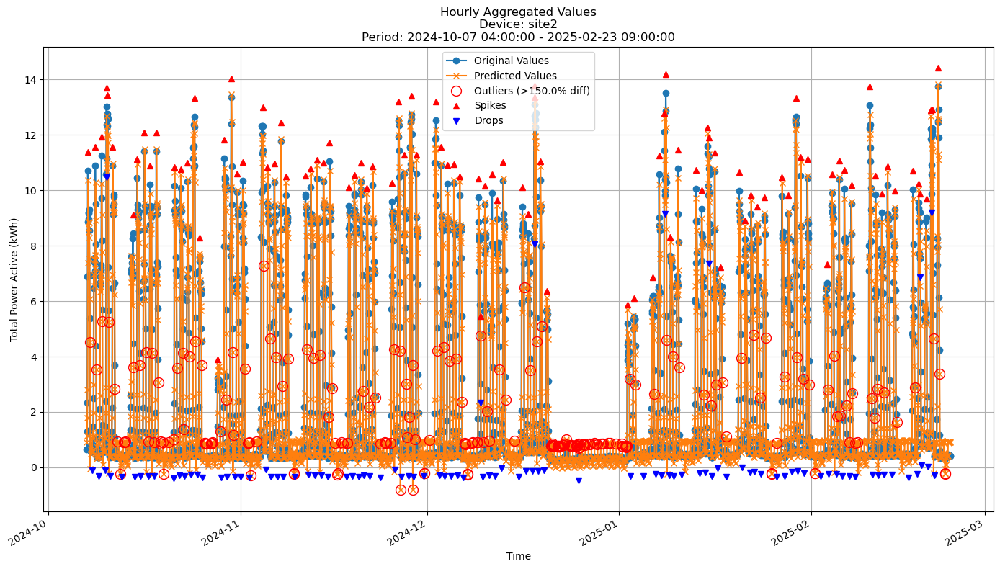


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.2436
MAE: 0.6288
MAPE: 51.8994%

Directional Metrics:
Directional Accuracy: 48.2047%
First-Diff Correlation: 0.2779

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0556
  Recall: 0.0505
  F1 Score: 0.0529
Drops:
  Precision: 0.0674
  Recall: 0.0612
  F1 Score: 0.0642

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.9333
  Recall: 0.8485
  F1 Score: 0.8889
Drops:
  Precision: 0.3034
  Recall: 0.2755
  F1 Score: 0.2888


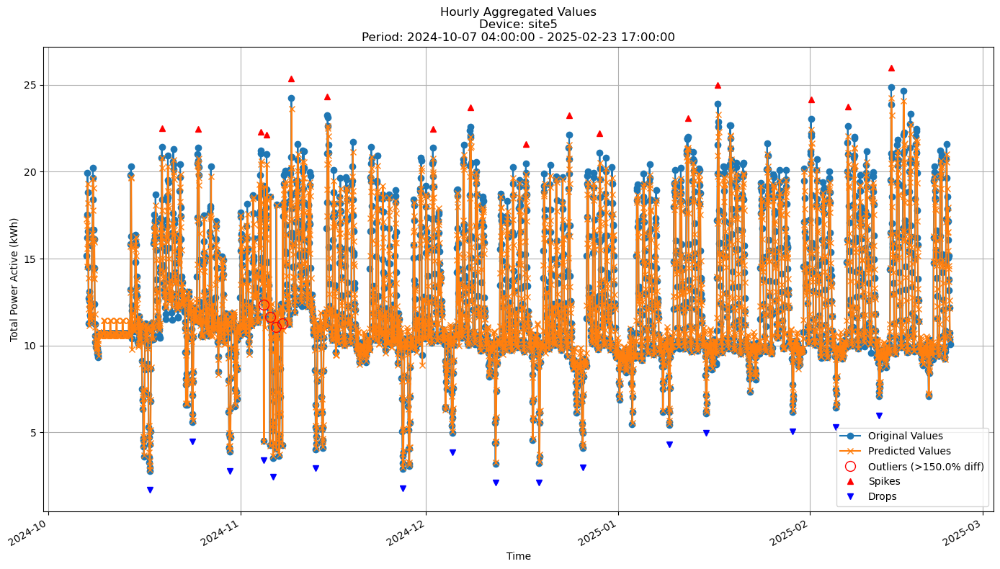


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 1.3204
MAE: 0.8194
MAPE: 6.6555%

Directional Metrics:
Directional Accuracy: 62.4776%
First-Diff Correlation: 0.2168

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 0.7500
  F1 Score: 0.8571
Drops:
  Precision: 1.0000
  Recall: 0.7500
  F1 Score: 0.8571


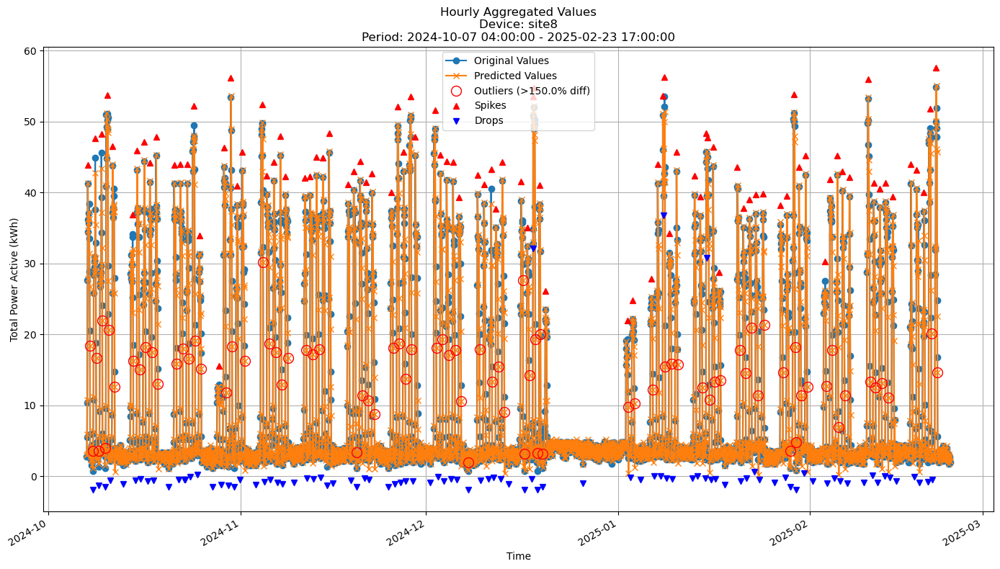


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 5.1840
MAE: 2.4323
MAPE: 29.7818%

Directional Metrics:
Directional Accuracy: 45.4030%
First-Diff Correlation: 0.2516

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0211
  Recall: 0.0211
  F1 Score: 0.0211
Drops:
  Precision: 0.0106
  Recall: 0.0105
  F1 Score: 0.0106

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.9684
  Recall: 0.9684
  F1 Score: 0.9684
Drops:
  Precision: 0.5745
  Recall: 0.5684
  F1 Score: 0.5714


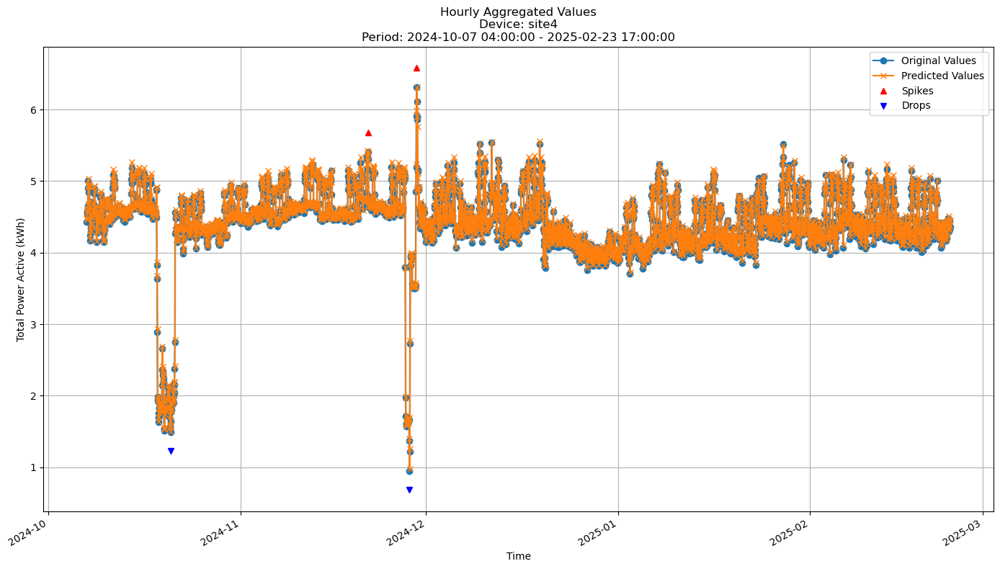


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1729
MAE: 0.1141
MAPE: 2.6681%

Directional Metrics:
Directional Accuracy: 39.6119%
First-Diff Correlation: -0.1063

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.5000
  Recall: 0.5000
  F1 Score: 0.5000
Drops:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000


In [ ]:
join_periods = [-5, -4, -3, -2, -1]
# Device iteration
for device_id in incb_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, incb_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, incb_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

In [50]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario:

elastic_weighted_ratio = IncubationBoostWeightedRatio

elastic_weighted_ratio_params = {
    'length': 40, 
    'learning_rate': 0.001,
    'depth': 20,
    'grace_period': 24,
    'grace_period_depth': -1,
    'split_confidence': 0.05,
    'max_feature': 0.7,
    'tie_threshold': 0.05,
    'bin_type': 'adaptive',
    'max_bins': 32,
    'split_criterion': 'vr_rel',
    'verbose': False,
    'wr_fixed_multiplier': 1.8,
    'wr_alpha': 1.2,
    'wr_beta': 0.5,
    'wr_gamma': 0.1,
    'wr_baseline': 0.0,
    'wr_min_keep': 2,
    'wr_error_agg': ['ema'],
    'wr_ema_decay': 0.8,
    'wr_gate_eps': 0.15,
    'wr_cooldown': 16}


In [51]:
elastic_weighted_ratio_all_train_preds, elastic_weighted_ratio_all_valid_preds, \
elastic_weighted_ratio_all_train_metrics, elastic_weighted_ratio_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=elastic_weighted_ratio, 
    model_params=elastic_weighted_ratio_params,
    train=train, 
    valid=valid, 
    use_residuals=USE_RESIDUAL,
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    # end_split=1,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/25 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/2 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 04:00:00+01:00 to 2023-03-27 03:00:00+02:00
Model's memory usage: 0.134567 MB
Metrics for Device: site1 | Period: 2023-03-27 04:00:00+02:00 - 2023-04-24 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0761
	MAE: 0.0516
	MAPE: 18.9187%

Directional Metrics:
	Directional Accuracy: 50.6706%
	First-Diff Correlation: -0.0009

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0909
		Recall: 0.0909
		F1: 0.0909

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 0.9545
		Recall: 0.9545
		F1: 0.9545
--------------------------------------------------
Da

Processing devices in split 1:   0%|          | 0/2 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 04:00:00+01:00 to 2023-04-24 03:00:00+02:00
Model's memory usage: 0.325554 MB
Metrics for Device: site1 | Period: 2023-04-24 04:00:00+02:00 - 2023-05-22 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0586
	MAE: 0.0385
	MAPE: 18.4084%

Directional Metrics:
	Directional Accuracy: 42.1759%
	First-Diff Correlation: -0.1741

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0200
		Recall: 0.0233
		F1: 0.0215
	Drops:
		Precision: 0.0200
		Recall: 0.0217
		F1: 0.0208

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.7800
		Recall: 0.9070
		F1: 0.8387
	Drops:
		Precision: 0.7600
		Recall: 0.8261
		F1: 0.7917
--------------------------------------------------
Da

Processing devices in split 2:   0%|          | 0/2 [00:00<?, ?it/s]

... (41 outputs left out)

Processing devices in split 23:   0%|          | 0/7 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 13:00:00+02:00 to 2024-12-30 02:00:00+01:00
Model's memory usage: 1.450974 MB
Metrics for Device: site9 | Period: 2024-12-30 03:00:00+01:00 - 2025-01-27 02:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.1906
	MAE: 0.5242
	MAPE: 28.7597%

Directional Metrics:
	Directional Accuracy: 49.1803%
	First-Diff Correlation: 0.2691

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1071
		Recall: 0.1000
		F1: 0.1034
	Drops:
		Precision: 0.1429
		Recall: 0.1379
		F1: 0.1404

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.8214
		Recall: 0.7667
		F1: 0.7931
	Drops:
		Precision: 0.5714
		Recall: 0.5517
		F1: 0.5614
--------------------------------------------------
Dai

Processing devices in split 24:   0%|          | 0/7 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 13:00:00+02:00 to 2025-01-27 02:00:00+01:00
Model's memory usage: 2.697838 MB
Metrics for Device: site9 | Period: 2025-01-27 03:00:00+01:00 - 2025-02-23 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.2288
	MAE: 0.5921
	MAPE: 29.9856%

Directional Metrics:
	Directional Accuracy: 52.7190%
	First-Diff Correlation: 0.3927

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0345
		Recall: 0.0357
		F1: 0.0351
	Drops:
		Precision: 0.1071
		Recall: 0.1111
		F1: 0.1091

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.7241
		Recall: 0.7500
		F1: 0.7368
	Drops:
		Precision: 0.3929
		Recall: 0.4074
		F1: 0.4000
--------------------------------------------------
Dai

In [52]:
print("\n\nTrain period metrics:")
elastic_weighted_ratio_all_time_train_metrics = all_time_aggregation_metrics(elastic_weighted_ratio_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
elastic_weighted_ratio_all_time_valid_metrics = all_time_aggregation_metrics(elastic_weighted_ratio_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: site1
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0709 ± 0.0063
	MAE: 0.0474 ± 0.0047
	MAPE: 17.7503% ± 0.7629%

	Directional Metrics:
		Directional Accuracy: 49.0149% ± 1.9846%
		First-Diff Correlation: 0.0160 ± 0.0464

	Immediate Detection (delta=0):
		Spike Precision: 0.0536 ± 0.0343
		Spike Recall: 0.0547 ± 0.0364
		Spike F1: 0.0540 ± 0.0352
		Drop Precision: 0.0498 ± 0.0264
		Drop Recall: 0.0496 ± 0.0282
		Drop F1: 0.0496 ± 0.0271

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.8469 ± 0.0919
		Spike Recall: 0.8382 ± 0.0605
		Spike F1: 0.8402 ± 0.0654
		Drop Precision: 0.6812 ± 0.1424
		Drop Recall: 0.6497 ± 0.0969
		Drop F1: 0.6629 ± 0.1142
Daily Metrics:
	RMSE: 0.2444 ± 0.1337
	MAE: 0.1675 ± 0.0828
	MAPE: 2.3076% ± 0.9089%

	Directional Metrics:
		Directional Accuracy: 96.4050% ± 1.7178%
		First-Diff Correlation: 0.9933 ± 0.0028

	Immediate Detection (delta=0):
		Spik

In [53]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario:


elastic = IncubationBoostElastic
elastic_params = {
    'length': 50, 
    'learning_rate': 0.1,
    'depth': 30,
    'grace_period': 48,
    'grace_period_depth': -1,
    'split_confidence': 0.1,
    'max_feature': 1,
    'tie_threshold': 0.05,
    'bin_type': 'adaptive',
    'max_bins': 16,
    'split_criterion': 'vr_rel',
    'verbose': False,
    'pruning_strategy': 'new_egbdt',}


In [54]:
elastic_all_train_preds, elastic_all_valid_preds, \
elastic_all_train_metrics, elastic_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model_class=elastic, 
    model_params=elastic_params,
    train=train, 
    valid=valid, 
    use_residuals=USE_RESIDUAL,
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    forecast_horizon=FORECAST_HORIZON,
    features=ALL_FEATURES,
    update_freq=update_freq,
    spike_prominence=SPIKE_PROMINENCE, 
    start_split=0, 
    # end_split=1,  # Use only the third and fourth splits
    verbose=1
)

Processing splits:   0%|          | 0/25 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/2 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 04:00:00+01:00 to 2023-03-27 03:00:00+02:00
Model's memory usage: 0.387604 MB
Metrics for Device: site1 | Period: 2023-03-27 04:00:00+02:00 - 2023-04-24 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0784
	MAE: 0.0533
	MAPE: 19.3865%

Directional Metrics:
	Directional Accuracy: 50.3726%
	First-Diff Correlation: 0.0007

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0400
		Recall: 0.0435
		F1: 0.0417
	Drops:
		Precision: 0.0800
		Recall: 0.0909
		F1: 0.0851

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.8400
		Recall: 0.9130
		F1: 0.8750
	Drops:
		Precision: 0.6800
		Recall: 0.7727
		F1: 0.7234
--------------------------------------------------
Dai

Processing devices in split 1:   0%|          | 0/2 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2023-02-27 04:00:00+01:00 to 2023-04-24 03:00:00+02:00
Model's memory usage: 0.777962 MB
Metrics for Device: site1 | Period: 2023-04-24 04:00:00+02:00 - 2023-05-22 03:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0588
	MAE: 0.0388
	MAPE: 18.4075%

Directional Metrics:
	Directional Accuracy: 41.1326%
	First-Diff Correlation: -0.2172

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0500
		Recall: 0.0435
		F1: 0.0465

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.8293
		Recall: 0.7907
		F1: 0.8095
	Drops:
		Precision: 0.6000
		Recall: 0.5217
		F1: 0.5581
--------------------------------------------------
Da

Processing devices in split 2:   0%|          | 0/2 [00:00<?, ?it/s]

... (41 outputs left out)

Processing devices in split 23:   0%|          | 0/7 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 13:00:00+02:00 to 2024-12-30 02:00:00+01:00
Model's memory usage: 3.068161 MB
Metrics for Device: site9 | Period: 2024-12-30 03:00:00+01:00 - 2025-01-27 02:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.0962
	MAE: 0.4465
	MAPE: 24.5055%

Directional Metrics:
	Directional Accuracy: 50.0745%
	First-Diff Correlation: 0.2466

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0333
		Recall: 0.0333
		F1: 0.0333
	Drops:
		Precision: 0.0345
		Recall: 0.0345
		F1: 0.0345

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.7333
		Recall: 0.7333
		F1: 0.7333
	Drops:
		Precision: 0.5517
		Recall: 0.5517
		F1: 0.5517
--------------------------------------------------
Dai

Processing devices in split 24:   0%|          | 0/7 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 13:00:00+02:00 to 2025-01-27 02:00:00+01:00
Model's memory usage: 3.520782 MB
Metrics for Device: site9 | Period: 2025-01-27 03:00:00+01:00 - 2025-02-23 17:00:00+01:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.2698
	MAE: 0.6009
	MAPE: 29.9467%

Directional Metrics:
	Directional Accuracy: 53.0211%
	First-Diff Correlation: 0.3205

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0270
		Recall: 0.0357
		F1: 0.0308
	Drops:
		Precision: 0.0556
		Recall: 0.0741
		F1: 0.0635

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.6486
		Recall: 0.8571
		F1: 0.7385
	Drops:
		Precision: 0.4444
		Recall: 0.5926
		F1: 0.5079
--------------------------------------------------
Dai

In [55]:
print("\n\nTrain period metrics:")
elastic_all_time_train_metrics = all_time_aggregation_metrics(elastic_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
elastic_all_time_valid_metrics = all_time_aggregation_metrics(elastic_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: site1
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0686 ± 0.0061
	MAE: 0.0461 ± 0.0048
	MAPE: 17.2720% ± 0.8950%

	Directional Metrics:
		Directional Accuracy: 48.4516% ± 2.2014%
		First-Diff Correlation: 0.0029 ± 0.0340

	Immediate Detection (delta=0):
		Spike Precision: 0.0746 ± 0.0392
		Spike Recall: 0.0750 ± 0.0454
		Spike F1: 0.0745 ± 0.0421
		Drop Precision: 0.0463 ± 0.0238
		Drop Recall: 0.0435 ± 0.0220
		Drop F1: 0.0447 ± 0.0226

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.8077 ± 0.0916
		Spike Recall: 0.7763 ± 0.0829
		Spike F1: 0.7884 ± 0.0720
		Drop Precision: 0.6280 ± 0.1257
		Drop Recall: 0.5904 ± 0.1324
		Drop F1: 0.6061 ± 0.1244
Daily Metrics:
	RMSE: 0.1730 ± 0.0475
	MAE: 0.1220 ± 0.0420
	MAPE: 1.7508% ± 0.6541%

	Directional Metrics:
		Directional Accuracy: 96.3952% ± 1.2869%
		First-Diff Correlation: 0.9955 ± 0.0009

	Immediate Detection (delta=0):
		Spik

# Test-set Model Evaluation
(`train[-1]` + `valid[-1]`) vs `test`

In [56]:
# Define model classes and params for test-set evaluation
models_classes = [bl_prev, bl_mean, gbdt, rf, hoef, arf_hf, fodt, arf, incb, elastic_weighted_ratio, elastic]
models_params = [
    bl_prev_params,
    bl_mean_params,
    gbdt_params,
    rf_params,
    hoef_params,
    arf_hf_params,
    fodt_params,
    xfodt_params,
    arf_params,
    incb_params,
    elastic_weighted_ratio_params,
    elastic_params
 ]

model_test_results = {}
for model_class, params in zip(models_classes, models_params):
    if model_class in [gbdt, rf, bl_mean]:
        incremental = False
        update_freq = "14D"
        print(f"Model: {model_class.__name__} - update_freq: {update_freq}")
    else:
        incremental = True
        update_freq = "1h"
        print(f"Model: {model_class.__name__} - update_freq: {update_freq}")

    _, test_preds, \
    _, test_metrics = test_set_seq_fit_predict(
        model_class=model_class,
        model_params=params,
        train=train,
        valid=valid,
        test=test,
        use_residuals=USE_RESIDUAL,
        incremental=incremental,
        data_freq=DATA_FREQUENCY,
        forecast_horizon=FORECAST_HORIZON,
        features=ALL_FEATURES,
        update_freq=update_freq,
        spike_prominence=SPIKE_PROMINENCE,
        normalize_robust=True,
        predict_train=False,
        verbose=True
    )
    model_test_results[model_class.__name__] = {
        "test_preds": test_preds,
        "test_metrics": test_metrics
    }

Model: PreviousValueRegressor - update_freq: 1h


Processing devices for test predictions:   0%|          | 0/7 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 13:00:00+02:00 to 2025-02-23 17:00:00+01:00
Model's memory usage: 0.000290 MB
Metrics for Device: site9 | Period: 2025-02-23 19:00:00+01:00 - 2025-04-24 21:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.4671
	MAE: 0.6480
	MAPE: 27.5630%

Directional Metrics:
	Directional Accuracy: 53.9903%
	First-Diff Correlation: 0.3313

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Dai

Processing devices for test predictions:   0%|          | 0/7 [00:00<?, ?it/s]


Retraining model on data from 2024-06-29 13:00:00+02:00 to 2025-02-23 17:00:00+01:00

Time: 0.00 seconds
Predicting for chunk from 2025-02-23 19:00:00+01:00 to 2025-03-09 19:00:00+01:00

-------------------------

Retraining model on data from 2024-06-29 13:00:00+02:00 to 2025-03-09 19:00:00+01:00

Time: 0.00 seconds
Predicting for chunk from 2025-03-09 20:00:00+01:00 to 2025-03-23 20:00:00+01:00

-------------------------

Retraining model on data from 2024-06-29 13:00:00+02:00 to 2025-03-23 20:00:00+01:00

Time: 0.00 seconds
Predicting for chunk from 2025-03-23 21:00:00+01:00 to 2025-04-06 22:00:00+02:00

-------------------------

Retraining model on data from 2024-06-29 13:00:00+02:00 to 2025-04-06 22:00:00+02:00

Time: 0.00 seconds
Predicting for chunk from 2025-04-06 23:00:00+02:00 to 2025-04-20 23:00:00+02:00

-------------------------

Retraining model on data from 2024-06-29 13:00:00+02:00 to 2025-04-20 23:00:00+02:00

Time: 0.00 seconds
Predicting for chunk from 2025-04-21 0

Processing devices for test predictions:   0%|          | 0/7 [00:00<?, ?it/s]

... (13 outputs left out)

Processing devices for test predictions:   0%|          | 0/7 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 13:00:00+02:00 to 2025-02-23 17:00:00+01:00
Model's memory usage: 3.050346 MB
Metrics for Device: site9 | Period: 2025-02-23 19:00:00+01:00 - 2025-04-24 21:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.1478
	MAE: 0.5255
	MAPE: 27.8790%

Directional Metrics:
	Directional Accuracy: 56.3498%
	First-Diff Correlation: 0.4444

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0441
		Recall: 0.0484
		F1: 0.0462
	Drops:
		Precision: 0.0896
		Recall: 0.0984
		F1: 0.0938

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.7353
		Recall: 0.8065
		F1: 0.7692
	Drops:
		Precision: 0.4328
		Recall: 0.4754
		F1: 0.4531
--------------------------------------------------
Dai

Processing devices for test predictions:   0%|          | 0/7 [00:00<?, ?it/s]

Filtering features for forecast horizon 1h
Original feature count: 7
Filtered feature count: 7
Excluded lag features: None
Initial training on data from 2024-06-29 13:00:00+02:00 to 2025-02-23 17:00:00+01:00
Model's memory usage: 4.361649 MB
Metrics for Device: site9 | Period: 2025-02-23 19:00:00+01:00 - 2025-04-24 21:00:00+02:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 1.2574
	MAE: 0.5806
	MAPE: 32.1053%

Directional Metrics:
	Directional Accuracy: 52.7412%
	First-Diff Correlation: 0.3600

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0267
		Recall: 0.0328
		F1: 0.0294

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.6184
		Recall: 0.7581
		F1: 0.6812
	Drops:
		Precision: 0.3867
		Recall: 0.4754
		F1: 0.4265
--------------------------------------------------
Dai

In [57]:
for model in models_classes:
    model_test_results[model.__name__]['test_metrics'] = all_time_aggregation_metrics(
        model_test_results[model.__name__]['test_metrics'],
        data_freq=DATA_FREQUENCY,
        verbose=False)

# Model Comparison

In [58]:
AGG_LEVEL = "hourly"
METRICS = ["rmse", "mae", "mape", "dir_accuracy", "first_diff_corr"]
PERC_METRICS = ["mape", "dir_accuracy", "first_diff_corr"]
# SPIKES_METRICS = ["spikes_immediate.precision", "spikes_immediate.recall", "spikes_immediate.f1",
#                   "spikes_delayed.precision", "spikes_delayed.recall", "spikes_delayed.f1",
#                   "drops_immediate.precision", "drops_immediate.recall", "drops_immediate.f1",
#                   "drops_delayed.precision", "drops_delayed.recall", "drops_delayed.f1"]
SPIKES_METRICS = ["spikes_immediate.f1", "spikes_delayed.f1",
                  "drops_immediate.f1", "drops_delayed.f1"]

METRICS.extend(SPIKES_METRICS)
PERC_METRICS.extend(SPIKES_METRICS)

## Test results

In [59]:
MODEL_TEST_METRICS = {
    "BL_Prev": model_test_results[bl_prev.__name__]["test_metrics"],
    "BL_Mean": model_test_results[bl_mean.__name__]["test_metrics"],
    "GBDT": model_test_results[gbdt.__name__]["test_metrics"],
    "RandomForest": model_test_results[rf.__name__]["test_metrics"],
    "HoeffdingTree": model_test_results[hoef.__name__]["test_metrics"],
    "ARF_Hoeffding": model_test_results[arf_hf.__name__]["test_metrics"],
    "FastODT": model_test_results[fodt.__name__]["test_metrics"],
    "xFastODT": model_test_results[xfodt.__name__]["test_metrics"],
    "ARF_FastODT": model_test_results[arf.__name__]["test_metrics"],
    "IncubationBoost": model_test_results[incb.__name__]["test_metrics"],
    "IncubationBoost_WR": model_test_results[elastic_weighted_ratio.__name__]["test_metrics"],
    "IncubationBoost_Elastic": model_test_results[elastic.__name__]["test_metrics"]
}

In [60]:
def format_metric(val, is_perc=False):
    if isinstance(val, dict) and "mean" in val and "std" in val:
        mean = val["mean"]
        std = val["std"]
        if is_perc:
            mean = mean * 100
            std = std * 100
        return f"{mean:.3f} ± {std:.3f}"
    if is_perc:
        return f"{val*100:.3f}" if val is not None else None
    return f"{val:.3f}" if val is not None else None

def display_aggregated_results(model_metrics, device_ids, agg_level):
    for device_id in device_ids:
        rows = []
        for model, mdict in model_metrics.items():
            if device_id in mdict and agg_level in mdict[device_id]:
                vals = mdict[device_id][agg_level]
                row = [model]
                for m in METRICS:
                    is_perc = (m in PERC_METRICS)
                    row.append(format_metric(vals.get(m, None), is_perc=is_perc))
                rows.append(row)
        df = pd.DataFrame(rows, columns=["Model", "RMSE", "MAE", "MAPE (%)", "Directional Accuracy (%)", "First Diff Corr (%)",
                                         "Spikes Immediate F1 (%)", "Spikes Delayed F1 (%)", "Drops Immediate F1 (%)", "Drops Delayed F1 (%)"])
        print(f"\n\nDevice: {device_id} | Aggregation: {agg_level}")
        display(df)

In [61]:
device_ids = set()
for m in MODEL_TEST_METRICS.values():
    device_ids.update(m.keys())
device_ids = sorted(device_ids)

print("\n\n============================Hourly Test Results============================")
display_aggregated_results(MODEL_TEST_METRICS, device_ids, AGG_LEVEL)



============================Hourly Test Results============================


Device: site1 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,0.091 ± 0.000,0.064 ± 0.000,13.586 ± 0.000,49.600 ± 0.000,-4.671 ± 0.000,0.000 ± 0.000,100.000 ± 0.000,0.000 ± 0.000,100.000 ± 0.000
1,BL_Mean,0.066 ± 0.000,0.047 ± 0.000,10.160 ± 0.000,59.195 ± 0.000,34.993 ± 0.000,16.667 ± 0.000,66.667 ± 0.000,20.339 ± 0.000,84.746 ± 0.000
2,GBDT,0.065 ± 0.000,0.045 ± 0.000,9.915 ± 0.000,59.338 ± 0.000,35.130 ± 0.000,16.129 ± 0.000,74.194 ± 0.000,22.951 ± 0.000,72.131 ± 0.000
3,RandomForest,0.065 ± 0.000,0.046 ± 0.000,9.914 ± 0.000,58.995 ± 0.000,34.692 ± 0.000,6.250 ± 0.000,75.000 ± 0.000,22.222 ± 0.000,76.190 ± 0.000
4,HoeffdingTree,0.074 ± 0.000,0.053 ± 0.000,11.241 ± 0.000,57.453 ± 0.000,23.095 ± 0.000,12.308 ± 0.000,80.000 ± 0.000,18.750 ± 0.000,81.250 ± 0.000
5,ARF_Hoeffding,0.073 ± 0.000,0.052 ± 0.000,11.300 ± 0.000,54.397 ± 0.000,14.820 ± 0.000,3.226 ± 0.000,74.194 ± 0.000,19.672 ± 0.000,75.410 ± 0.000
6,FastODT,0.085 ± 0.000,0.060 ± 0.000,13.338 ± 0.000,54.483 ± 0.000,17.529 ± 0.000,8.219 ± 0.000,68.493 ± 0.000,30.137 ± 0.000,68.493 ± 0.000
7,ARF_FastODT,0.077 ± 0.000,0.054 ± 0.000,11.576 ± 0.000,52.656 ± 0.000,5.684 ± 0.000,0.000 ± 0.000,70.968 ± 0.000,13.115 ± 0.000,75.410 ± 0.000
8,IncubationBoost,0.091 ± 0.000,0.064 ± 0.000,13.499 ± 0.000,49.629 ± 0.000,-3.532 ± 0.000,6.250 ± 0.000,90.625 ± 0.000,0.000 ± 0.000,93.750 ± 0.000
9,IncubationBoost_WR,0.088 ± 0.000,0.061 ± 0.000,13.164 ± 0.000,51.970 ± 0.000,2.418 ± 0.000,0.000 ± 0.000,66.667 ± 0.000,5.882 ± 0.000,64.706 ± 0.000




Device: site2 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,1.458 ± 0.000,0.641 ± 0.000,27.145 ± 0.000,53.857 ± 0.000,32.903 ± 0.000,0.000 ± 0.000,99.200 ± 0.000,0.000 ± 0.000,100.000 ± 0.000
1,BL_Mean,0.788 ± 0.000,0.381 ± 0.000,22.887 ± 0.000,59.555 ± 0.000,67.017 ± 0.000,4.651 ± 0.000,79.070 ± 0.000,10.938 ± 0.000,57.812 ± 0.000
2,GBDT,0.753 ± 0.000,0.362 ± 0.000,17.991 ± 0.000,57.679 ± 0.000,66.736 ± 0.000,5.369 ± 0.000,72.483 ± 0.000,13.605 ± 0.000,38.095 ± 0.000
3,RandomForest,0.754 ± 0.000,0.359 ± 0.000,17.342 ± 0.000,58.999 ± 0.000,66.283 ± 0.000,5.674 ± 0.000,72.340 ± 0.000,12.857 ± 0.000,34.286 ± 0.000
4,HoeffdingTree,0.893 ± 0.000,0.434 ± 0.000,24.408 ± 0.000,55.316 ± 0.000,58.692 ± 0.000,9.655 ± 0.000,77.241 ± 0.000,9.722 ± 0.000,40.278 ± 0.000
5,ARF_Hoeffding,0.837 ± 0.000,0.417 ± 0.000,26.237 ± 0.000,58.235 ± 0.000,58.844 ± 0.000,5.357 ± 0.000,82.143 ± 0.000,7.273 ± 0.000,34.545 ± 0.000
6,FastODT,1.321 ± 0.000,0.645 ± 0.000,39.024 ± 0.000,52.953 ± 0.000,27.268 ± 0.000,11.613 ± 0.000,69.677 ± 0.000,5.195 ± 0.000,44.156 ± 0.000
7,ARF_FastODT,0.833 ± 0.000,0.426 ± 0.000,24.102 ± 0.000,57.540 ± 0.000,56.060 ± 0.000,8.333 ± 0.000,78.333 ± 0.000,13.445 ± 0.000,48.739 ± 0.000
8,IncubationBoost,1.308 ± 0.000,0.670 ± 0.000,50.292 ± 0.000,53.718 ± 0.000,33.206 ± 0.000,3.846 ± 0.000,78.846 ± 0.000,5.825 ± 0.000,27.184 ± 0.000
9,IncubationBoost_WR,1.325 ± 0.000,0.642 ± 0.000,37.019 ± 0.000,53.440 ± 0.000,36.294 ± 0.000,0.000 ± 0.000,75.862 ± 0.000,5.556 ± 0.000,48.611 ± 0.000




Device: site3 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,8.845 ± 0.000,5.426 ± 0.000,53.730 ± 0.000,44.232 ± 0.000,-6.889 ± 0.000,0.000 ± 0.000,100.000 ± 0.000,0.000 ± 0.000,100.000 ± 0.000
1,BL_Mean,6.696 ± 0.000,4.441 ± 0.000,56.571 ± 0.000,51.628 ± 0.000,26.910 ± 0.000,7.092 ± 0.000,45.390 ± 0.000,15.484 ± 0.000,38.710 ± 0.000
2,GBDT,6.507 ± 0.000,4.173 ± 0.000,43.316 ± 0.000,51.513 ± 0.000,29.830 ± 0.000,5.479 ± 0.000,46.575 ± 0.000,21.250 ± 0.000,47.500 ± 0.000
3,RandomForest,6.558 ± 0.000,4.185 ± 0.000,40.587 ± 0.000,52.113 ± 0.000,29.651 ± 0.000,5.333 ± 0.000,49.333 ± 0.000,13.415 ± 0.000,45.122 ± 0.000
4,HoeffdingTree,7.602 ± 0.000,4.921 ± 0.000,50.999 ± 0.000,49.372 ± 0.000,15.179 ± 0.000,6.369 ± 0.000,47.134 ± 0.000,19.883 ± 0.000,43.275 ± 0.000
5,ARF_Hoeffding,7.391 ± 0.000,4.946 ± 0.000,59.013 ± 0.000,49.829 ± 0.000,4.999 ± 0.000,5.128 ± 0.000,65.385 ± 0.000,23.529 ± 0.000,54.118 ± 0.000
6,FastODT,8.433 ± 0.000,5.392 ± 0.000,53.099 ± 0.000,48.287 ± 0.000,6.593 ± 0.000,5.063 ± 0.000,51.899 ± 0.000,22.093 ± 0.000,43.023 ± 0.000
7,ARF_FastODT,7.024 ± 0.000,4.684 ± 0.000,51.492 ± 0.000,50.286 ± 0.000,9.965 ± 0.000,6.711 ± 0.000,53.691 ± 0.000,22.086 ± 0.000,39.264 ± 0.000
8,IncubationBoost,8.921 ± 0.000,5.826 ± 0.000,81.452 ± 0.000,42.519 ± 0.000,-8.534 ± 0.000,3.593 ± 0.000,61.078 ± 0.000,17.989 ± 0.000,68.783 ± 0.000
9,IncubationBoost_WR,7.550 ± 0.000,4.815 ± 0.000,46.769 ± 0.000,47.944 ± 0.000,6.714 ± 0.000,1.538 ± 0.000,70.769 ± 0.000,9.722 ± 0.000,43.056 ± 0.000


... (4 outputs left out)



Device: site8 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,5.878 ± 0.000,2.907 ± 0.000,35.259 ± 0.000,46.565 ± 0.000,30.963 ± 0.000,0.000 ± 0.000,100.000 ± 0.000,0.000 ± 0.000,100.000 ± 0.000
1,BL_Mean,3.358 ± 0.000,1.899 ± 0.000,29.345 ± 0.000,50.520 ± 0.000,61.800 ± 0.000,2.083 ± 0.000,83.333 ± 0.000,4.255 ± 0.000,53.191 ± 0.000
2,GBDT,3.368 ± 0.000,1.874 ± 0.000,27.523 ± 0.000,49.063 ± 0.000,59.613 ± 0.000,8.081 ± 0.000,76.768 ± 0.000,2.062 ± 0.000,49.485 ± 0.000
3,RandomForest,3.357 ± 0.000,1.869 ± 0.000,27.574 ± 0.000,48.092 ± 0.000,59.255 ± 0.000,8.247 ± 0.000,78.351 ± 0.000,2.105 ± 0.000,50.526 ± 0.000
4,HoeffdingTree,4.127 ± 0.000,2.370 ± 0.000,36.576 ± 0.000,49.480 ± 0.000,50.083 ± 0.000,3.571 ± 0.000,66.071 ± 0.000,3.636 ± 0.000,20.000 ± 0.000
5,ARF_Hoeffding,4.131 ± 0.000,2.284 ± 0.000,34.740 ± 0.000,49.133 ± 0.000,45.819 ± 0.000,2.174 ± 0.000,80.435 ± 0.000,2.222 ± 0.000,46.667 ± 0.000
6,FastODT,4.533 ± 0.000,2.553 ± 0.000,41.121 ± 0.000,48.230 ± 0.000,46.735 ± 0.000,12.069 ± 0.000,63.793 ± 0.000,3.509 ± 0.000,43.860 ± 0.000
7,ARF_FastODT,3.737 ± 0.000,2.117 ± 0.000,32.369 ± 0.000,50.590 ± 0.000,48.665 ± 0.000,6.061 ± 0.000,80.808 ± 0.000,2.062 ± 0.000,41.237 ± 0.000
8,IncubationBoost,5.493 ± 0.000,2.704 ± 0.000,33.830 ± 0.000,46.704 ± 0.000,31.189 ± 0.000,4.494 ± 0.000,98.876 ± 0.000,4.598 ± 0.000,64.368 ± 0.000
9,IncubationBoost_WR,5.074 ± 0.000,2.645 ± 0.000,38.348 ± 0.000,48.508 ± 0.000,34.635 ± 0.000,1.887 ± 0.000,77.358 ± 0.000,1.923 ± 0.000,38.462 ± 0.000




Device: site9 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,1.467 ± 0.000,0.648 ± 0.000,27.563 ± 0.000,53.990 ± 0.000,33.128 ± 0.000,0.000 ± 0.000,100.000 ± 0.000,0.000 ± 0.000,100.000 ± 0.000
1,BL_Mean,0.791 ± 0.000,0.384 ± 0.000,23.014 ± 0.000,59.750 ± 0.000,67.199 ± 0.000,4.651 ± 0.000,79.070 ± 0.000,11.024 ± 0.000,58.268 ± 0.000
2,GBDT,0.757 ± 0.000,0.367 ± 0.000,18.317 ± 0.000,58.293 ± 0.000,66.432 ± 0.000,4.167 ± 0.000,66.667 ± 0.000,11.268 ± 0.000,35.211 ± 0.000
3,RandomForest,0.754 ± 0.000,0.360 ± 0.000,17.438 ± 0.000,59.403 ± 0.000,66.714 ± 0.000,7.042 ± 0.000,71.831 ± 0.000,12.857 ± 0.000,35.714 ± 0.000
4,HoeffdingTree,0.895 ± 0.000,0.437 ± 0.000,24.560 ± 0.000,55.378 ± 0.000,58.986 ± 0.000,9.655 ± 0.000,77.241 ± 0.000,9.722 ± 0.000,40.278 ± 0.000
5,ARF_Hoeffding,0.839 ± 0.000,0.420 ± 0.000,26.363 ± 0.000,58.432 ± 0.000,59.084 ± 0.000,5.405 ± 0.000,82.883 ± 0.000,9.174 ± 0.000,34.862 ± 0.000
6,FastODT,1.323 ± 0.000,0.648 ± 0.000,39.238 ± 0.000,53.158 ± 0.000,27.750 ± 0.000,10.596 ± 0.000,70.199 ± 0.000,5.369 ± 0.000,42.953 ± 0.000
7,ARF_FastODT,0.828 ± 0.000,0.424 ± 0.000,24.113 ± 0.000,57.183 ± 0.000,56.559 ± 0.000,8.264 ± 0.000,79.339 ± 0.000,11.765 ± 0.000,40.336 ± 0.000
8,IncubationBoost,1.315 ± 0.000,0.675 ± 0.000,50.308 ± 0.000,53.921 ± 0.000,33.382 ± 0.000,3.846 ± 0.000,80.769 ± 0.000,5.882 ± 0.000,27.451 ± 0.000
9,IncubationBoost_WR,1.148 ± 0.000,0.525 ± 0.000,27.879 ± 0.000,56.350 ± 0.000,44.437 ± 0.000,4.615 ± 0.000,76.923 ± 0.000,9.375 ± 0.000,45.312 ± 0.000


## Validation results

In [62]:
MODEL_VALID_METRICS = {
    "BL_Prev": bl_prev_all_time_valid_metrics,
    "BL_Mean": bl_mean_all_time_valid_metrics,
    "GBDT": gbdt_all_time_valid_metrics,
    "RandomForest": rf_all_time_valid_metrics,
    "HoeffdingTree": hoef_all_time_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_time_valid_metrics,
    "FastODT": fodt_all_time_valid_metrics,
    "xFastODT": xfodt_all_time_valid_metrics,
    "ARF_FastODT": arf_all_time_valid_metrics,
    "IncubationBoost": incb_all_time_valid_metrics,
    "IncubationBoost_WR": elastic_weighted_ratio_all_time_valid_metrics,
    "IncubationBoost_Elastic": elastic_all_time_valid_metrics
}


device_ids = set()
for m in MODEL_VALID_METRICS.values():
    device_ids.update(m.keys())
device_ids = sorted(device_ids)


print("\n\n============================Hourly Validation Results============================")
display_aggregated_results(MODEL_VALID_METRICS, device_ids, AGG_LEVEL)



============================Hourly Validation Results============================


Device: site1 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,0.072 ± 0.009,0.047 ± 0.007,17.668 ± 2.250,44.671 ± 3.509,-9.708 ± 9.598,0.000 ± 0.000,98.931 ± 2.624,0.000 ± 0.000,99.740 ± 0.665
1,BL_Mean,0.057 ± 0.009,0.038 ± 0.007,14.981 ± 2.990,56.936 ± 3.574,38.650 ± 9.076,25.244 ± 11.996,66.754 ± 13.495,12.796 ± 9.302,47.360 ± 14.136
2,GBDT,0.055 ± 0.010,0.037 ± 0.008,14.032 ± 2.210,55.616 ± 4.072,35.250 ± 8.973,25.903 ± 8.652,71.025 ± 8.953,13.881 ± 8.632,45.712 ± 9.833
3,RandomForest,0.055 ± 0.010,0.037 ± 0.008,14.105 ± 2.054,54.970 ± 3.731,33.200 ± 7.629,25.128 ± 10.616,70.646 ± 9.573,11.380 ± 8.231,43.800 ± 9.495
4,HoeffdingTree,0.058 ± 0.012,0.039 ± 0.010,14.938 ± 2.450,54.646 ± 2.741,32.537 ± 10.416,24.201 ± 10.863,69.406 ± 10.034,13.153 ± 9.173,46.788 ± 12.440
5,ARF_Hoeffding,0.059 ± 0.009,0.039 ± 0.007,15.178 ± 2.359,51.141 ± 4.123,13.748 ± 8.181,12.146 ± 9.209,79.693 ± 8.913,10.767 ± 11.110,57.307 ± 14.014
6,FastODT,0.069 ± 0.010,0.047 ± 0.008,18.350 ± 2.532,49.924 ± 2.452,15.081 ± 8.231,16.422 ± 9.481,71.683 ± 6.924,7.496 ± 4.386,39.811 ± 12.769
7,ARF_FastODT,0.061 ± 0.010,0.041 ± 0.008,15.513 ± 1.984,51.524 ± 3.294,8.142 ± 6.201,12.788 ± 9.108,79.293 ± 8.330,9.398 ± 7.421,53.531 ± 10.075
8,IncubationBoost,0.072 ± 0.009,0.047 ± 0.008,17.670 ± 2.175,44.671 ± 3.495,-9.722 ± 9.630,0.556 ± 2.422,96.445 ± 4.444,0.000 ± 0.000,96.257 ± 7.526
9,IncubationBoost_WR,0.069 ± 0.008,0.046 ± 0.007,17.412 ± 2.391,46.967 ± 3.284,-1.498 ± 7.996,4.576 ± 4.524,85.596 ± 6.610,4.918 ± 4.022,63.423 ± 13.267




Device: site2 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,1.403 ± 0.140,0.604 ± 0.095,26.846 ± 3.425,48.975 ± 5.632,29.302 ± 3.311,0.000 ± 0.000,99.513 ± 1.289,0.000 ± 0.000,99.500 ± 1.323
1,BL_Mean,0.865 ± 0.131,0.418 ± 0.063,33.019 ± 21.248,50.568 ± 5.618,62.605 ± 8.324,6.797 ± 5.353,67.059 ± 8.892,6.817 ± 3.929,36.354 ± 7.216
2,GBDT,0.815 ± 0.100,0.388 ± 0.038,23.026 ± 7.256,52.196 ± 4.598,62.067 ± 9.932,6.065 ± 3.657,62.433 ± 9.945,5.020 ± 4.814,29.800 ± 9.113
3,RandomForest,0.793 ± 0.091,0.378 ± 0.042,22.612 ± 8.388,52.901 ± 3.680,61.910 ± 11.154,8.050 ± 3.299,65.119 ± 7.546,5.575 ± 6.719,32.571 ± 9.793
4,HoeffdingTree,1.045 ± 0.122,0.504 ± 0.071,34.843 ± 15.316,49.989 ± 4.288,43.176 ± 9.108,9.853 ± 4.776,69.306 ± 10.468,5.339 ± 4.629,27.080 ± 8.909
5,ARF_Hoeffding,0.876 ± 0.063,0.426 ± 0.039,28.106 ± 4.467,52.571 ± 4.912,51.376 ± 6.783,8.344 ± 3.504,76.704 ± 11.339,6.209 ± 8.653,29.260 ± 13.648
6,FastODT,1.338 ± 0.132,0.656 ± 0.100,40.314 ± 5.631,49.596 ± 4.861,26.776 ± 3.932,7.337 ± 2.568,63.632 ± 6.775,6.035 ± 3.455,39.237 ± 5.847
7,ARF_FastODT,0.845 ± 0.074,0.417 ± 0.034,25.108 ± 4.307,52.590 ± 4.899,53.424 ± 10.163,8.893 ± 4.251,71.586 ± 10.357,5.260 ± 3.754,28.874 ± 8.214
8,IncubationBoost,1.292 ± 0.128,0.640 ± 0.062,50.727 ± 5.496,50.078 ± 5.017,28.528 ± 3.304,6.008 ± 4.154,79.081 ± 7.440,4.388 ± 5.573,31.852 ± 9.847
9,IncubationBoost_WR,1.310 ± 0.136,0.603 ± 0.085,31.978 ± 2.865,49.000 ± 5.824,31.794 ± 5.036,3.376 ± 3.571,79.442 ± 7.603,2.308 ± 3.343,46.355 ± 12.221




Device: site3 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,9.039 ± 0.794,5.779 ± 0.712,68.480 ± 10.968,42.504 ± 3.538,-11.459 ± 5.142,0.000 ± 0.000,100.000 ± 0.000,0.000 ± 0.000,100.000 ± 0.000
1,BL_Mean,7.015 ± 0.637,4.707 ± 0.544,79.356 ± 23.233,48.284 ± 2.993,23.043 ± 8.652,8.547 ± 6.258,61.135 ± 10.815,8.547 ± 6.953,24.181 ± 11.167
2,GBDT,7.033 ± 0.722,4.622 ± 0.612,62.185 ± 10.871,47.583 ± 3.244,20.131 ± 9.256,9.531 ± 9.158,61.633 ± 12.721,8.887 ± 7.070,28.312 ± 13.382
3,RandomForest,7.042 ± 0.696,4.591 ± 0.594,58.110 ± 11.131,46.670 ± 3.484,19.065 ± 9.379,11.457 ± 8.812,61.933 ± 14.210,6.725 ± 5.967,26.735 ± 14.409
4,HoeffdingTree,7.951 ± 0.782,5.244 ± 0.693,73.211 ± 13.517,45.270 ± 3.244,7.314 ± 8.575,8.045 ± 7.216,62.258 ± 14.548,8.715 ± 5.257,27.995 ± 15.677
5,ARF_Hoeffding,7.668 ± 0.703,5.174 ± 0.559,80.807 ± 16.220,45.499 ± 3.218,0.898 ± 6.773,8.058 ± 10.164,76.404 ± 9.238,13.662 ± 11.253,33.330 ± 14.876
6,FastODT,9.099 ± 0.917,5.954 ± 0.768,77.525 ± 15.371,44.856 ± 2.758,-0.447 ± 6.660,9.092 ± 7.605,53.662 ± 15.241,9.462 ± 6.785,30.032 ± 12.422
7,ARF_FastODT,7.463 ± 0.779,4.994 ± 0.634,70.862 ± 12.254,45.936 ± 3.559,3.678 ± 7.578,7.943 ± 8.151,63.287 ± 13.776,9.596 ± 5.477,27.722 ± 15.655
8,IncubationBoost,9.104 ± 0.795,6.201 ± 0.681,118.519 ± 23.822,40.050 ± 3.095,-12.823 ± 4.863,1.557 ± 3.294,70.367 ± 18.022,12.591 ± 10.774,57.667 ± 11.926
9,IncubationBoost_WR,8.497 ± 0.965,5.575 ± 0.821,76.481 ± 23.516,42.387 ± 3.315,-5.510 ± 7.226,1.890 ± 3.835,81.952 ± 11.590,7.267 ± 10.089,36.276 ± 13.472


... (4 outputs left out)



Device: site8 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,5.619 ± 0.556,2.688 ± 0.328,32.534 ± 2.452,46.592 ± 3.266,26.976 ± 3.766,0.000 ± 0.000,99.479 ± 1.378,0.000 ± 0.000,99.457 ± 1.438
1,BL_Mean,3.578 ± 0.551,1.987 ± 0.300,30.057 ± 9.136,49.353 ± 3.160,59.280 ± 9.145,6.569 ± 4.006,76.506 ± 13.567,2.543 ± 2.914,33.812 ± 7.952
2,GBDT,3.407 ± 0.288,1.882 ± 0.146,26.523 ± 4.545,49.038 ± 3.251,57.285 ± 9.821,7.906 ± 5.928,70.599 ± 9.651,1.871 ± 2.684,41.203 ± 3.161
3,RandomForest,3.368 ± 0.323,1.858 ± 0.165,26.463 ± 4.819,48.611 ± 2.966,57.271 ± 10.083,7.913 ± 5.937,71.700 ± 8.204,1.915 ± 2.742,42.801 ± 5.110
4,HoeffdingTree,4.766 ± 0.341,2.634 ± 0.223,39.256 ± 7.507,49.055 ± 1.899,32.575 ± 6.677,7.376 ± 7.059,67.500 ± 6.942,5.335 ± 1.916,34.246 ± 8.379
5,ARF_Hoeffding,3.978 ± 0.317,2.181 ± 0.172,32.154 ± 5.103,48.982 ± 1.858,43.335 ± 5.856,8.943 ± 3.889,84.086 ± 8.403,2.839 ± 3.101,47.189 ± 9.964
6,FastODT,4.392 ± 0.386,2.419 ± 0.245,37.712 ± 3.969,48.215 ± 2.688,46.988 ± 9.015,5.467 ± 3.795,66.565 ± 4.854,1.749 ± 2.437,25.945 ± 7.250
7,ARF_FastODT,3.669 ± 0.327,2.041 ± 0.156,29.817 ± 4.451,49.115 ± 2.763,46.637 ± 10.053,8.980 ± 5.702,78.511 ± 8.496,3.214 ± 1.868,34.818 ± 9.820
8,IncubationBoost,5.253 ± 0.524,2.500 ± 0.287,31.137 ± 3.088,46.460 ± 3.205,27.243 ± 3.821,2.145 ± 3.058,93.194 ± 8.269,0.510 ± 1.350,55.472 ± 15.620
9,IncubationBoost_WR,5.003 ± 0.486,2.563 ± 0.289,34.734 ± 2.348,47.136 ± 2.299,35.139 ± 6.026,4.859 ± 2.620,79.098 ± 5.359,1.472 ± 1.901,52.753 ± 10.098




Device: site9 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,BL_Prev,1.401 ± 0.140,0.603 ± 0.095,26.821 ± 3.431,48.952 ± 5.617,29.302 ± 3.311,0.000 ± 0.000,99.513 ± 1.289,0.000 ± 0.000,99.500 ± 1.323
1,BL_Mean,0.864 ± 0.132,0.418 ± 0.063,33.009 ± 21.256,50.541 ± 5.592,62.605 ± 8.324,6.715 ± 5.253,67.032 ± 8.880,6.729 ± 3.771,36.486 ± 7.391
2,GBDT,0.814 ± 0.100,0.388 ± 0.038,23.050 ± 7.256,52.221 ± 4.462,62.065 ± 9.958,6.327 ± 4.186,62.254 ± 9.720,5.280 ± 5.311,29.833 ± 9.068
3,RandomForest,0.793 ± 0.091,0.377 ± 0.042,22.603 ± 8.396,52.853 ± 3.663,61.911 ± 11.155,7.974 ± 3.264,64.615 ± 7.633,5.414 ± 6.368,32.168 ± 9.072
4,HoeffdingTree,1.045 ± 0.123,0.503 ± 0.072,34.823 ± 15.332,49.981 ± 4.277,43.176 ± 9.108,9.812 ± 4.804,69.258 ± 10.445,5.254 ± 4.477,27.278 ± 9.087
5,ARF_Hoeffding,0.876 ± 0.063,0.426 ± 0.039,28.088 ± 4.482,52.520 ± 4.848,51.375 ± 6.783,8.252 ± 3.402,76.030 ± 10.563,6.009 ± 8.199,28.861 ± 13.004
6,FastODT,1.337 ± 0.132,0.655 ± 0.100,40.273 ± 5.659,49.589 ± 4.853,26.776 ± 3.932,7.296 ± 2.556,63.966 ± 6.935,5.978 ± 3.371,39.699 ± 6.202
7,ARF_FastODT,0.859 ± 0.066,0.425 ± 0.032,26.319 ± 4.871,52.631 ± 4.276,51.703 ± 9.413,7.742 ± 4.092,69.895 ± 8.156,3.868 ± 3.823,25.762 ± 6.476
8,IncubationBoost,1.291 ± 0.128,0.640 ± 0.062,50.774 ± 5.467,50.053 ± 4.997,28.527 ± 3.304,5.908 ± 3.990,78.448 ± 7.327,4.243 ± 5.216,31.526 ± 9.581
9,IncubationBoost_WR,1.252 ± 0.162,0.575 ± 0.104,30.431 ± 5.040,49.157 ± 4.272,35.297 ± 6.756,4.451 ± 2.820,78.324 ± 10.218,4.390 ± 5.268,52.192 ± 16.779


### By-period validation results

In [63]:
MODEL_VALID_PERIOD_METRICS = {
    "BL_Prev": bl_prev_valid_period_metrics,
    "BL_Mean": bl_mean_valid_period_metrics,
    "GBDT": gbdt_valid_period_metrics,
    "RandomForest": rf_valid_period_metrics,
    "HoeffdingTree": hoef_all_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_valid_metrics,
    "FastODT": fodt_all_valid_metrics,
    "ARF_FastODT": arf_all_valid_metrics,
    "IncubationBoost": incb_all_valid_metrics,
    "IncubationBoost_WR": elastic_weighted_ratio_all_valid_metrics,
    "IncubationBoost_Elastic": elastic_all_valid_metrics
}

def show_per_period_metric_tables(device_ids, MODEL_VALID_PERIOD_METRICS, AGG_LEVEL, metric_name, display_gain=True):
    """
    Display per-period metric tables and gain/drop tables for a given metric.
    Args:
        device_ids: List of device IDs to display metrics for.
        MODEL_VALID_PERIOD_METRICS: Dictionary containing model period metrics.
        AGG_LEVEL: Aggregation level (e.g., "hourly").
        metric_name: The name of the metric to display.
        display_gain: Whether to display gain/drop tables.
    """
    for device_id in device_ids:
        period_vals = {}
        n_periods = None
        for model, mdict in MODEL_VALID_PERIOD_METRICS.items():
                if metric_name in PERC_METRICS:
                    vals = [period[AGG_LEVEL][metric_name]*100 for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                else:
                    vals = [period[AGG_LEVEL][metric_name] for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                n_periods = len(vals)
        if not period_vals:
            continue

        df_metric = pd.DataFrame(period_vals)
        df_metric.index = [f"Period {i+1}" for i in range(n_periods)]
        df_metric['Agg. Per Period'] = df_metric.astype(float).mean(axis=1)

        metric_label = f"{metric_name.upper()} (%)" if metric_name in PERC_METRICS else metric_name.upper()
        print(f"\nDevice: {device_id} | Aggregation: {AGG_LEVEL} | {metric_label} per period")
        display(df_metric)


        if display_gain:
            # Absolute gain/drop
            abs_gain = df_metric.astype(float).diff().iloc[1:]
            abs_gain = abs_gain.applymap(lambda v: f"{v:.3f}")
            abs_gain.index = [f"{df_metric.index[i]} - {df_metric.index[i-1]}" for i in range(1, len(df_metric))]
            print(f"\nAbsolute gain/drop in {metric_label}:")
            display(abs_gain)
            # Percentage gain/drop
            # pct_gain = df_metric.astype(float).pct_change().iloc[1:] * 100
            # pct_gain = pct_gain.applymap(lambda v: f"{v:.3f}")
            # pct_gain.index = abs_gain.index
            # print(f"\nPercentage gain/drop in {metric_label} (lower is better):")
            # display(pct_gain)

#### Directional accuracy (higher is better)

In [64]:
# MAPE per period and gain/drop
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="dir_accuracy",
    display_gain=True
)


Device: site1 | Aggregation: hourly | DIR_ACCURACY (%) per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,IncubationBoost_WR,IncubationBoost_Elastic,Agg. Per Period
Period 1,49.776,63.785,64.232,62.146,60.060,58.867,52.906,55.291,49.627,50.671,50.373,56.157636
Period 2,41.729,59.762,56.930,56.036,53.651,53.204,48.435,54.844,41.729,42.176,41.133,49.966273
Period 3,42.474,59.165,57.526,57.079,57.973,55.142,49.925,56.483,42.474,46.051,42.027,51.483545
Period 4,44.262,60.209,60.656,60.656,56.930,55.589,51.565,56.334,44.113,48.137,46.796,53.204273
Period 5,44.560,58.122,55.440,55.440,56.185,53.800,50.224,54.396,44.411,48.137,42.474,51.199000
Period 6,41.580,58.122,54.247,53.502,54.396,49.627,52.608,52.757,41.580,45.007,43.517,49.722091
Period 7,43.964,59.613,57.526,56.483,57.973,51.565,51.118,50.224,43.815,47.094,46.349,51.429455
Period 8,40.984,56.781,55.589,54.993,54.098,49.925,50.671,49.180,40.686,42.027,44.411,49.031364
Period 9,46.796,57.079,56.185,54.844,56.930,53.055,50.224,50.522,47.690,50.522,49.776,52.147545
Period 10,46.796,56.483,55.440,54.247,52.906,50.373,49.627,47.839,47.392,49.478,49.478,50.914455



Absolute gain/drop in DIR_ACCURACY (%):


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,IncubationBoost_WR,IncubationBoost_Elastic,Agg. Per Period
Period 2 - Period 1,-8.047,-4.023,-7.302,-6.110,-6.409,-5.663,-4.471,-0.447,-7.898,-8.495,-9.240,-6.191
Period 3 - Period 2,0.745,-0.597,0.596,1.043,4.322,1.938,1.490,1.639,0.745,3.875,0.894,1.517
Period 4 - Period 3,1.788,1.044,3.130,3.577,-1.043,0.447,1.640,-0.149,1.639,2.086,4.769,1.721
Period 5 - Period 4,0.298,-2.087,-5.216,-5.216,-0.745,-1.789,-1.341,-1.938,0.298,0.000,-4.322,-2.005
Period 6 - Period 5,-2.980,0.000,-1.193,-1.938,-1.789,-4.173,2.384,-1.639,-2.831,-3.130,1.043,-1.477
Period 7 - Period 6,2.384,1.491,3.279,2.981,3.577,1.938,-1.490,-2.533,2.235,2.087,2.832,1.707
Period 8 - Period 7,-2.980,-2.832,-1.937,-1.490,-3.875,-1.640,-0.447,-1.044,-3.129,-5.067,-1.938,-2.398
Period 9 - Period 8,5.812,0.298,0.596,-0.149,2.832,3.130,-0.447,1.342,7.004,8.495,5.365,3.116
Period 10 - Period 9,0.000,-0.596,-0.745,-0.597,-4.024,-2.682,-0.597,-2.683,-0.298,-1.044,-0.298,-1.233
Period 11 - Period 10,7.600,6.408,5.663,6.260,3.130,7.749,4.620,8.048,6.557,5.664,7.303,6.273



Device: site2 | Aggregation: hourly | DIR_ACCURACY (%) per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,IncubationBoost_WR,IncubationBoost_Elastic,Agg. Per Period
Period 1,50.075,53.204,51.416,52.161,49.329,50.522,50.224,51.565,50.820,48.733,49.776,50.711364
Period 2,57.079,58.420,57.526,58.569,56.334,59.165,56.185,59.762,56.930,58.718,54.247,57.539545
Period 3,49.329,46.945,50.820,51.863,49.627,49.627,50.224,48.286,51.714,49.329,49.329,49.735727
Period 4,51.416,50.373,55.291,54.247,49.925,53.353,50.671,55.440,51.416,49.031,53.353,52.228727
Period 5,40.835,42.027,46.200,49.180,43.070,50.075,43.517,48.137,44.411,44.411,44.262,45.102273
Period 6,39.195,43.219,44.709,46.647,44.858,43.517,40.686,45.306,40.089,38.003,41.282,42.501000
Period 7,51.118,54.396,53.502,53.204,51.267,55.440,50.522,53.353,51.118,48.882,50.075,52.079727
Period 8,52.752,55.963,58.104,57.339,55.505,58.869,54.740,58.869,54.128,54.893,53.211,55.852091


... (18 outputs left out)


Device: site9 | Aggregation: hourly | DIR_ACCURACY (%) per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,IncubationBoost_WR,IncubationBoost_Elastic,Agg. Per Period
Period 1,50.075,53.204,51.416,52.161,49.329,50.522,50.224,48.435,50.820,50.373,49.776,50.575909
Period 2,57.079,58.420,57.526,58.569,56.334,59.165,56.185,59.016,56.930,57.377,54.247,57.349818
Period 3,49.329,46.945,50.820,51.863,49.627,49.627,50.224,51.565,51.714,46.647,49.329,49.790000
Period 4,51.416,50.373,55.291,54.247,49.925,53.353,50.671,55.291,51.416,49.180,53.353,52.228727
Period 5,40.835,42.027,45.902,49.031,43.070,50.075,43.517,48.882,44.411,45.007,44.262,45.183545
Period 6,39.195,43.219,45.455,46.647,44.858,43.517,40.686,46.498,40.089,42.772,41.282,43.110727
Period 7,51.118,54.396,53.502,53.204,51.267,55.440,50.522,53.502,51.118,49.180,50.075,52.120364
Period 8,52.568,55.740,57.855,57.100,55.438,58.459,54.683,57.855,53.927,52.719,53.021,55.396818



Absolute gain/drop in DIR_ACCURACY (%):


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,IncubationBoost_WR,IncubationBoost_Elastic,Agg. Per Period
Period 2 - Period 1,7.004,5.216,6.110,6.408,7.005,8.643,5.961,10.581,6.110,7.004,4.471,6.774
Period 3 - Period 2,-7.750,-11.475,-6.706,-6.706,-6.707,-9.538,-5.961,-7.451,-5.216,-10.730,-4.918,-7.560
Period 4 - Period 3,2.087,3.428,4.471,2.384,0.298,3.726,0.447,3.726,-0.298,2.533,4.024,2.439
Period 5 - Period 4,-10.581,-8.346,-9.389,-5.216,-6.855,-3.278,-7.154,-6.409,-7.005,-4.173,-9.091,-7.045
Period 6 - Period 5,-1.640,1.192,-0.447,-2.384,1.788,-6.558,-2.831,-2.384,-4.322,-2.235,-2.980,-2.073
Period 7 - Period 6,11.923,11.177,8.047,6.557,6.409,11.923,9.836,7.004,11.029,6.408,8.793,9.010
Period 8 - Period 7,1.450,1.344,4.353,3.896,4.171,3.019,4.161,4.353,2.809,3.539,2.946,3.276


#### MAPE (lower is better)

In [65]:
# MAPE per period and gain/drop
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="mape",
    display_gain=True
)


Device: site1 | Aggregation: hourly | MAPE (%) per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,IncubationBoost_WR,IncubationBoost_Elastic,Agg. Per Period
Period 1,19.048,18.504,16.028,15.888,16.316,16.340,19.850,17.309,18.892,18.919,19.387,17.861909
Period 2,18.136,17.602,13.385,13.408,13.996,14.712,17.387,15.022,18.155,18.408,18.407,16.238000
Period 3,19.114,16.240,13.229,13.194,14.060,15.271,17.856,15.548,19.102,17.457,18.590,16.332818
Period 4,18.635,15.636,13.161,13.297,14.211,15.034,19.056,16.147,18.628,18.071,17.037,16.264818
Period 5,17.999,13.466,12.528,12.525,12.668,13.404,17.015,14.525,17.993,17.135,16.593,15.077364
Period 6,17.382,14.316,13.809,13.966,14.580,13.996,17.848,14.980,17.378,17.666,16.163,15.644000
Period 7,17.974,12.755,13.423,13.830,13.934,14.570,18.666,15.937,17.968,17.692,17.434,15.834818
Period 8,17.110,12.174,12.718,12.765,13.808,13.293,17.705,14.443,17.118,17.362,16.371,14.987909
Period 9,13.348,10.620,11.621,11.470,12.183,11.296,14.760,12.407,13.446,12.938,12.678,12.433364
Period 10,18.069,22.447,20.895,19.641,22.425,19.626,22.159,18.407,18.069,19.445,19.125,20.028000



Absolute gain/drop in MAPE (%):


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,IncubationBoost_WR,IncubationBoost_Elastic,Agg. Per Period
Period 2 - Period 1,-0.912,-0.902,-2.643,-2.480,-2.320,-1.628,-2.463,-2.287,-0.737,-0.511,-0.980,-1.624
Period 3 - Period 2,0.978,-1.362,-0.156,-0.214,0.064,0.559,0.469,0.526,0.947,-0.951,0.183,0.095
Period 4 - Period 3,-0.479,-0.604,-0.068,0.103,0.151,-0.237,1.200,0.599,-0.474,0.614,-1.553,-0.068
Period 5 - Period 4,-0.636,-2.170,-0.633,-0.772,-1.543,-1.630,-2.041,-1.622,-0.635,-0.936,-0.444,-1.187
Period 6 - Period 5,-0.617,0.850,1.281,1.441,1.912,0.592,0.833,0.455,-0.615,0.531,-0.430,0.567
Period 7 - Period 6,0.592,-1.561,-0.386,-0.136,-0.646,0.574,0.818,0.957,0.590,0.026,1.271,0.191
Period 8 - Period 7,-0.864,-0.581,-0.705,-1.065,-0.126,-1.277,-0.961,-1.494,-0.850,-0.330,-1.063,-0.847
Period 9 - Period 8,-3.762,-1.554,-1.097,-1.295,-1.625,-1.997,-2.945,-2.036,-3.672,-4.424,-3.693,-2.555
Period 10 - Period 9,4.721,11.827,9.274,8.171,10.242,8.330,7.399,6.000,4.623,6.507,6.447,7.595
Period 11 - Period 10,-8.320,-14.586,-11.759,-10.655,-12.827,-11.318,-12.337,-9.541,-7.988,-10.148,-9.732,-10.837



Device: site2 | Aggregation: hourly | MAPE (%) per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,IncubationBoost_WR,IncubationBoost_Elastic,Agg. Per Period
Period 1,22.607,73.411,39.287,42.928,72.776,38.674,43.072,35.378,53.732,30.549,31.701,44.010455
Period 2,27.691,16.038,16.608,15.688,38.403,25.645,45.203,21.873,42.562,31.266,44.101,29.552545
Period 3,30.268,16.745,18.259,17.715,36.453,24.463,45.372,20.978,50.146,32.275,39.201,30.170455
Period 4,30.176,19.204,18.592,19.210,24.589,25.156,38.569,22.761,49.741,38.509,35.297,29.254909
Period 5,31.704,21.544,20.706,19.311,24.488,27.643,47.354,24.646,48.701,31.645,37.537,30.479909
Period 6,23.771,61.524,28.011,26.076,31.962,29.005,36.875,25.699,62.881,31.528,31.834,35.378727
Period 7,22.532,38.765,25.703,23.854,27.216,30.043,29.420,26.894,50.903,27.533,24.505,29.760727
Period 8,26.017,16.923,17.045,16.111,22.858,24.217,36.645,22.634,47.150,32.519,30.196,26.574091


... (18 outputs left out)


Device: site9 | Aggregation: hourly | MAPE (%) per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,IncubationBoost_WR,IncubationBoost_Elastic,Agg. Per Period
Period 1,22.607,73.411,39.287,42.928,72.776,38.674,43.072,37.238,53.732,27.003,31.701,43.857182
Period 2,27.691,16.038,16.608,15.688,38.403,25.645,45.203,22.673,42.562,36.295,44.101,30.082455
Period 3,30.268,16.745,18.259,17.715,36.453,24.463,45.372,21.018,50.146,40.740,39.201,30.943636
Period 4,30.176,19.204,18.592,19.210,24.589,25.156,38.569,22.033,49.741,29.426,35.297,28.363000
Period 5,31.704,21.544,20.717,19.312,24.488,27.643,47.354,26.853,48.701,26.120,37.537,30.179364
Period 6,23.771,61.524,28.107,26.076,31.962,29.005,36.875,25.590,62.881,25.120,31.834,34.795000
Period 7,22.532,38.765,25.703,23.861,27.216,30.043,29.420,29.422,50.903,28.760,24.505,30.102727
Period 8,25.817,16.843,17.126,16.034,22.696,24.075,36.319,25.723,47.527,29.986,29.947,26.553909



Absolute gain/drop in MAPE (%):


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,IncubationBoost_WR,IncubationBoost_Elastic,Agg. Per Period
Period 2 - Period 1,5.084,-57.373,-22.679,-27.240,-34.373,-13.029,2.131,-14.565,-11.170,9.292,12.400,-13.775
Period 3 - Period 2,2.577,0.707,1.651,2.027,-1.950,-1.182,0.169,-1.655,7.584,4.445,-4.900,0.861
Period 4 - Period 3,-0.092,2.459,0.333,1.495,-11.864,0.693,-6.803,1.015,-0.405,-11.314,-3.904,-2.581
Period 5 - Period 4,1.528,2.340,2.125,0.102,-0.101,2.487,8.785,4.820,-1.040,-3.306,2.240,1.816
Period 6 - Period 5,-7.933,39.980,7.390,6.764,7.474,1.362,-10.479,-1.263,14.180,-1.000,-5.703,4.616
Period 7 - Period 6,-1.239,-22.759,-2.404,-2.215,-4.746,1.038,-7.455,3.832,-11.978,3.640,-7.329,-4.692
Period 8 - Period 7,3.285,-21.922,-8.577,-7.827,-4.520,-5.968,6.899,-3.699,-3.376,1.226,5.442,-3.549


#### RMSE (lower is better)

In [66]:
# RMSE per period and gain/drop
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="rmse",
    display_gain=True
)


Device: site1 | Aggregation: hourly | RMSE per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,IncubationBoost_WR,IncubationBoost_Elastic,Agg. Per Period
Period 1,0.078,0.060,0.055,0.055,0.063,0.060,0.074,0.069,0.077,0.076,0.078,0.067727
Period 2,0.060,0.046,0.039,0.040,0.040,0.044,0.051,0.046,0.060,0.059,0.059,0.049455
Period 3,0.065,0.045,0.041,0.040,0.041,0.046,0.053,0.048,0.065,0.057,0.060,0.051000
Period 4,0.067,0.051,0.046,0.048,0.049,0.052,0.064,0.053,0.067,0.065,0.060,0.056545
Period 5,0.062,0.045,0.044,0.043,0.044,0.046,0.054,0.048,0.062,0.058,0.056,0.051091
Period 6,0.060,0.048,0.046,0.046,0.048,0.047,0.057,0.049,0.060,0.058,0.055,0.052182
Period 7,0.070,0.047,0.048,0.050,0.050,0.053,0.064,0.055,0.070,0.066,0.064,0.057909
Period 8,0.073,0.052,0.052,0.052,0.056,0.057,0.070,0.060,0.073,0.072,0.068,0.062273
Period 9,0.077,0.058,0.062,0.062,0.067,0.063,0.079,0.071,0.077,0.071,0.071,0.068909
Period 10,0.082,0.071,0.069,0.068,0.080,0.071,0.082,0.077,0.081,0.081,0.078,0.076364



Absolute gain/drop in RMSE:


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,IncubationBoost_WR,IncubationBoost_Elastic,Agg. Per Period
Period 2 - Period 1,-0.018,-0.014,-0.016,-0.015,-0.023,-0.016,-0.023,-0.023,-0.017,-0.017,-0.019,-0.018
Period 3 - Period 2,0.005,-0.001,0.002,0.000,0.001,0.002,0.002,0.002,0.005,-0.002,0.001,0.002
Period 4 - Period 3,0.002,0.006,0.005,0.008,0.008,0.006,0.011,0.005,0.002,0.008,0.000,0.006
Period 5 - Period 4,-0.005,-0.006,-0.002,-0.005,-0.005,-0.006,-0.010,-0.005,-0.005,-0.007,-0.004,-0.005
Period 6 - Period 5,-0.002,0.003,0.002,0.003,0.004,0.001,0.003,0.001,-0.002,0.000,-0.001,0.001
Period 7 - Period 6,0.010,-0.001,0.002,0.004,0.002,0.006,0.007,0.006,0.010,0.008,0.009,0.006
Period 8 - Period 7,0.003,0.005,0.004,0.002,0.006,0.004,0.006,0.005,0.003,0.006,0.004,0.004
Period 9 - Period 8,0.004,0.006,0.010,0.010,0.011,0.006,0.009,0.011,0.004,-0.001,0.003,0.007
Period 10 - Period 9,0.005,0.013,0.007,0.006,0.013,0.008,0.003,0.006,0.004,0.010,0.007,0.007
Period 11 - Period 10,0.004,-0.004,0.008,0.009,0.003,0.000,0.003,0.000,0.008,0.001,0.004,0.003



Device: site2 | Aggregation: hourly | RMSE per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,IncubationBoost_WR,IncubationBoost_Elastic,Agg. Per Period
Period 1,1.247,1.121,1.049,1.002,1.139,0.955,1.279,0.966,1.245,1.173,1.237,1.128455
Period 2,1.604,0.859,0.824,0.789,1.234,0.968,1.545,0.890,1.517,1.492,1.533,1.205000
Period 3,1.521,0.707,0.708,0.686,1.162,0.830,1.466,0.717,1.374,1.520,1.309,1.090909
Period 4,1.440,0.788,0.839,0.807,1.005,0.873,1.299,0.813,1.302,1.371,1.303,1.076364
Period 5,1.516,0.730,0.726,0.715,1.067,0.900,1.416,0.856,1.371,1.271,1.337,1.082273
Period 6,1.240,1.017,0.821,0.803,0.969,0.830,1.253,0.849,1.137,1.143,1.152,1.019455
Period 7,1.212,0.854,0.745,0.729,0.832,0.765,1.092,0.766,1.092,1.172,1.096,0.941364
Period 8,1.441,0.845,0.805,0.814,0.954,0.891,1.352,0.903,1.295,1.335,1.278,1.083000


... (18 outputs left out)


Device: site9 | Aggregation: hourly | RMSE per period


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,IncubationBoost_WR,IncubationBoost_Elastic,Agg. Per Period
Period 1,1.247,1.121,1.049,1.002,1.139,0.955,1.279,0.971,1.245,1.251,1.237,1.136000
Period 2,1.604,0.859,0.824,0.789,1.234,0.968,1.545,0.913,1.517,1.561,1.533,1.213364
Period 3,1.521,0.707,0.708,0.686,1.162,0.830,1.466,0.768,1.374,1.427,1.309,1.087091
Period 4,1.440,0.788,0.839,0.807,1.005,0.873,1.299,0.812,1.302,1.247,1.303,1.065000
Period 5,1.516,0.730,0.726,0.715,1.067,0.900,1.416,0.848,1.371,1.054,1.337,1.061818
Period 6,1.240,1.017,0.821,0.803,0.969,0.830,1.253,0.862,1.137,1.053,1.152,1.012455
Period 7,1.212,0.854,0.745,0.729,0.832,0.765,1.092,0.786,1.092,1.191,1.096,0.944909
Period 8,1.432,0.840,0.802,0.809,0.948,0.885,1.344,0.915,1.288,1.229,1.270,1.069273



Absolute gain/drop in RMSE:


,BL_Prev,BL_Mean,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,IncubationBoost_WR,IncubationBoost_Elastic,Agg. Per Period
Period 2 - Period 1,0.357,-0.262,-0.225,-0.213,0.095,0.013,0.266,-0.058,0.272,0.310,0.296,0.077
Period 3 - Period 2,-0.083,-0.152,-0.116,-0.103,-0.072,-0.138,-0.079,-0.145,-0.143,-0.134,-0.224,-0.126
Period 4 - Period 3,-0.081,0.081,0.131,0.121,-0.157,0.043,-0.167,0.044,-0.072,-0.180,-0.006,-0.022
Period 5 - Period 4,0.076,-0.058,-0.113,-0.092,0.062,0.027,0.117,0.036,0.069,-0.193,0.034,-0.003
Period 6 - Period 5,-0.276,0.287,0.095,0.088,-0.098,-0.070,-0.163,0.014,-0.234,-0.001,-0.185,-0.049
Period 7 - Period 6,-0.028,-0.163,-0.076,-0.074,-0.137,-0.065,-0.161,-0.076,-0.045,0.138,-0.056,-0.068
Period 8 - Period 7,0.220,-0.014,0.057,0.080,0.116,0.120,0.252,0.129,0.196,0.038,0.174,0.124
